# Caso 1.3: segmentación socio-sanitaria de Madrid

**Notebook definitivo de todo el análisis socioeconómico.** Reúne decisiones de preparación, trazabilidad de los cruces, selección y escalado de variables, comparación de algoritmos, modelo principal 9D, alternativa 10D, robustez, análisis socioeconómico y conclusiones con evidencia.

Ejecutar de arriba abajo desde la raíz del repositorio o desde `1_3_clustering/`. Las limpiezas comunes de `cleaning/` producen los CSV de `data_clean/` y siguen siendo dependencias del proyecto, no versiones alternativas de este análisis. Este notebook no vuelve a modificar los raw ni el CSV limpio de activaciones. No regenera las tablas: primero se ejecuta `cruces_datasets.ipynb`, el otro notebook definitivo. Este análisis genera las figuras y los JSON de verificación.

Las fuentes anteriores del caso se conservan byte a byte en `archivo/antes_consolidacion_2026-11-17/`. Son historial, no puntos de entrada. Para reproducirlas hay que usar como directorio de trabajo `1_3_clustering/`, su ubicación original. Las exportaciones antiguas 10D permanecen en `graficos_cierre/`, separadas de las actuales `graficos_cierre_9D/`.

Todo el análisis es exploratorio: 21 distritos, asociaciones descriptivas, sin causalidad ni riesgo individual.

In [1]:
from pathlib import Path
carpeta = Path('.') if Path('tabla_distritos.csv').is_file() else Path('1_3_clustering')
raiz = carpeta.resolve().parent
assert (raiz / 'data_clean').is_dir(), 'Ejecuta desde la raíz o desde 1_3_clustering'
print('Carpeta del caso: 1_3_clustering')
print('Datos comunes: data_clean')

Carpeta del caso: 1_3_clustering
Datos comunes: data_clean


## A. Preparación de datos: decisiones y límites

### Distritos

`distritos.csv` es la tabla maestra: id, nombre, código postal, población, superficie, hospitales y base del SAMUR. Traía 24 filas para 21 distritos.

- Nombres normalizados con una regla (mayúsculas, sin tildes; si el texto es el principio de un único nombre oficial, se completa). Sin diccionarios cerrados, como pidió Bluetab: lo que no encaje se queda sin tocar y se lista.
- Centro, Tetuán y Chamartín salían dos veces. Las copias no se contradicen, así que se juntan en una fila con el id original (1-21); la primera copia de Centro no tenía población y se completa con la de la otra copia.
- Moratalaz tenía población -999 (valor centinela): se pasa a vacío y se recupera cruzando con el socioeconómico (95.840). Igual para San Blas-Canillejas (162.715) y las superficies de Retiro (5,46 km²) y Salamanca (5,41 km²).
- Barajas no tiene población en ninguna tabla: se estima como densidad x superficie (47.703), la misma estimación que en el socioeconómico. Es una estimación, no un dato real.
- `num_hospitales` y `base_samur` se dejan como vienen. Se comparan con los catálogos de hospitales y bases en `cruces_datasets.ipynb` y no coinciden en varios distritos (ver Cruces entre datasets).
- El CSV original no se toca: el limpio se guarda aparte.

### Socioeconómico

`socioeconomico.csv` trae los indicadores sociales de cada distrito. Traía 24 filas para 21 distritos.

- Misma regla de nombres que en distritos.
- `num_centros_salud` venía como texto: "ocho" pasa a 8 con una regla que descompone la palabra-número y suma sus partes (decena + unidad), no con una lista cerrada de equivalencias, como pidió Bluetab. "N/A" pasa a vacío (no sabemos el número y no lo inventamos).
- Centro, Tetuán y Salamanca salían dos veces y se juntan rellenando huecos (así Tetuán recupera el índice de vulnerabilidad, 0,55, y sus 6 centros de salud). La única contradicción es la densidad de Centro (28.626,8 frente a 28.627,0): diferencia de redondeo, nos quedamos el primer valor.
- Valores imposibles que pasan a vacío: % de mayores de 65 negativo (Chamartín y Ciudad Lineal), paro por encima de 100 (Moncloa-Aravaca y Hortaleza), población -999 (Barajas) y vulnerabilidad 1,5 (Carabanchel, asumiendo que el índice va de 0 a 1, que es donde está el resto de distritos). Los rangos que usamos son: porcentajes de 0 a 100, vulnerabilidad de 0 a 1, edad media de 15 a 90, y población, superficie, renta y densidad por encima de 0.
- Los dos valores de paro por encima de 100 (118,1 y 116,3) podrían ser 11,8 y 11,6 con la coma desplazada, pero no lo podemos comprobar, así que no se corrigen: quedan vacíos.
- Había 10 huecos sin dato (renta de Retiro y Ciudad Lineal, % de mayores de 65 de Chamartín y Ciudad Lineal, paro de Moncloa-Aravaca, Hortaleza y Villa de Vallecas, vulnerabilidad de Carabanchel y Barajas, centros de salud de San Blas-Canillejas). No hay fuente en el proyecto, y con 21 distritos no podemos quitar ninguno del clustering, así que los rellenamos con una regla: la media de los 3 distritos más parecidos que sí tienen el dato (vecinos más cercanos, k=3). Para medir lo parecidos que son se usan los indicadores sociales en la misma escala y solo los que el distrito tiene; en los centros de salud se añade la población. Es una suposición nuestra, no un dato real; el notebook enseña con qué distritos se calcula cada valor. Ya no queda ningún valor vacío en `socioeconomico_limpio.csv`, y `tabla_distritos.csv` ya lleva los valores rellenos.
- Las columnas vienen en escalas muy distintas (la renta va de 23.000 a 71.000 y la vulnerabilidad de 0 a 1), así que para el clustering cada columna numérica se pasa a escala 0-1 con min-max y se guarda aparte en `socioeconomico_normalizado.csv`. El limpio original no se toca.

### Activaciones

Hemos limpiado `activaciones.csv` para que los datos tengan el mismo formato y le hemos aplicado el criterio del catálogo de tipos de emergencia. El resultado es un CSV con **146.567 filas y 13 columnas**: las 12 originales más `tiempo_de_respuesta` (duración de la respuesta en minutos). Sin columnas de control.

El nombre `tiempo_de_respuesta` sustituye al anterior `tiempo_respuesta_min`, que se confundía con `tiempo_respuesta_objetivo_min` del catálogo. Son dos cosas distintas: el nuestro es la duración observada de cada activación (intervención menos solicitud) y el del catálogo es el umbral que se espera cumplir para ese tipo de emergencia.

- **Meses:** nombres en inglés, abreviaturas y números pasan a nombres de mes en español y mayúsculas, para que un mismo mes no aparezca como varias categorías.
- **Horas:** `hora_solicitud` y `hora_intervencion` unificadas a `HH:MM:SS`. Las horas que no constan se mantienen vacías, porque no podemos saber cuál era su valor.
- **Textos:** distritos y hospitales en mayúsculas, sin tildes y sin espacios sobrantes, uniendo abreviaturas y nombres equivalentes. `tipo_emergencia` se normaliza igual en una primera pasada, y al final del notebook se sustituye por el código del catálogo (ver "Criterio del catálogo").
- **Prioridad:** tres valores, `alta`, `media` y `baja`, en minúsculas y **tomados del catálogo**, no del registro. En la primera pasada se estandarizan los valores del registro (`1 = ALTA`, `2 = MEDIA`, `3 = BAJA`, `URGENTE = ALTA`, `NORMAL = MEDIA`), como confirmó Bluetab por correo (14/10), pero esa prioridad solo coincide con la que el catálogo asigna al tipo en el 37,7% de las filas, que con tres clases está en el rango del azar. Como no deriva del tipo, manda el catálogo.
- **Edad:** se mantienen los valores entre 0 y 115 años; las edades fuera de ese rango pasan a nulo, sin borrar la fila ni sustituirlas por una media. Bluetab confirmó por correo (14/10) que 0-115 es válido y que se acepta cualquier límite razonable y justificado; lo que no se acepta es dejar edades negativas o imposibles sin tratar.
- **Datos que faltan:** en hospital, sexo y distrito usamos `NO CONSTA`. En hospital no usamos `SIN TRASLADO`, porque que el campo esté vacío no demuestra que no hubiera traslado. En tipo de emergencia y prioridad también se usa en la primera pasada, pero esas dos columnas acaban tomando el valor del catálogo, así que en el CSV final no queda ningún `NO CONSTA` en ellas.
- **Hospital 12 de Octubre:** nombre unificado como `HOSPITAL 12 DE OCTUBRE` para no mantener varias formas del mismo hospital.
- **Vallecas:** las variantes explícitas de Puente se unifican y Villa se mantiene aparte. Los 39 registros que en origen solo dicen VALLECAS se dejan sin asignar por falta de localización demostrable. Es cifra de origen, no recuento final tras filtros. El criterio definitivo es NO CONSTA y exclusión del análisis por distrito, sin asignar probabilísticamente.
- **Duplicados:** 737 copias idénticas eliminadas (de 152.844 a 152.107 filas). Si un `activacion_id` se repite con datos distintos, conservamos las filas porque no sabemos cuál es la correcta. Al unificar después los alias del catálogo aparecen 27 duplicados exactos más que antes eran invisibles porque el texto difería (una fila decía `PCR` y su pareja `PATOLOGIA CARDIOVASCULAR`); como los 27 pares comparten `activacion_id` y ya no se diferencian en nada, se eliminan con la misma regla. Quedan 25 `activacion_id` repetidos con contenido realmente distinto.
- **Cruces de medianoche:** 610 filas traían la intervención antes que la solicitud (616 antes de quitar duplicados, el número que también tenía Bluetab). Siguiendo su correo (14/10): asumimos que solicitud e intervención son del mismo día salvo cruce de medianoche, y nuestra regla es solicitud entre las 20:00 y las 23:59 e intervención entre las 00:00 y las 06:59, que suma 24 horas (569 filas). Las 41 que no encajan son errores de registro: el tiempo de respuesta queda vacío pero la activación se conserva. Los límites salen de los propios datos: el 92% de esas filas pide a las 23 horas y el 95% interviene a las 00, y con esos límites todas las duraciones resultantes son posibles según los tiempos del mismo día (la mayor es de unas 5 horas; los tiempos del mismo día llegan a 11). El detalle está en `limpieza_activaciones.ipynb`.
- **Registros fuera de los distritos de Madrid:** se mantienen en esta limpieza. El filtro territorial se hace al preparar los datos para el clustering (en `cruces_datasets.ipynb`).
- **Filas sin tipo de emergencia:** se eliminan 5.513 filas (el 3,62%) en las que `tipo_emergencia` no describe una urgencia (ver "Criterio del catálogo").

#### Criterio del catálogo de tipos de emergencia

La primera pasada solo normaliza mayúsculas y tildes en `tipo_emergencia`, sin fusionar tipos por significado: eso necesitaba una revisión aparte del catálogo, que es la última parte del notebook. Al final, `tipo_emergencia` queda con los **39 códigos del catálogo**, escritos tal cual los escribe él (acentuados y en caja mixta, `Patología cardiovascular`), para que la columna sea literalmente igual a `tipos_emergencia_clean.codigo` y el cruce posterior sea directo.

- **Normalización para cruzar:** el catálogo va acentuado y en minúsculas y activaciones en mayúsculas sin tildes, así que un cruce literal solo resuelve 19 de los 104 tipos (el 27% de las filas). Normalizando acentos y caja sube al 93%.
- **Alias ortográficos** (597 filas): abreviaturas del mismo tipo, como `CARDIOVASCULAR`, `PAT. CARDIOVASCULAR`, `INTOX. ETILICA` o `HERIDA`. Siete están confirmadas por el propio dato: en el CSV original hay `activacion_id` repetidos donde las dos filas son la misma activación escrita de dos formas. `PCR` es la excepción: el dato lo empareja con `Patología cardiovascular`, pero es la sigla de Parada CardioRespiratoria y esa entrada existe aparte, así que manda el significado de la sigla. El criterio es idéntico en las dos, así que ningún dato cambia.
- **Alias agrupados:** el catálogo agrupa lo que activaciones registra separado. `MALTRATO A MENORES` y `MALTRATO A ANCIANOS` van a `Maltrato a menores y ancianos`; `AUTOLISIS TRAUMATICA` y `AUTOLISIS NO TRAUMATICA` a `Autolisis (traumática y no traumática)`; las patologías infecciosa, urológica, ginecológica y digestiva a `Patología médica no urgente (...)`. Esto resuelve cinco entradas del catálogo que antes no se usaban nunca.
- **Alias clínicos** (1.564 filas): tipos que sí son urgencias pero no tenían entrada propia, asignados al tipo catalogado al que se parecen para que hereden su criterio. `INFARTO O PATOLOGIA CORONARIA` a `Patología cardiovascular`, `ARROLLAMIENTO METRO Y/O TREN` a `Atropello`, `ARMA DE FUEGO` a `Arma blanca`, `EXPLOSION` a `Atrapamientos y derrumbamientos`. Sin esto caían en `Otros` y heredaban `baja / 20 min / sin médico`: había 426 infartos con objetivo de 20 minutos. Tres de estos mapeos pierden matiz y van avisados en el notebook: `ACCIDENTE SIN ESPECIFICAR` (no es una equivalencia, es el accidente más frecuente usado como defecto), `HERIDAS COMPLICADAS` y `ORDEN MEDICA URGENTE /AGRESIVO`.
- **A `Otros`** (48 filas): urgencias sin ningún equivalente razonable, `PROBLEMA SOCIAL`, `PACIENTE EN HUELGA DE HAMBRE` y `PERSONA "SIN TECHO" FALLECIDA EN VIA PUBLICA`.
- **Filas eliminadas** (5.513): hay 26 valores donde `tipo_emergencia` no dice qué le pasaba al paciente, sino el recurso enviado (`1 SVB` es una unidad de Soporte Vital Básico, `SVA` el Avanzado, `PMA` un Puesto Médico Avanzado), quién dio el aviso (`POLICIA NACIONAL`, `BOMBERO DE MADRID`), un servicio no asistencial (`PREVENTIVOS`, `SERVICIO DE LOGISTICA Y OTROS`) o el lugar (`VIA PUBLICA`, `DOMICILIO`). Son tres dimensiones distintas metidas en el mismo campo. El catálogo no les puede aplicar criterio porque no hay patología que buscar, y meterlas en `Otros` las mezclaría con urgencias reales de baja prioridad, así que se eliminan. La lista está en `tipos_sin_urgencia`, dentro del notebook. Con ellas se van las 18 filas que tenían la prioridad a `NO CONSTA` y el tipo tampoco informaba.
- **Correcciones al catálogo:** `Violencia de genero` pasa a requerir médico, como las otras dos entradas de `Violencia/Social` con el mismo `media / 12 min`; y `Agresión con spray de defensa` pasa de `baja / 20 / sin médico` a `media / 12 / con médico`, porque era la única agresión en `baja`. Se unifican tres pares que eran la misma cosa con criterio idéntico: `Caída` dentro de `Casual: caída, etc`, `Accidente de monopatin` y `Accidente de bicicleta` en `Accidente de bicicleta o monopatín`, y `Patología digestiva` dentro de la entrada de patología no urgente. El catálogo pasa de 42 a 39 entradas.
- **Comprobación final:** el cruce cierra en las dos direcciones. Ninguna fila se queda sin tipo del catálogo y ninguno de los 39 códigos se queda sin usar.

Bicicleta y moto siguen separadas a propósito: `Accidente de motocicleta` es `alta / 8 min / con médico` y `Accidente de bicicleta o monopatín` es `media / 12 min / sin médico`. Lo que se unificó fue bici con patinete.

#### Vallecas a secas: qué probamos y por qué lo dejamos en NO CONSTA

El detalle con los números está en `limpieza_activaciones.ipynb` (sección "Vallecas a secas").

- **Unidades SAMUR:** miramos la base de la unidad que atendió cada activación. En el resto de distritos con base solo coincide con el distrito de la activación el 11% de las veces en la comprobación histórica, sin una correspondencia exclusiva entre base y distrito. No sirve.
- **Hospital:** el destino hospitalario no demuestra el lugar de la emergencia: un mismo hospital recibe pacientes de Puente y de Villa. No usamos ese destino para asignar el distrito de las filas ambiguas. Los 39 son registros del fichero de origen; no presentamos aquí un subtotal de supervivientes tras la limpieza.
- **Accidentes, meteorología y calendario:** no comparten ninguna clave con esas filas.
- **Por qué no las asignamos a Puente (el más frecuente, 72%):** sería inventar el dato, porque desconocemos el distrito real de cada fila. La cifra de 39 corresponde solo al origen. No cuantificamos su efecto final ni afirmamos cuántas sobreviven a los filtros sin una trazabilidad fila a fila. En el CSV limpio, las filas que sobreviven y quedan como NO CONSTA se incluyen en el total y se excluyen de la agregación por distrito.



### Trazabilidad de los correos citados y alcance real

Se releyeron las fuentes primarias de la cuenta UC3M el 17/11/2026. El mensaje recibido de `cruz.mateo@bluetab.net`, del 14/10/2026 a las 12:07 CEST, asunto de seguimiento del proyecto, ID `1a139e1c233cd6d2`, respalda la ausencia de día, las equivalencias de prioridad, el rango 0-115 y la distinción de variantes explícitas de Vallecas frente a los 39 registros ambiguos de origen. Describe mismo día salvo cruce de medianoche, pero NO fija nuestras ventanas 20:00-23:59 y 00:00-06:59: esas ventanas y su cuantificación son decisión propia basada en la distribución observada. El mensaje permite más de una solución para Vallecas; elegimos no imputar, con el motivo explicado aquí. No convierte la cifra de origen en un recuento final.

El mismo correo exige un criterio consistente para corregir el catálogo, pero NO aprueba cada equivalencia clínica, categoría, prioridad ni tiempo elegido después. Esas decisiones son nuestras y se justifican en la limpieza. El mensaje de `david.millan@bluetab.net`, 14/10/2026 a las 12:21, ID `1a139eeab43196b9`, solicita propuestas y justificación, no es aprobación de una solución concreta.

El mensaje recibido de `maria.angeles.quesada@bluetab.net`, 15/09/2026 a las 17:55 CEST, ID `1a0a5c9f014196b8`, comunica el envío del dataset y planteamiento del proyecto. Esto respalda la fecha de entrega, NO el año de observación de cada catálogo ni una supuesta instantánea homogénea de 2024.

Las anotaciones históricas que atribuyen al cliente la prohibición de diccionarios cerrados no tienen aquí una fuente primaria concreta recuperada. Se conservan como anotación histórica no verificada; no se usan como autoridad metodológica. La regla de normalización se defiende por ser explícita, reproducible y no forzar equivalencias ambiguas.


## B. Catálogos de recursos: decisiones de preparación

Limpieza de los tres catálogos de recursos que quedaban sin limpiar: `bases_samur.csv`, `hospitales.csv` y `unidades_samur.csv`. Un notebook por dataset en `cleaning/`, con cada decisión explicada, y un CSV limpio por cada uno en `data_clean/`. Los CSV originales no se tocan.

- `limpieza_bases_samur.ipynb` -> `bases_samur_limpio.csv` (15 filas)
- `limpieza_hospitales.ipynb` -> `hospitales_limpio.csv` (20 filas)
- `limpieza_unidades_samur.ipynb` -> `unidades_samur_limpio.csv` (60 filas)

Mismas reglas que en el resto de limpiezas del caso: normalización por reglas (mayúsculas, sin tildes, sin artículo del principio; un texto se completa solo si es el principio de una única categoría o distrito oficial), sin diccionarios cerrados. Lo que no se puede saber no se inventa: queda vacío, como `NO CONSTA` o con su texto original, y se documenta.

**Cruces actualizados el 17/11/2026:** dos correcciones geográficas oficiales en hospitales (Infanta Leonor a Villa y Jiménez Díaz a Moncloa). Las 10 unidades VALLECAS siguen sin asignar. La tabla deja vacías unidades en Puente/Villa y camas en Moncloa-Aravaca, donde falta Jiménez Díaz; los agregados de camas nunca suman parcialmente como si fueran capacidad total. No se imputa ni se mezclan cifras externas de 2024. Las 3 columnas de oferta quedan fuera del clustering como decisión definitiva. Evidencia y pruebas en limpieza_hospitales.ipynb, cruces_datasets.ipynb y segmentacion_final_distritos.ipynb.

## Bases (`bases_samur_limpio.csv`, 15 filas)

- **Distrito:** venía con mayúsculas y minúsculas mezcladas y un artículo (`La Latina`). Con la regla de siempre las 15 bases quedan con su distrito oficial.
- **Tipo de base:** solo cambiaba la escritura (`principal`, `PRINCIPAL`, `Secundaria`...). Quedan las 4 categorías reales: `PRINCIPAL`, `SECUNDARIA`, `SATELITE` y `AUXILIAR`. No hizo falta ninguna equivalencia.
- **Coordenadas imposibles:** la regla son los límites geográficos universales (latitud entre -90 y 90, longitud entre -180 y 180), no una caja alrededor de Madrid, y se revisa cada componente por separado. Base Hortaleza (latitud -95,2) y Base Barajas (latitud 91,5) tienen la latitud imposible y Base Moncloa la longitud (185). Solo pasa a vacío la componente imposible; la válida se conserva (la longitud de Hortaleza y Barajas y la latitud de Moncloa son datos reales). Esos tres pares quedan incompletos: la componente que falta no se inventa.
- **Año de apertura:** faltaba en 2 bases (Base Vallecas y Base Vicálvaro). No hay otra tabla del proyecto donde mirarlo, así que queda vacío. El año se deja como entero (venía como `1985.0`).
- No hay filas repetidas: las 15 filas se quedan.

## Hospitales (`hospitales_limpio.csv`, 20 filas)

- **Tipo:** solo cambiaba la escritura (`Público`, `PRIVADO`, `publico`...). Quedan las 3 categorías reales: `PUBLICO`, `PRIVADO` y `PRIVADO-CONCERTADO`.
- **Nombre corto:** mismo formato que el resto de textos (mayúsculas, sin tildes), para que un mismo hospital no aparezca escrito de dos formas.
- **Distrito o municipio:** 11 hospitales quedan asignados a distritos de Madrid en el catálogo limpio, incluido Infanta Leonor. Los otros 9 conservan su municipio. Esta es la clasificación del catálogo, no una validación completa de todas sus ubicaciones:
  - 9 son hospitales de otros municipios (Getafe, Móstoles, Alcorcón...): el dato es real, así que se conserva el nombre del municipio. Es la misma situación que en `accidentes.csv`: fuera del término municipal no hay datos socioeconómicos con los que cruzar, y en los cruces ya quedan fuera de la oferta por distrito.
  - El Hospital Infanta Leonor, hospital_id 13, se corrige a VILLA DE VALLECAS por su [dirección oficial](https://www.comunidad.madrid/hospital/infantaleonor/ciudadanos/llegar-contactar). Jiménez Díaz, hospital_id 8, se corrige de ARGANZUELA a MONCLOA-ARAVACA por el [directorio oficial](https://www.comunidad.madrid/centros/hospital-universitario-fundacion-jimenez-diaz). Solo CSV limpio, raw intacto; consulta 17/11/2026.
- **Camas:** cinco vacíos conservados, incluyendo dos valores imposibles (-50) tratados como desconocidos. No se usa media ni se completan con otra serie: el catálogo no especifica año/tipo de camas y difiere de [instaladas 2024, tabla 10 SERMAS](https://gestiona3.madrid.org/bvirtual/BVCM051700.pdf). La comparación completa y los perímetros hospitalarios están en limpieza_hospitales.ipynb. Los valores existentes se preservan como catálogo cuya homogeneidad no está validada; no entran al modelo.
- `urgencias_24h` y `helipad` ya venían bien (solo 0 y 1) y no se tocan.

## Unidades (`unidades_samur_limpio.csv`, 60 filas)

- **Clave buena:** `unidad_id` no se repite. El `codigo` se repite en 10 parejas: 8 se contradicen en algo (tipo, estado o kilómetros) y 2 son iguales en todo menos en el id. Como no podemos saber si esas 2 son la misma unidad registrada dos veces, se conservan todas las filas y se documenta, igual que en activaciones. Para cruzar: siempre por `unidad_id`, nunca por `codigo`.
- **Tipo de unidad:** venía con puntos y mayúsculas mezcladas (`UVI`, `U.V.I.`, `uvi`). Quitando puntos y poniendo mayúsculas quedan las 5 categorías reales: `UVI`, `SVB`, `VIR`, `MOTO` y `JEFATURA`. Las 8 filas sin tipo quedan vacías.
- **Estado:** se normaliza por escritura y `MANT` pasa a `MANTENIMIENTO` por la regla del principio único. `OK` se queda como categoría propia: seguramente quiera decir "operativa", pero no podemos comprobarlo y no inventamos la equivalencia. Categorías finales: `OPERATIVA`, `MANTENIMIENTO`, `BAJA`, `INACTIVA` y `OK`.
- **Distrito de la base:** misma regla de nombres. `FUENCARRAL` pasa a `FUENCARRAL-EL PARDO` (único distrito oficial que empieza así). **`VALLECAS` se queda como `VALLECAS`, sin asignar:** es principio de dos distritos y no hay fuente que diga a cuál pertenece cada unidad. Asignarlas a Puente por ser el único de los dos con base en el catálogo sería una inferencia (el catálogo podría estar incompleto), así que no se hace: en `tabla_distritos.csv` las unidades de Puente y de Villa de Vallecas quedan vacías (desconocidas), sin asignación definitiva por ausencia de evidencia suficiente; unidades excluidas del clustering. Las 5 unidades sin distrito quedan como `NO CONSTA`, igual que en activaciones.
- **Año de adquisición:** los datos se entregaron con el proyecto en septiembre de 2026 (correo de Bluetab del 15/09/2026). 2 unidades traen 2029, posterior a la propia entrega del dataset y con kilómetros ya registrados: imposible, pasa a vacío. Otras 2 traen 2026: la entrega del dataset no prueba la fecha de observación del catálogo, así que, sin evidencia para invalidarlo, se conservan. Tampoco asumimos que el catálogo sea una foto de 2024 solo porque las activaciones sean de 2024.
- **Kilómetros:** 5 unidades traen kilómetros negativos, imposible. Pasan a vacío. Los valores altos (máximo 1.447.628 km) se quedan: son muchos pero no imposibles, y no hay ninguna regla que los descarte.

## Huecos que quedan (resumen)

Ningún hueco se ha rellenado inventando datos:

- Bases: 3 componentes de coordenadas (2 latitudes y 1 longitud; los pares de esas 3 bases quedan incompletos) y 2 años de apertura.
- Hospitales: 5 camas.
- Unidades: 8 tipos de unidad, 5 distritos de base (`NO CONSTA`) más 10 `VALLECAS` sin asignar, 2 años y 5 kilómetros.


## C. Interfaz con cruces de datasets

`cruces_datasets.ipynb` se mantiene separado y se ejecuta primero. Genera `tabla_distritos.csv` y `tabla_distritos_norm.csv` a partir de los datos comunes. Este notebook comprueba que ambas tablas tienen los mismos 21 distritos, claves únicas y un escalado coherente, antes de reproducir baseline, exploración y modelo final. Las tablas se consumen sin volver a ejecutar los cruces aquí.

## D. Baseline 10D: recorrido histórico completo

Se conserva el recorrido completo, incluidas sus decisiones y limitaciones históricas. Se reejecuta sobre las mismas tablas corregidas, sin cambiar sus algoritmos. Las conclusiones vigentes y la elección 9D están en la sección F. Las referencias a otro notebook final se entienden ahora como referencias a esa sección de este mismo archivo. Los gráficos de la exploración se guardan en `graficos_recorrido_eda/`, sin sobrescribir exportaciones antiguas.

In [2]:
import matplotlib.pyplot as plt
plt.close('all')
plt.rcdefaults()

# Clustering de distritos (caso 1.3) - baseline exploratorio y diagnóstico

Avance de seguimiento: primer intento de clustering de los 21 distritos de Madrid para la segmentación socio-sanitaria. **Es un baseline exploratorio para discutir en el grupo, no un modelo validado ni una conclusión**: la separación entre grupos es modesta (ver las siluetas) y los perfiles de abajo son provisionales.

- **Entrada:** `tabla_distritos.csv` (valores reales) y `tabla_distritos_norm.csv` (misma tabla normalizada min-max 0-1). Ambas salen de `cruces_datasets.ipynb`.
- **Por qué normalizado:** k-means usa distancias euclídeas, así que sin escalar la renta (~40.000) aplastaría a los porcentajes (~0-30). La normalización min-max ya estaba hecha y validada en la fase de limpieza.
- **Reproducible:** `n_init=50` y `random_state=42` en todos los k-means; versiones al final.

**Cómo ejecutarlo:** abre el notebook dentro del repositorio y ejecuta todas las celdas en orden. Admite como carpeta de trabajo la raíz del repo o `1_3_clustering/`. No requiere descargar datos nuevos ni consultar servicios externos.

**Versión histórica 10D.** El modelo principal 9D y todas las decisiones actuales están en `segmentacion_final_distritos.ipynb`.

## 1. Carga y selección de variables

Regla aplicada, en este orden:

1. **Fuera las 3 columnas con datos desconocidos** (`unidades_samur`, `num_hospitales_cat`, `camas_hospital`): en la versión histórica tenían7 celdas vacías; el cierre actual corrige dos ubicaciones hospitalarias y mantiene excluida la oferta, y el criterio acordado es no imputar lo que no se sabe. Está documentado en la sección de catálogos del README único.
2. **Fuera `num_bases_samur`**: es oferta, y la oferta no debería decidir cómo se agrupan los distritos por su perfil socio-sanitario.
3. **Fuera columnas redundantes por construcción**: `poblacion` y `superficie_km2` (se prefiere densidad a tamaño absoluto, aunque la densidad no conserva toda la información de población y superficie) y `n_activaciones` (ya está en `activaciones_por_1000hab`, que es comparable entre distritos).
4. **Fuera las muy correlacionadas entre sí**: con 21 distritos, meter dos columnas casi idénticas cuenta esa dimensión dos veces. Se revisan los pares con |r| > 0,85 y se queda una representante por grupo.

Después se comprueba que no queda ningún hueco en la matriz del clustering (k-means no los admite).

In [3]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

from pathlib import Path
import hashlib

carpeta = Path('.') if Path('tabla_distritos.csv').is_file() else Path('1_3_clustering')
if not (carpeta / 'tabla_distritos.csv').is_file():
    raise FileNotFoundError('Ejecuta desde la raiz del repo o desde 1_3_clustering.')
df = pd.read_csv(carpeta / 'tabla_distritos.csv')
nrm = pd.read_csv(carpeta / 'tabla_distritos_norm.csv')

# No unir por posicion sin comprobar la identidad de cada distrito.
for nombre, tabla in [('real', df), ('normalizada', nrm)]:
    assert len(tabla) == 21, f'Tabla {nombre}: se esperan 21 distritos'
    assert tabla['distrito_id'].notna().all(), f'Tabla {nombre}: id vacio'
    assert tabla['distrito_id'].is_unique, f'Tabla {nombre}: id repetido'
assert set(df.distrito_id) == set(nrm.distrito_id), 'Los distritos no coinciden'
nrm = nrm.set_index('distrito_id').loc[df.distrito_id].reset_index()
assert df['distrito'].equals(nrm['distrito']), 'Nombre distinto para el mismo id'

print('Entradas utilizadas (SHA-256):')
for archivo in ['tabla_distritos.csv', 'tabla_distritos_norm.csv']:
    print(archivo, hashlib.sha256((carpeta / archivo).read_bytes()).hexdigest())
print(df.shape, nrm.shape)

# huecos por columna (de donde sale la regla 1)
huecos = df.drop(columns=['distrito_id', 'distrito']).isna().sum()
print('\nColumnas con huecos:')
print(huecos[huecos > 0])

Entradas utilizadas (SHA-256):
tabla_distritos.csv e4d4125966f0f9bf781212f51e47b82570aef65d1aaf489624a50f91f8a7d91c
tabla_distritos_norm.csv f9c792f732ca8f4c85a64cfc0ec9f58b607808b4bc6d76a48f2fda2819c24fa6
(21, 22) (21, 22)

Columnas con huecos:
unidades_samur    2
camas_hospital    1
dtype: int64


In [4]:
# regla 4: pares muy correlacionados entre las candidatas
candidatas = ['densidad_hab_km2', 'renta_media_hogar', 'edad_media', 'pct_mayores_65',
              'pct_extranjeros', 'tasa_paro', 'indice_vulnerabilidad', 'num_centros_salud',
              'parques_m2_habitante', 'activaciones_por_1000hab', 'pct_prioridad_alta',
              'edad_media_paciente', 'tiempo_respuesta_medio_min']
corr = df[candidatas].corr().abs()
pares = [(a, b, round(corr.loc[a, b], 3))
         for i, a in enumerate(candidatas) for b in candidatas[i+1:]
         if corr.loc[a, b] > 0.85]
print('Pares con |r| > 0,85:')
for a, b, r in pares:
    print(f'  {a} ~ {b}: r = {r}')

# De cada grupo se queda la mas interpretable: renta (eje economico) y pct_mayores_65 (eje edad)
variables = ['densidad_hab_km2', 'renta_media_hogar', 'pct_mayores_65', 'pct_extranjeros',
             'num_centros_salud', 'parques_m2_habitante', 'activaciones_por_1000hab',
             'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
print(f'\nVariables finales del clustering ({len(variables)}):')
for v in variables:
    print(' -', v)

# Comprobar que el CSV normalizado sigue correspondiendo a los valores reales.
# El cruce guarda cuatro decimales: tolerancia de medio ultimo decimal.
recalculada = (df[variables] - df[variables].min()) / (df[variables].max() - df[variables].min())
assert np.isfinite(recalculada.to_numpy()).all(), 'Hay columnas constantes o valores invalidos'
assert np.allclose(recalculada, nrm[variables], atol=0.000051, rtol=0), 'Escalado desactualizado: rehacer cruces'
X = nrm[variables].to_numpy()
assert np.isfinite(X).all(), 'Hay valores no finitos'
assert ((X >= 0) & (X <= 1)).all(), 'Escala fuera de 0-1'
print('Identidades y escalado comprobados.')
assert not np.isnan(X).any(), 'no debe haber huecos en la matriz del clustering'
print('\nMatriz del clustering sin huecos:', X.shape)

Pares con |r| > 0,85:
  densidad_hab_km2 ~ tiempo_respuesta_medio_min: r = 0.866
  renta_media_hogar ~ tasa_paro: r = 0.935
  renta_media_hogar ~ indice_vulnerabilidad: r = 0.956
  edad_media ~ pct_mayores_65: r = 0.976
  tasa_paro ~ indice_vulnerabilidad: r = 0.985

Variables finales del clustering (10):
 - densidad_hab_km2
 - renta_media_hogar
 - pct_mayores_65
 - pct_extranjeros
 - num_centros_salud
 - parques_m2_habitante
 - activaciones_por_1000hab
 - pct_prioridad_alta
 - edad_media_paciente
 - tiempo_respuesta_medio_min
Identidades y escalado comprobados.

Matriz del clustering sin huecos: (21, 10)


Se ve que `renta_media_hogar`, `tasa_paro` e `indice_vulnerabilidad` miden casi lo mismo (r hasta 0,98), y `edad_media` y `pct_mayores_65` también (r = 0,98). Con la nueva limpieza de activaciones aparece además un par nuevo por encima del umbral: `densidad_hab_km2` ~ `tiempo_respuesta_medio_min` (r = 0,87). En este baseline se conservan ambas por representar geografía y servicio. La decisión definitiva y la prueba de sensibilidad están en segmentacion_final_distritos.ipynb. Se conservan `renta_media_hogar` como representante del eje económico y `pct_mayores_65` como representante del eje de edad, por ser las más directas de explicar. Las demás se descartan solo del clustering: siguen en la tabla y se usan al describir los grupos.

## 2. Elección de k: codo y silueta

Se prueba k de 2 a 8 con dos algoritmos: **k-means** (el sugerido en el enunciado) y **agrupamiento jerárquico con enlace Ward**. Se miran dos métricas:

- **Codo (inercia de k-means):** dónde deja de bajar fuerte la varianza interna.
- **Silueta:** cuánto se parece cada distrito a su grupo frente al vecino más cercano (mayor = mejor separado).

`num_centros_salud` se conserva como indicador del entorno sanitario general, no como disponibilidad operativa del SAMUR. Por tanto este baseline no agrupa solo por demanda: combina contexto socioeconómico, entorno sanitario y características de las activaciones. Los tiempos de respuesta y la tasa de activaciones entran en el modelo; las diferencias posteriores en esas variables describen la construcción de los grupos, no los validan de forma independiente.

 k  inercia  silueta_kmeans  silueta_ward
 2    10.71           0.237         0.299
 3     7.43           0.268         0.262
 4     6.19           0.214         0.228
 5     5.23           0.221         0.227
 6     4.28           0.212         0.187
 7     3.56           0.216         0.187
 8     3.02           0.207         0.198


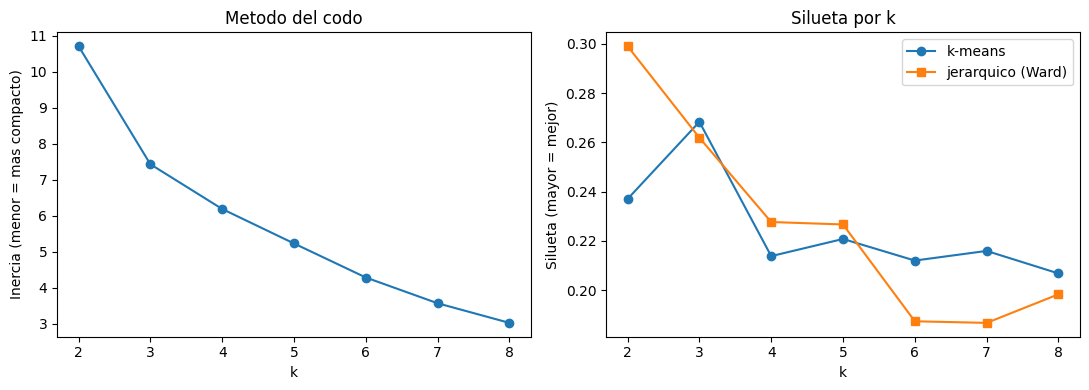

In [5]:
ks = range(2, 9)
inercias, sil_km, sil_hc = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    hc = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X)
    inercias.append(km.inertia_)
    sil_km.append(silhouette_score(X, km.labels_))
    sil_hc.append(silhouette_score(X, hc.labels_))

res = pd.DataFrame({'k': list(ks), 'inercia': np.round(inercias, 2),
                    'silueta_kmeans': np.round(sil_km, 3),
                    'silueta_ward': np.round(sil_hc, 3)})
print(res.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inercias, 'o-', color='#1f77b4')
ax[0].set_xlabel('k'); ax[0].set_ylabel('Inercia (menor = mas compacto)')
ax[0].set_title('Metodo del codo')
ax[1].plot(list(ks), sil_km, 'o-', label='k-means', color='#1f77b4')
ax[1].plot(list(ks), sil_hc, 's-', label='jerarquico (Ward)', color='#ff7f0e')
ax[1].set_xlabel('k'); ax[1].set_ylabel('Silueta (mayor = mejor)')
ax[1].set_title('Silueta por k'); ax[1].legend()
plt.tight_layout(); plt.show()

**Lectura honesta:** el codo es gradual (no hay un salto claro) y la silueta máxima es ~0,27, una **separación modesta**: los distritos no forman grupos muy compactos y alejados. Dentro de esa modestia, k = 3 es donde la silueta es máxima para k-means (0,268); con Ward el máximo está en k = 2 (0,299) y k = 3 es la segunda opción (0,262), así que **k = 3 es el candidato provisional** para este baseline, no un número de grupos validado. k = 4 queda como alternativa a discutir.

Tener 21 filas no impide obtener una silueta alta. Aquí el valor absoluto sí advierte de solapamiento; la comparación entre k ayuda a elegir un candidato, pero no demuestra que existan grupos naturales.

## 3. Baseline: k-means con k = 3

In [6]:
k_final = 3
km = KMeans(n_clusters=k_final, n_init=50, random_state=42).fit(X)
df['cluster'] = km.labels_

# nombres de trabajo segun el perfil que sale abajo (provisionales)
nombres = {0: 'Denso y vulnerable', 1: 'Acomodado y envejecido', 2: 'Periferico y disperso'}
df['cluster_nombre'] = df['cluster'].map(nombres)

for c in range(k_final):
    d = df[df.cluster == c]
    print(f"Cluster {c} - {nombres[c]} ({len(d)} distritos):")
    print('  ' + ', '.join(d['distrito'].str.title()))
    print()

Cluster 0 - Denso y vulnerable (10 distritos):
  Centro, Arganzuela, Tetuan, Latina, Carabanchel, Usera, Puente De Vallecas, Ciudad Lineal, Villaverde, San Blas-Canillejas

Cluster 1 - Acomodado y envejecido (6 distritos):
  Retiro, Salamanca, Chamartin, Chamberi, Moncloa-Aravaca, Moratalaz

Cluster 2 - Periferico y disperso (5 distritos):
  Fuencarral-El Pardo, Hortaleza, Villa De Vallecas, Vicalvaro, Barajas



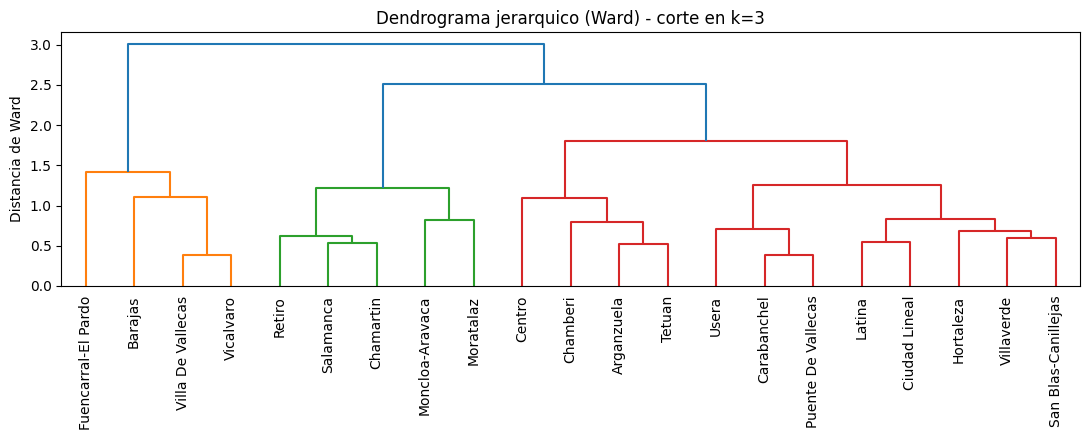

In [7]:
# dendrograma Ward: otra forma de ver la misma estructura
Z = linkage(X, method='ward')
plt.figure(figsize=(11, 4.5))
dendrogram(Z, labels=df['distrito'].str.title().tolist(), leaf_rotation=90,
           color_threshold=Z[-(k_final-1), 2])
plt.title('Dendrograma jerarquico (Ward) - corte en k=3')
plt.ylabel('Distancia de Ward')
plt.margins(y=0.08)
plt.tight_layout(); plt.show()

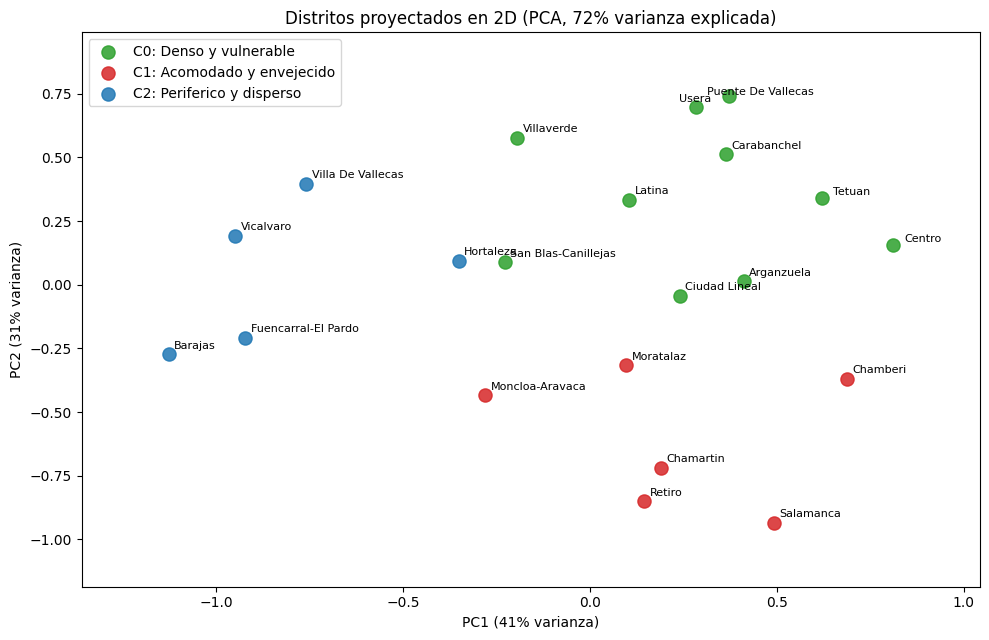

In [8]:
# vista 2D (PCA) coloreada por grupo: PCA solo para dibujar, no para decidir
pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(X)
fig, ax = plt.subplots(figsize=(10, 6.5))
colores = ['#2ca02c', '#d62728', '#1f77b4']
for c in range(k_final):
    m = df.cluster.to_numpy() == c
    ax.scatter(P[m, 0], P[m, 1], s=90, color=colores[c], label=f'C{c}: {nombres[c]}', alpha=0.85)
offsets = {'PUENTE DE VALLECAS': (8, 8), 'USERA': (-36, -4), 'CENTRO': (8, 2), 'TETUAN': (8, 2)}
for i, d in enumerate(df['distrito']):
    ax.annotate(d.title(), (P[i, 0], P[i, 1]), fontsize=8,
                xytext=offsets.get(d, (4, 4)), textcoords='offset points')
var_exp = pca.explained_variance_ratio_.sum() * 100
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% varianza)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% varianza)')
ax.set_title(f'Distritos proyectados en 2D (PCA, {var_exp:.0f}% varianza explicada)')
ax.margins(x=0.12, y=0.15)  # margen para que las etiquetas no queden recortadas
ax.legend()
plt.tight_layout(); plt.show()

## 4. Robustez del baseline (lo que aguanta y lo que no)

Antes de enseñar los perfiles, tres comprobaciones sobre la partición k = 3:

- **Sin Centro** (distrito atípico: su tasa de activaciones por 1.000 hab es aproximadamente el doble que la del segundo, ya vimos en el EDA que puede recoger demanda de visitantes y ocio nocturno, hipótesis que estos datos no permiten confirmar).
- **Sin los 4 distritos con valores imputados** en las variables usadas: la limpieza socioeconómica rellenó 10 huecos con la media de los 3 distritos más parecidos (kNN, k=3), una estimación metodológica, no un dato observado. De las variables del clustering, tocan la renta de Retiro y Ciudad Lineal, el % de mayores de 65 de Chamartín y Ciudad Lineal, y los centros de salud de San Blas-Canillejas.
- **Otras 19 semillas** para k-means (misma k y mismos datos).

In [9]:
from sklearn.metrics import adjusted_rand_score

# A) sin Centro
mA = df.distrito != 'CENTRO'
kmA = KMeans(n_clusters=3, n_init=50, random_state=42).fit(X[mA.to_numpy()])
ariA = adjusted_rand_score(df.loc[mA, 'cluster'], kmA.labels_)

# B) sin los 4 distritos con celdas imputadas en las variables usadas
afectados = ['RETIRO', 'CIUDAD LINEAL', 'CHAMARTIN', 'SAN BLAS-CANILLEJAS']
mB = ~df.distrito.isin(afectados)
kmB = KMeans(n_clusters=3, n_init=50, random_state=42).fit(X[mB.to_numpy()])
ariB = adjusted_rand_score(df.loc[mB, 'cluster'], kmB.labels_)

# C) 19 semillas distintas
aris_seed = [adjusted_rand_score(df['cluster'],
             KMeans(n_clusters=3, n_init=50, random_state=s).fit(X).labels_)
             for s in range(1, 20)]

print(f"A) Sin Centro:                        ARI = {ariA:.2f} con el baseline")
print(f"B) Sin distritos con imputaciones:    ARI = {ariB:.2f} con el baseline")
print(f"C) 19 semillas distintas:             ARI min = {min(aris_seed):.2f}, mediana = {np.median(aris_seed):.2f}")

# D) sensibilidad a retirar los dos ejes completos: no es una prueba solo de imputacion.
variables_sin_ejes = [v for v in variables if v not in ['renta_media_hogar', 'pct_mayores_65']]
km_sin_ejes = KMeans(n_clusters=3, n_init=50, random_state=42).fit(nrm[variables_sin_ejes])
ari_sin_ejes = adjusted_rand_score(df['cluster'], km_sin_ejes.labels_)
print(f'D) Sin renta y porcentaje de mayores: ARI = {ari_sin_ejes:.2f}')

A) Sin Centro:                        ARI = 1.00 con el baseline
B) Sin distritos con imputaciones:    ARI = 1.00 con el baseline
C) 19 semillas distintas:             ARI min = 0.85, mediana = 0.85
D) Sin renta y porcentaje de mayores: ARI = 0.46


**Resultado:** sin Centro y sin los distritos con imputaciones la partición se mantiene igual salvo reordenación de etiquetas (ARI = 1,00), y con las otras 19 semillas el ARI mínimo y mediano es 0,85. Es decir, **en estas pruebas concretas, al mantener el escalado original y k = 3, las asignaciones son bastante estables**, aunque ya no perfectas con todas las semillas. No demuestra independencia general de los datos imputados ni estabilidad ante cualquier cambio de muestra.

Lo que sí hay que decir con honestidad:

- La separación sigue siendo **modesta** (silueta global próxima a 0,27 en el baseline). Estos grupos son una forma razonable de resumir los distritos, no fronteras duras.
- Si quitamos del clustering los ejes económico y de edad enteros (renta y % de mayores de 65), la partición cambia bastante (ARI ≈ 0,46). Es esperable: esos ejes son gran parte del contenido del caso. Pero significa que el resultado **depende de variables que llevan 5 celdas imputadas (estimaciones, no observaciones)**; la sensibilidad se reporta en las pruebas anteriores.
- **La tabla mezcla todos los tipos de emergencia** sin distinguir: ahora todas las activaciones llevan el tipo y la prioridad del catálogo (39 códigos), pero no hay segmentación por tipo de emergencia todavía. Y ojo con `pct_prioridad_alta`: es la gravedad típica del tipo según el catálogo, no la prioridad registrada en cada evento.
- La población de Barajas es una estimación (densidad x superficie), no un dato real, y de ella depende su tasa de activaciones por habitante.

## 5. Perfil provisional de cada grupo (valores reales, no normalizados)

In [10]:
cols_desc = ['renta_media_hogar', 'tasa_paro', 'indice_vulnerabilidad', 'pct_mayores_65',
             'pct_extranjeros', 'densidad_hab_km2', 'activaciones_por_1000hab',
             'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
perfil = df.groupby('cluster_nombre')[cols_desc].mean().round(2)
perfil.loc['MEDIA DE LOS 21 DISTRITOS'] = df[cols_desc].mean().round(2)
print(perfil.T.to_string())

cluster_nombre              Acomodado y envejecido  Denso y vulnerable  Periferico y disperso  MEDIA DE LOS 21 DISTRITOS
renta_media_hogar                         56254.17            33037.20               41601.80                   41709.81
tasa_paro                                     7.18               12.64                  10.38                      10.54
indice_vulnerabilidad                         0.26                0.59                   0.46                       0.46
pct_mayores_65                               23.90               18.14                  14.64                      18.95
pct_extranjeros                              11.63               20.22                  15.10                      16.55
densidad_hab_km2                          18742.28            17689.91                2651.92                   14410.11
activaciones_por_1000hab                     47.39               50.43                  32.82                      45.37
pct_prioridad_alta              

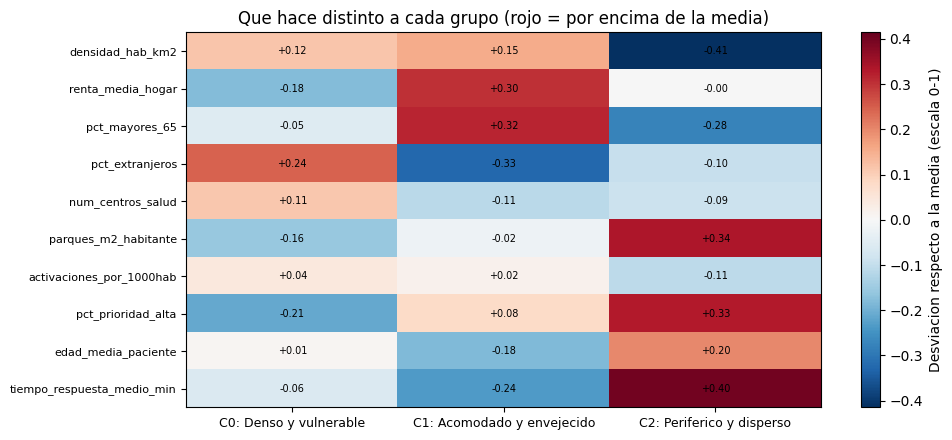

In [11]:
# que variables hacen distinto a cada grupo (media normalizada vs media global)
med_global = nrm[variables].mean()
medias = nrm[variables].assign(cluster=df.cluster).groupby('cluster').mean()
dif = (medias - med_global)

plt.figure(figsize=(10, 4.5))
im = plt.imshow(dif.T, cmap='RdBu_r', vmin=-np.abs(dif.to_numpy()).max(), vmax=np.abs(dif.to_numpy()).max(), aspect='auto')
plt.colorbar(im, label='Desviacion respecto a la media (escala 0-1)')
plt.yticks(range(len(variables)), variables, fontsize=8)
plt.xticks(range(k_final), [f'C{c}: {nombres[c]}' for c in range(k_final)], fontsize=9)
for i in range(len(variables)):
    for c in range(k_final):
        plt.text(c, i, f'{dif.T.iloc[i, c]:+.2f}', ha='center', va='center', fontsize=7)
plt.title('Que hace distinto a cada grupo (rojo = por encima de la media)')
plt.tight_layout(); plt.show()

**Lectura provisional de los tres grupos** (resultado histórico del baseline; el cierre está en segmentacion_final_distritos.ipynb):

- **C0 - Denso y vulnerable** (Centro, Arganzuela, Tetuán, Latina, Carabanchel, Usera, Puente de Vallecas, Ciudad Lineal, Villaverde, San Blas-Canillejas): renta baja (33.000 € frente a 41.700 € de media), paro alto (12,6 %), más población extranjera (20,2 %) y donde se concentra la mayor parte de las activaciones registradas.
- **C1 - Acomodado y envejecido** (Retiro, Salamanca, Chamartín, Chamberí, Moncloa-Aravaca, Moratalaz): renta muy por encima de la media (56.300 €), paro bajo (7,2 %), el más envejecido (23,9 % de mayores de 65) y los mejores tiempos medios de respuesta (7,0 min).
- **C2 - Periférico y disperso** (Fuencarral-El Pardo, Hortaleza, Villa de Vallecas, Vicálvaro, Barajas): densidad muy baja (2.652 hab/km² frente a 14.410 de media), los peores tiempos medios de respuesta (9,7 min frente a 8,0 de media distrital; Barajas 10,7, Villa de Vallecas 10,0 y Vicálvaro 9,8 son los tres peores) y el mix de prioridad de catálogo más alto (46 % de tipos de prioridad alta, frente a 37 % en el C0). **No sabemos por qué**: podría deberse a distancias, cobertura, tráfico u otras causas; con estos datos no se puede distinguir, así que queda como observación descriptiva, no como explicación.

Cambio respecto a la versión anterior de la tabla: Moncloa-Aravaca pasa del grupo periférico al acomodado (su silueta ya no es negativa). Ojo con Centro: su tasa de activaciones por 1.000 hab (141,5) es más del doble que la del segundo distrito, y podría recoger demanda de visitantes y ocio nocturno; no podemos separar residentes y visitantes con estas tablas. Forma parte del C0, pero es un distrito atípico dentro de él (de ahí la comprobación A de la sección 4).

## 6. Oferta y demanda por grupo: solo descripción, sin conclusiones de cobertura

                        distritos  activaciones  poblacion  bases_samur_catalogadas  pct_activaciones  activaciones_por_1000hab  media_distrital_respuesta_min
cluster_nombre                                                                                                                                                
Acomodado y envejecido          6         37198     771112                        2              25.5                      48.2                           7.02
Denso y vulnerable             10         89341    1866858                        9              61.2                      47.9                           7.77
Periferico y disperso           5         19427     671718                        4              13.3                      28.9                           9.72

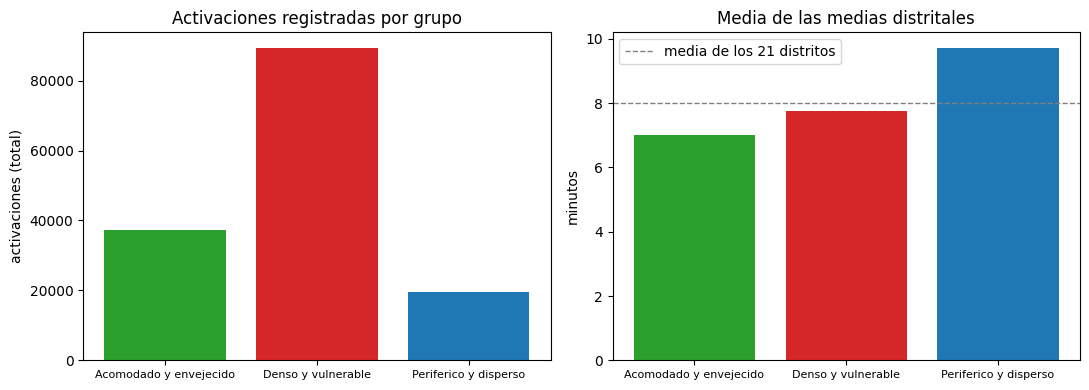

Distritos con datos de recursos no utilizados para definir clusters:
          distrito         cluster_nombre
   MONCLOA-ARAVACA Acomodado y envejecido
PUENTE DE VALLECAS     Denso y vulnerable
 VILLA DE VALLECAS  Periferico y disperso


In [12]:
desc = df.groupby('cluster_nombre').agg(
    distritos=('distrito', 'count'),
    activaciones=('n_activaciones', 'sum'),
    poblacion=('poblacion', 'sum'),
    bases_samur_catalogadas=('num_bases_samur', 'sum'))
desc['pct_activaciones'] = (desc['activaciones'] / desc['activaciones'].sum() * 100).round(1)
desc['activaciones_por_1000hab'] = (desc['activaciones'] / desc['poblacion'] * 1000).round(1)
desc['media_distrital_respuesta_min'] = df.groupby('cluster_nombre')['tiempo_respuesta_medio_min'].mean().round(2)
print(desc.to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
colores_ord = ['#2ca02c', '#d62728', '#1f77b4']
ax[0].bar(desc.index, desc['activaciones'], color=colores_ord)
ax[0].set_title('Activaciones registradas por grupo'); ax[0].set_ylabel('activaciones (total)')
ax[0].tick_params(axis='x', labelsize=8)
ax[1].bar(desc.index, desc['media_distrital_respuesta_min'], color=colores_ord)
ax[1].axhline(df['tiempo_respuesta_medio_min'].mean(), color='grey', ls='--', lw=1, label='media de los 21 distritos')
ax[1].set_title('Media de las medias distritales'); ax[1].set_ylabel('minutos'); ax[1].legend()
ax[1].tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()

print('Distritos con datos de recursos no utilizados para definir clusters:')
desconocidos = df[df[['unidades_samur', 'num_hospitales_cat', 'camas_hospital']].isna().any(axis=1)]
print(desconocidos[['distrito', 'cluster_nombre']].to_string(index=False))

Lo único que se puede decir:

- El **C0** concentra la mayoría de las activaciones registradas (~89.300, el 61 %) y una tasa por habitante alta (47,9 por 1.000 hab, inflada por Centro).
- El **C1** tiene una tasa parecida (48,2) con solo 2 bases catalogadas para sus 6 distritos. No se puede interpretar como falta de cobertura: no sabemos las unidades reales, sus áreas de servicio ni cómo cubren los distritos vecinos.
- El **C2** tiene la tasa por habitante más baja (28,9) y, como se ha dicho, los peores tiempos medios de respuesta, sin que sepamos la causa.

La respuesta por grupo se calcula dando el mismo peso a cada distrito. **No es la media de todas sus activaciones**: para obtenerla harían falta los conteos de respuestas válidas por distrito, porque hay tiempos desconocidos. No se ajusta por gravedad, distancia o tráfico.

## 7. Diagnóstico por distrito: dónde se solapan los grupos

La silueta global puede ocultar asignaciones dudosas. Se calcula la silueta individual con la misma distancia euclídea que usa el clustering: cerca de 1 indica mayor separación, cerca de 0 indica frontera y por debajo de 0 indica que el distrito está, en promedio, más cerca de otro grupo. No es una probabilidad ni una medida de confianza estadística.

Se muestra además el Ward de k = 3 tras alinear sus etiquetas con k-means. Esa coincidencia compara dos algoritmos sobre los mismos datos: no es validación externa. No se descarta ningún distrito por tener silueta baja.

 distrito_id            distrito  cluster         cluster_nombre  silueta  cluster_ward_alineado  coincide_ward
          16           HORTALEZA        2  Periferico y disperso   -0.026                      0          False
          15       CIUDAD LINEAL        0     Denso y vulnerable    0.057                      0           True
          20 SAN BLAS-CANILLEJAS        0     Denso y vulnerable    0.065                      0           True
           2          ARGANZUELA        0     Denso y vulnerable    0.121                      0           True
           7            CHAMBERI        1 Acomodado y envejecido    0.128                      0          False
           9     MONCLOA-ARAVACA        1 Acomodado y envejecido    0.148                      1           True
           1              CENTRO        0     Denso y vulnerable    0.155                      0           True
          14           MORATALAZ        1 Acomodado y envejecido    0.167                      1        

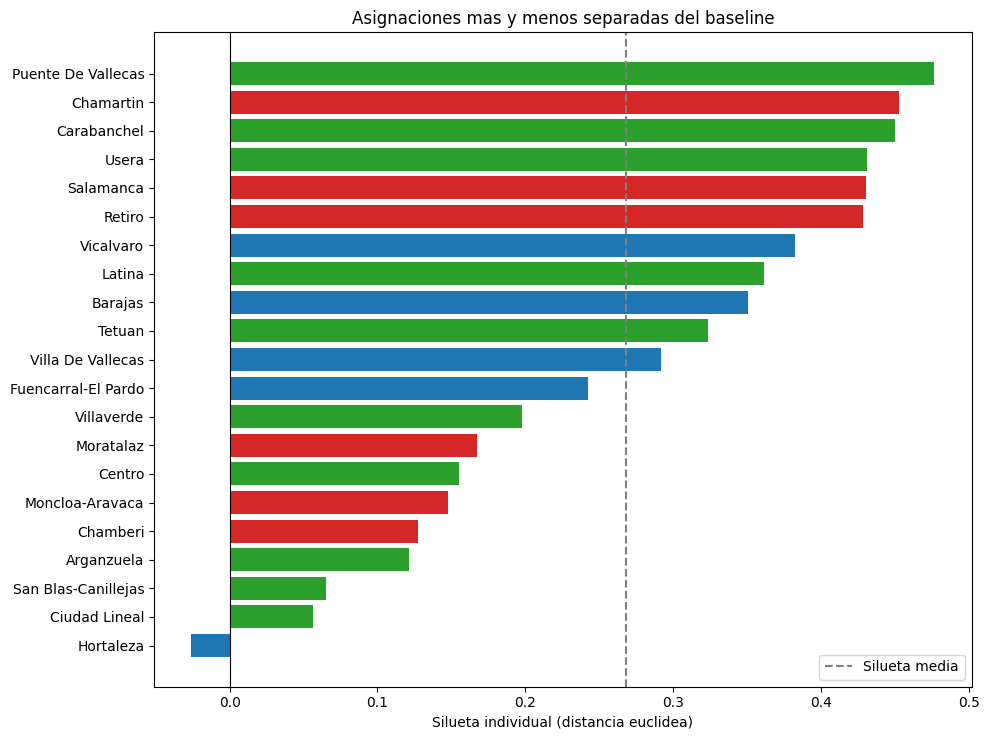

Menor separacion: Hortaleza, Ciudad Lineal, San Blas-Canillejas
Leer estos casos junto con sus valores reales; no son errores automaticos.


In [13]:
from sklearn.metrics import silhouette_samples
from scipy.optimize import linear_sum_assignment

sil_individual = silhouette_samples(X, km.labels_)
ward = AgglomerativeClustering(n_clusters=k_final, linkage='ward').fit_predict(X)
contingencia = pd.crosstab(km.labels_, ward).reindex(index=range(k_final), columns=range(k_final), fill_value=0)
fila, columna = linear_sum_assignment(-contingencia.to_numpy())
equivalencias = dict(zip(columna, fila))
ward_alineado = np.array([equivalencias[c] for c in ward])

diagnostico = df[['distrito_id', 'distrito', 'cluster', 'cluster_nombre']].copy()
diagnostico['silueta'] = sil_individual
diagnostico['cluster_ward_alineado'] = ward_alineado
diagnostico['coincide_ward'] = km.labels_ == ward_alineado
print(diagnostico.sort_values('silueta').to_string(index=False, float_format=lambda x: f'{x:.3f}'))
print(f'\nSilueta global: {sil_individual.mean():.3f}')
print(f'Distritos con silueta negativa: {(sil_individual < 0).sum()} de {len(df)}')
print(f'Coincidencia KMeans-Ward: {(km.labels_ == ward_alineado).sum()} de {len(df)}')
print('ARI entre metodos:', round(adjusted_rand_score(km.labels_, ward), 3))

orden = diagnostico.sort_values('silueta')
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(orden.distrito.str.title(), orden.silueta,
        color=[colores[c] for c in orden.cluster])
ax.axvline(0, color='black', lw=0.8)
ax.axvline(sil_individual.mean(), color='grey', ls='--', label='Silueta media')
ax.set_xlabel('Silueta individual (distancia euclidea)')
ax.set_title('Asignaciones mas y menos separadas del baseline')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

print('Menor separacion:', ', '.join(orden.head(3).distrito.str.title()))
print('Leer estos casos junto con sus valores reales; no son errores automaticos.')

**Lectura de esta ejecución:** Hortaleza (-0,026) tiene silueta negativa y, con Chamberí (0,128, positiva pero baja), cambia de grupo con Ward. Los otros 19 distritos coinciden tras alinear las etiquetas (ARI entre métodos = 0,692). Moncloa-Aravaca, que en la versión anterior tenía silueta negativa, ya encaja en el grupo acomodado (0,148). Son casos para revisar, no motivos para borrar observaciones ni retocar k hasta que parezca mejor.

### Reutilizar resultados sin copiar etiquetas a mano

La siguiente celda prepara dos tablas en memoria: una fila por distrito con su asignación y diagnóstico, y los perfiles medios en valores reales. La exportación es opcional: por defecto **no crea archivos ni cambia las entradas**. Para reutilizarlos en un mapa o en la memoria, cambia `exportar` a `True`; se guardarán en `resultados_clustering/` dentro de la carpeta del caso. Las etiquetas de grupo solo sirven para esta ejecución y no deben interpretarse como un orden de gravedad.

In [14]:
asignaciones = df.merge(
    diagnostico[['distrito_id', 'silueta', 'cluster_ward_alineado', 'coincide_ward']],
    on='distrito_id', how='left', validate='one_to_one')
perfiles = df.groupby(['cluster', 'cluster_nombre'])[cols_desc].mean().reset_index()
assert len(asignaciones) == 21 and asignaciones['silueta'].notna().all()
exportar = False
if exportar:
    salida = carpeta / 'resultados_clustering'
    salida.mkdir(exist_ok=True)
    asignaciones.to_csv(salida / 'distritos_con_cluster.csv', index=False)
    perfiles.to_csv(salida / 'perfiles_cluster.csv', index=False)
    print('Resultados descriptivos guardados en', salida)
else:
    print('Tablas asignaciones y perfiles listas en memoria. No se han creado CSV nuevos.')

Tablas asignaciones y perfiles listas en memoria. No se han creado CSV nuevos.


## 8. Limitaciones y siguientes pasos

**Limitaciones (resumen de lo ya dicho):**

- Baseline exploratorio con separación modesta (silueta ~0,27); k = 3 es candidato provisional, no validado.
- En las pruebas realizadas, con escalado fijo, se mantienen las asignaciones comparables al quitar Centro, quitar los distritos imputados y cambiar la semilla, pero depende de los ejes económico y de edad, que llevan 5 celdas imputadas (estimaciones, no observaciones).
- La tabla mezcla todos los tipos de emergencia (ya con el criterio del catálogo aplicado en la limpieza); no hay segmentación por tipo.
- La oferta está incompleta (VALLECAS ambiguo, camas sin dato) y las bases catalogadas no miden cobertura real: no hay ninguna conclusión operacional.
- Es un modelo descriptivo, no predictivo: no dice qué pasará, solo cómo se parecen los distritos hoy. No se ha medido ningún ahorro.

**Continuación completada:** el notebook final incluye comparación de k, Ward, DBSCAN, sensibilidad, diagnóstico de edad y análisis socioeconómico. Este archivo conserva el baseline 10D como histórico.

In [15]:
import sys, sklearn, scipy, matplotlib
print('python', sys.version.split()[0])
print('pandas', pd.__version__)
print('numpy', np.__version__)
print('scikit-learn', sklearn.__version__)
print('scipy', scipy.__version__)
print('matplotlib', matplotlib.__version__)
print('\nk-means: n_init=50, random_state=42 en el baseline y las comparaciones de k; las pruebas de semillas cambian random_state')

python 3.10.12
pandas 2.3.3
numpy 2.2.6
scikit-learn 1.7.2
scipy 1.15.3
matplotlib 3.10.9

k-means: n_init=50, random_state=42 en el baseline y las comparaciones de k; las pruebas de semillas cambian random_state


## E. Exploración socioeconómica: gráficos y mapas completos

Se conserva el recorrido completo, incluidas sus decisiones y limitaciones históricas. Se reejecuta sobre las mismas tablas corregidas, sin cambiar sus algoritmos. Las conclusiones vigentes y la elección 9D están en la sección F. Las referencias a otro notebook final se entienden ahora como referencias a esa sección de este mismo archivo. Los gráficos de la exploración se guardan en `graficos_recorrido_eda/`, sin sobrescribir exportaciones antiguas.

In [16]:
import matplotlib.pyplot as plt
plt.close('all')
plt.rcdefaults()

# Exploración de activaciones y distritos (caso 1.3): gráficos y mapas

Análisis exploratorio de los datos limpios del caso 1.3, pensado para la presentación intermedia: de aquí salen los números y los gráficos para contar el problema (qué pasa con las emergencias en Madrid), el volumen de datos y las primeras cosas que vemos al cruzar la demanda del SAMUR con el perfil social de los distritos.

Esta sección histórica reúne todo el análisis gráfico: los 12 gráficos de las secciones 1 a 9 y los 3 mapas de la sección 10. Cada gráfico lleva su explicación: qué se pregunta, qué se ve y qué no se puede concluir. La sección 11 resume los insights para los slides y la 12 recoge las limitaciones.

- **Datos usados:** `activaciones_limpio.csv` (146.567 activaciones del SAMUR en 2024, ya limpio en `data_clean/`, con el tipo y la prioridad del catálogo aplicados), `tabla_distritos.csv` (21 distritos con perfil social, demanda y oferta, en `1_3_clustering/`) y `tipos_emergencia_clean.csv` (catálogo canónico de tipos del caso 2.2, en `data_clean/`; la sección 4 solo añade la categoría, porque el tipo ya viene cruzado de la limpieza). Para los mapas, además, los límites oficiales de los distritos del Ayuntamiento de Madrid (se descargan al ejecutar).
- **Qué hace:** solo explorar y visualizar. No modifica ningún CSV ni rehace la limpieza.
- **Gráficos:** cada uno se guarda como PNG en la subcarpeta `graficos_recorrido_eda/`, listo para meter en los slides.
- **Ojo al interpretar:** son 21 distritos y las correlaciones entre distritos no prueban causalidad. Los mapas son descriptivos: los terciles del mapa bivariante no son el clustering. Las dudas concretas están apuntadas al final (sección "Limitaciones").

**Nota de versión17/11:** exploración histórica. Las decisiones finales, correcciones hospitalarias, exclusión definitiva de oferta, pruebas de algoritmo y límites actualizados están documentados y ejecutados en la sección F de este notebook; no se interpretan las cifras de camas del catálogo como capacidad comparable. No se asignan unidades ambiguas ni se usa hospital receptor para localizar avisos.

## 0. Carga de datos

Leemos los CSV ya limpios (los que salen de los notebooks de limpieza y de cruces), para que todo lo que se vea aquí sea reproducible desde el repo. Las rutas de esta versión integrada leen `data_clean/` y `1_3_clustering/` desde la raíz del repositorio o la carpeta del caso.

Decisión: para los análisis por hora usamos `hora_solicitud` (cuándo pide ayuda la gente, que es lo que interesa para planificar). Las 1.579 filas sin hora de solicitud se excluyen solo de esos gráficos, no del resto.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
FIG_EDA = carpeta / 'graficos_recorrido_eda'
FIG_EDA.mkdir(exist_ok=True)

def cargar(nombre, carpetas):
    for c in carpetas:
        ruta = Path(c) / nombre
        if ruta.exists():
            return pd.read_csv(ruta)
    raise FileNotFoundError(nombre)

act = cargar('activaciones_limpio.csv', [raiz / 'data_clean', carpeta])
tabla = cargar('tabla_distritos.csv', [carpeta])

# Hora de la solicitud (0-23) para los análisis por franja horaria
act['hora'] = pd.to_datetime(act['hora_solicitud'], format='%H:%M:%S', errors='coerce').dt.hour

MESES = ['ENERO','FEBRERO','MARZO','ABRIL','MAYO','JUNIO','JULIO','AGOSTO','SEPTIEMBRE','OCTUBRE','NOVIEMBRE','DICIEMBRE']

ROJO = '#D62612'      # acento SAMUR
GRIS = '#9aa0a6'      # contexto
AZUL = '#1a73e8'      # secundario

plt.rcParams.update({
    'figure.figsize': (10, 5.6), 'figure.dpi': 170,
    'font.size': 13, 'axes.titlesize': 17, 'axes.titleweight': 'bold',
    'axes.labelsize': 13, 'axes.edgecolor': '#cccccc',
    'axes.grid': True, 'grid.color': '#e8e8e8', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'figure.facecolor': 'white',
})

print(f"Activaciones: {len(act):,}".replace(',', '.'))
print(f"Distritos: {len(tabla)}")
print(f"Filas sin hora de solicitud: {act['hora'].isna().sum():,} (se excluyen solo de los análisis por hora)".replace(',', '.'))

Activaciones: 146.567
Distritos: 21
Filas sin hora de solicitud: 1.422 (se excluyen solo de los análisis por hora)


## 1. El volumen: más de 150.000 activaciones en un año

La presentación pide que se entienda el volumen de datos, así que empezamos por ahí. Contamos activaciones por mes para ver si la demanda es estable o tiene temporadas.

Decisión: como 2024 es bisiesto, el dato por día se calcula sobre 366 días.

Total 2024: 146.567 activaciones
Media: 400 al día, unas 17 cada hora
Mes con más actividad diaria: JUNIO (438/día)
Mes con menos: AGOSTO (338/día)
Agosto tiene un 23% menos actividad diaria que junio


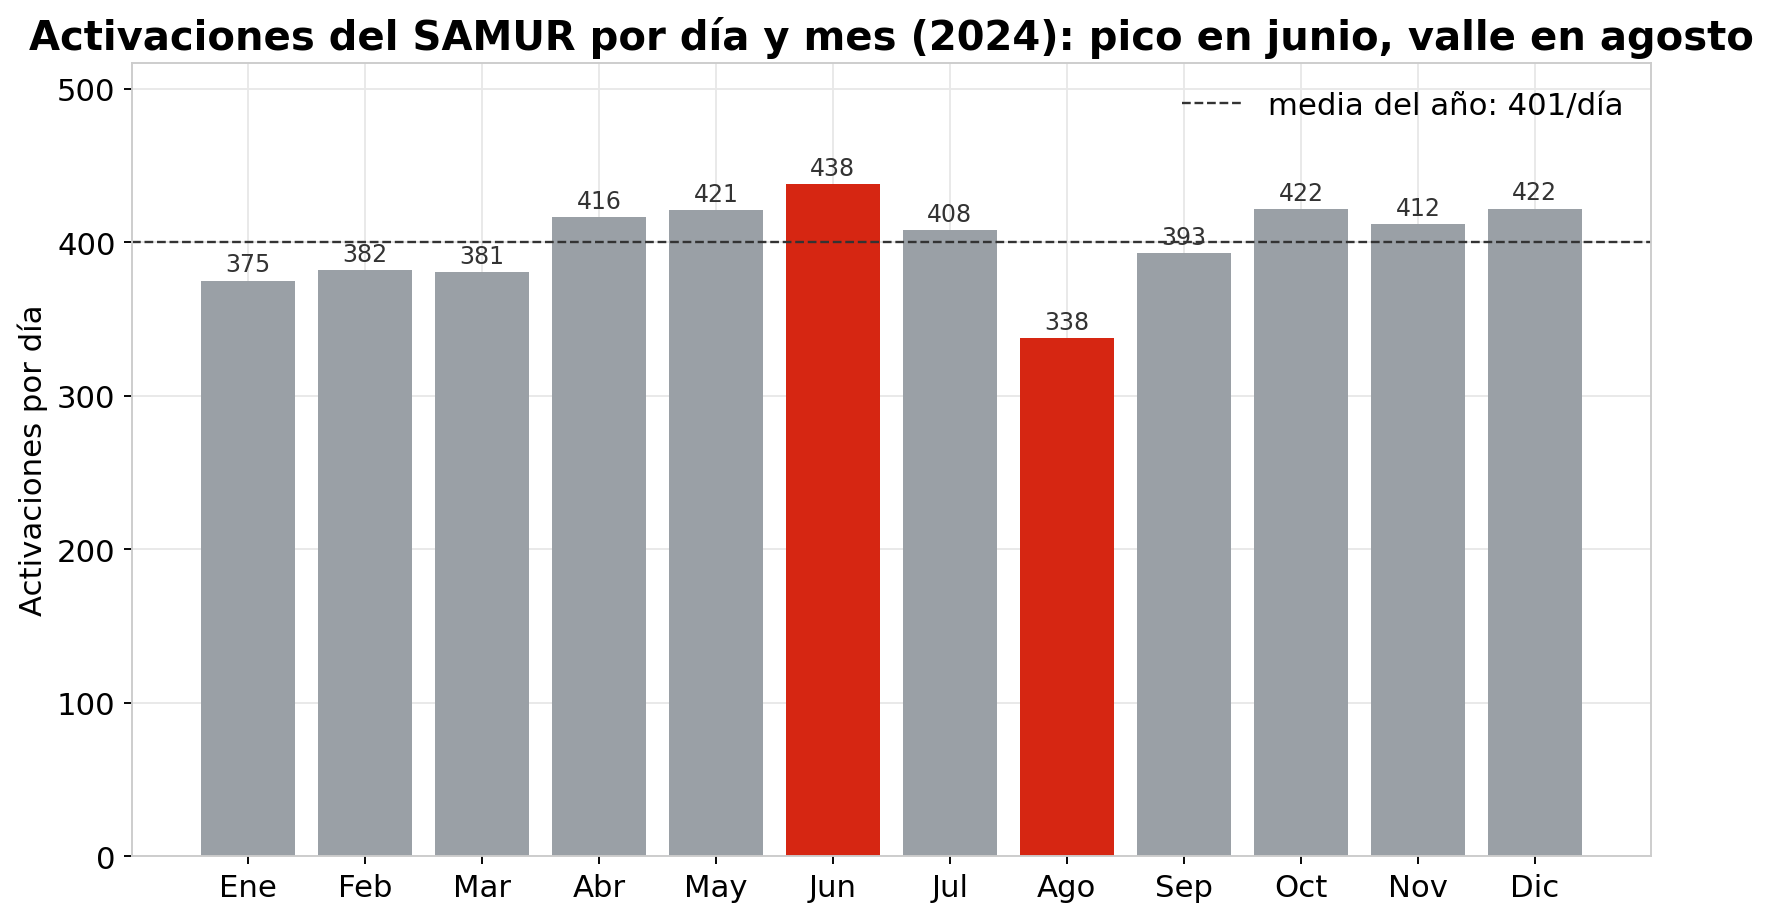

In [18]:
total = len(act)
por_dia = total / 366
print(f"Total 2024: {total:,} activaciones".replace(',', '.'))
print(f"Media: {por_dia:.0f} al día, unas {por_dia/24:.0f} cada hora")

# Los meses no tienen los mismos días, así que comparamos activaciones POR DÍA
dias_mes = pd.Series([31,29,31,30,31,30,31,31,30,31,30,31], index=MESES)  # 2024 bisiesto
por_mes = act['mes'].value_counts().reindex(MESES)
por_dia_mes = por_mes / dias_mes
print(f"Mes con más actividad diaria: {por_dia_mes.idxmax()} ({por_dia_mes.max():.0f}/día)")
print(f"Mes con menos: {por_dia_mes.idxmin()} ({por_dia_mes.min():.0f}/día)")
print(f"Agosto tiene un {(1-por_dia_mes['AGOSTO']/por_dia_mes['JUNIO'])*100:.0f}% menos actividad diaria que junio")

fig, ax = plt.subplots()
colores = [ROJO if m in (por_dia_mes.idxmax(), por_dia_mes.idxmin()) else GRIS for m in MESES]
ax.bar(range(12), por_dia_mes.values, color=colores)
ax.axhline(por_dia_mes.mean(), color='#333333', linestyle='--', linewidth=1, label=f'media del año: {por_dia_mes.mean():.0f}/día')
ax.set_xticks(range(12))
ax.set_xticklabels([m[:3].title() for m in MESES])
ax.set_ylabel('Activaciones por día')
ax.set_title('Activaciones del SAMUR por día y mes (2024): pico en junio, valle en agosto')
ax.legend(frameon=False)
ax.set_ylim(0, por_dia_mes.max() * 1.18)
for i, v in enumerate(por_dia_mes.values):
    ax.text(i, v + 6, f'{v:.0f}', ha='center', fontsize=10, color='#333333')
plt.tight_layout()
plt.savefig(FIG_EDA / 'activaciones_por_mes.png', bbox_inches='tight')
plt.show()

**Lo que vemos:** unas **400 activaciones al día** de media (146.567 entre 366 días). Comparando por día (los meses no tienen los mismos días), junio es el mes con más actividad (438/día) y agosto el de menos (338/día, un 23% menos que junio). La lectura de que en agosto Madrid se vacía es una hipótesis razonable, no algo que el dato pruebe por sí solo. La demanda no es plana, así que tiene sentido estudiar cuándo hacen falta más recursos.

## 2. A qué hora pasan las cosas

Para planificar turnos importa la hora del día. Contamos activaciones por hora de solicitud y cruzamos mes × hora para comprobar si el patrón diario se mantiene todo el año o cambia con la temporada.

Hora punta: 13h (9.904 activaciones)
Hora valle: 4h (2.974 activaciones)
Entre una y otra hay 3.3x más llamadas


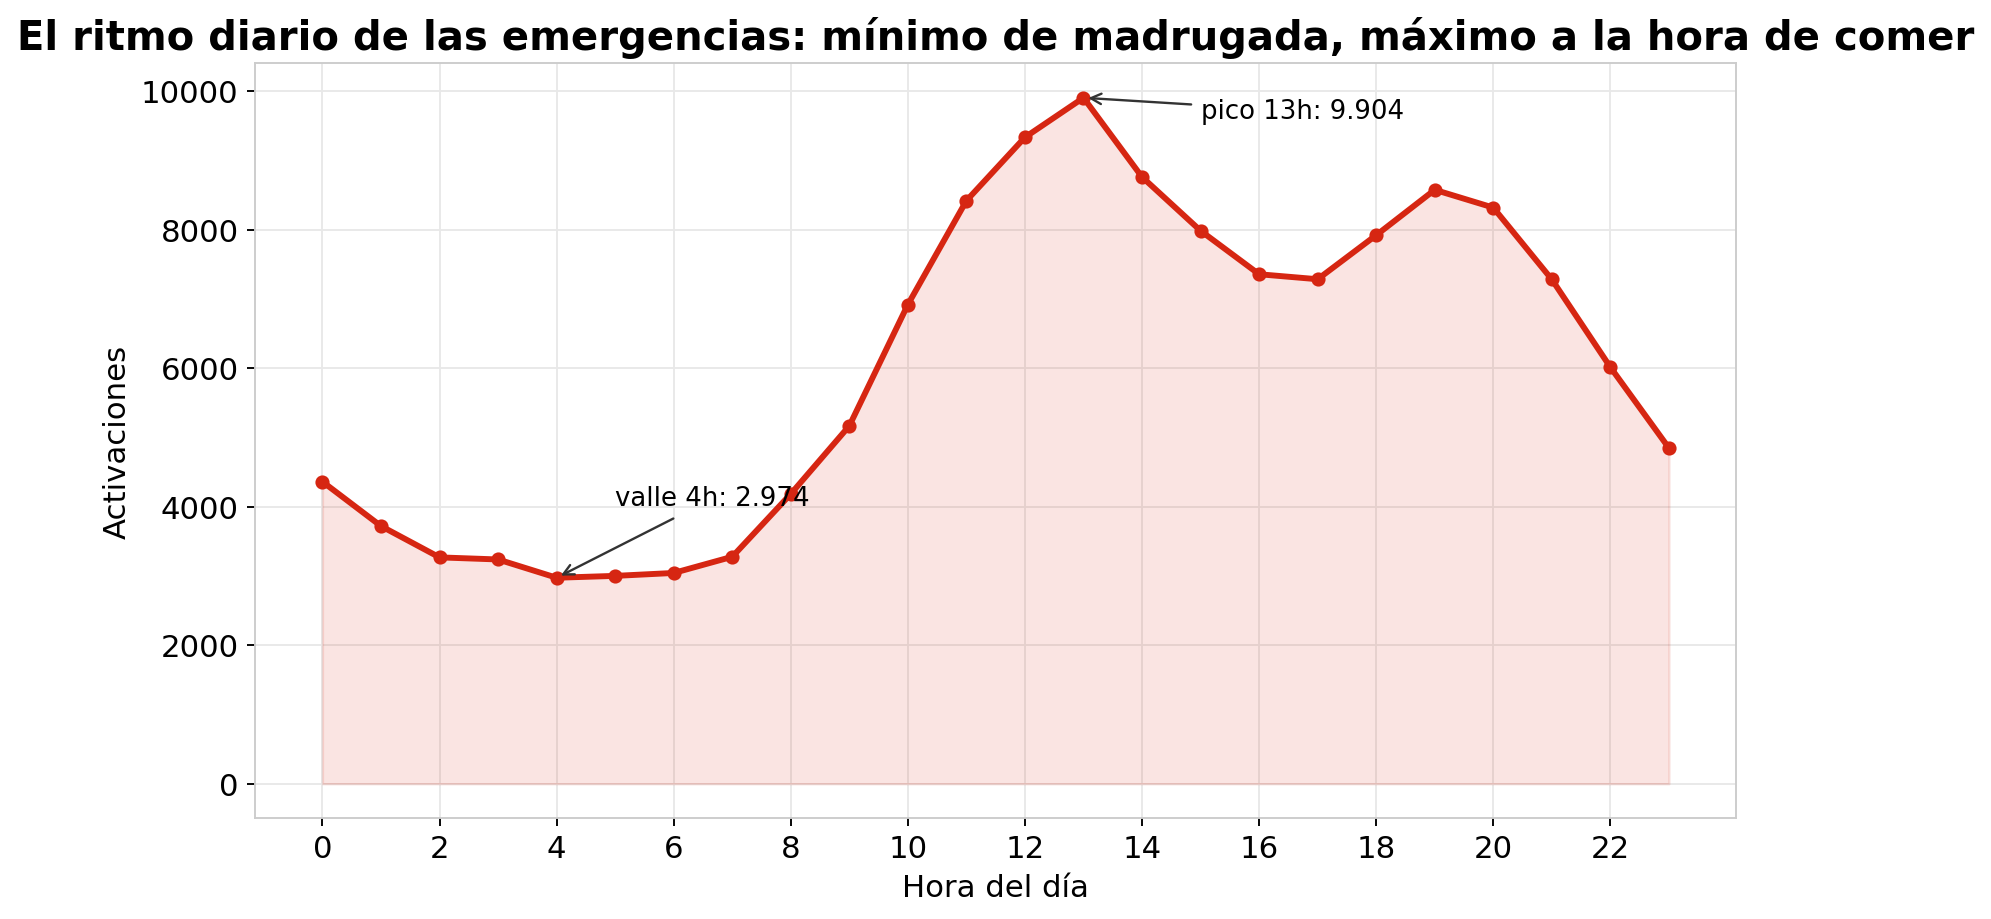

In [19]:
por_hora = act['hora'].value_counts().sort_index()
print(f"Hora punta: {int(por_hora.idxmax())}h ({por_hora.max():,} activaciones)".replace(',', '.'))
print(f"Hora valle: {int(por_hora.idxmin())}h ({por_hora.min():,} activaciones)".replace(',', '.'))
print(f"Entre una y otra hay {por_hora.max()/por_hora.min():.1f}x más llamadas")

fig, ax = plt.subplots()
ax.plot(por_hora.index, por_hora.values, color=ROJO, linewidth=2.5, marker='o', markersize=5)
ax.fill_between(por_hora.index, por_hora.values, alpha=0.12, color=ROJO)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('Hora del día')
ax.set_ylabel('Activaciones')
ax.set_title('El ritmo diario de las emergencias: mínimo de madrugada, máximo a la hora de comer')
ax.annotate(f'pico {int(por_hora.idxmax())}h: {por_hora.max():,}'.replace(',', '.'),
            xy=(por_hora.idxmax(), por_hora.max()), xytext=(15, por_hora.max()*0.97),
            arrowprops=dict(arrowstyle='->', color='#333333'), fontsize=11)
ax.annotate(f'valle {int(por_hora.idxmin())}h: {por_hora.min():,}'.replace(',', '.'),
            xy=(por_hora.idxmin(), por_hora.min()), xytext=(5, por_hora.min()*1.35),
            arrowprops=dict(arrowstyle='->', color='#333333'), fontsize=11)
plt.tight_layout()
plt.savefig(FIG_EDA / 'activaciones_por_hora.png', bbox_inches='tight')
plt.show()

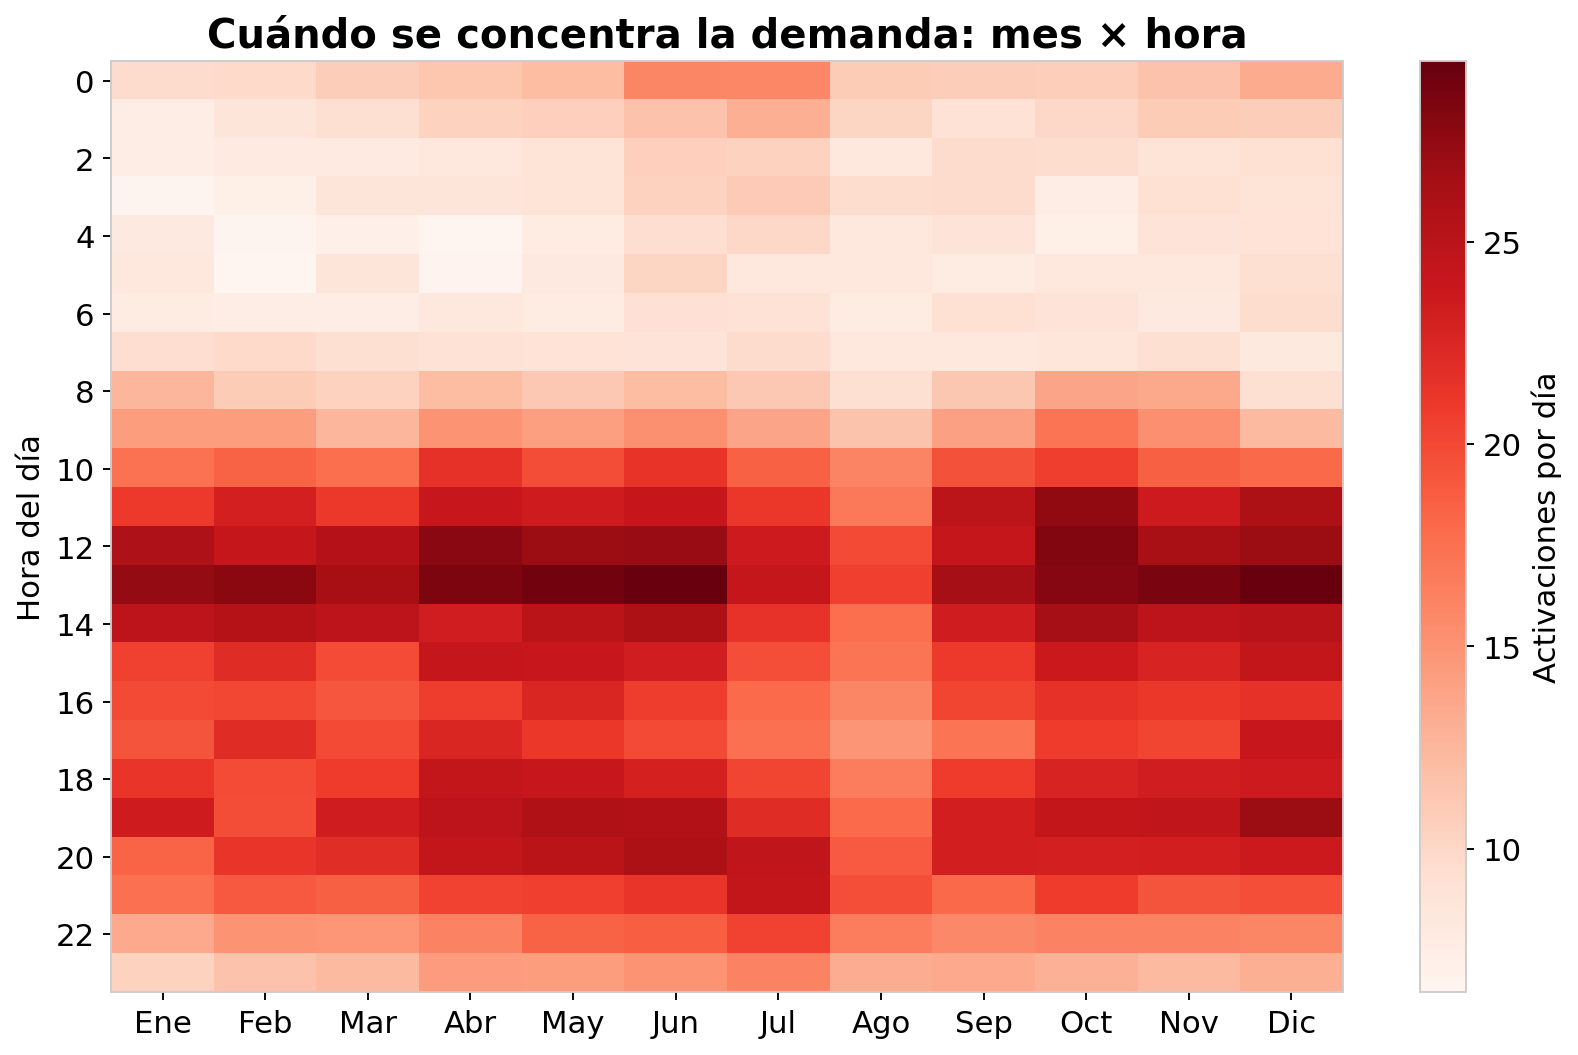

In [20]:
# Mapa de calor mes x hora: en rojo más activaciones
matriz = act.pivot_table(index='hora', columns='mes', values='activacion_id', aggfunc='count').reindex(columns=MESES)
matriz = matriz / dias_mes

fig, ax = plt.subplots(figsize=(10, 6.4))
im = ax.imshow(matriz.values, aspect='auto', cmap='Reds')
ax.set_xticks(range(12))
ax.set_xticklabels([m[:3].title() for m in MESES])
ax.set_yticks(range(0, 24, 2))
ax.set_ylabel('Hora del día')
ax.set_title('Cuándo se concentra la demanda: mes × hora')
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Activaciones por día')
ax.grid(False)
plt.tight_layout()
plt.savefig(FIG_EDA / 'heatmap_mes_hora.png', bbox_inches='tight')
plt.show()

**Lo que vemos:** la demanda baja de madrugada (mínimo sobre las 4-5h) y sube hasta el mediodía, con el pico a las **13h** (casi 10.000 activaciones en el año, 3,3 veces más que a las 4h). El mapa de calor (normalizado por días de cada mes para que sean comparables) muestra un patrón diario parecido en todos los meses: no es cosa de un mes concreto.

## 3. Composición por hora: intoxicación etílica

En el recorrido histórico se describió la madrugada en términos de ocio. La medición real aquí es el porcentaje de activaciones de cada hora por intoxicación etílica. Ese porcentaje permite comparar composición entre horas, no observar la actividad que causó la emergencia ni probar que se deba a ocio.

Se muestra porcentaje dentro de cada hora, porque de madrugada hay menos activaciones y un conteo bruto respondería otra pregunta. No se dispone de día de semana, por lo que no se separan fines de semana y laborables. Esa ausencia de día está respaldada por el correo primario del 14/10 identificado en la trazabilidad de la sección A.

Tipo nº1 de 0 a 7h: Intoxicación etílica
Intoxicación etílica a las 3h: 31% de las llamadas
Intoxicación etílica a las 12h: 3% de las llamadas
En todo el año: 10% de las activaciones


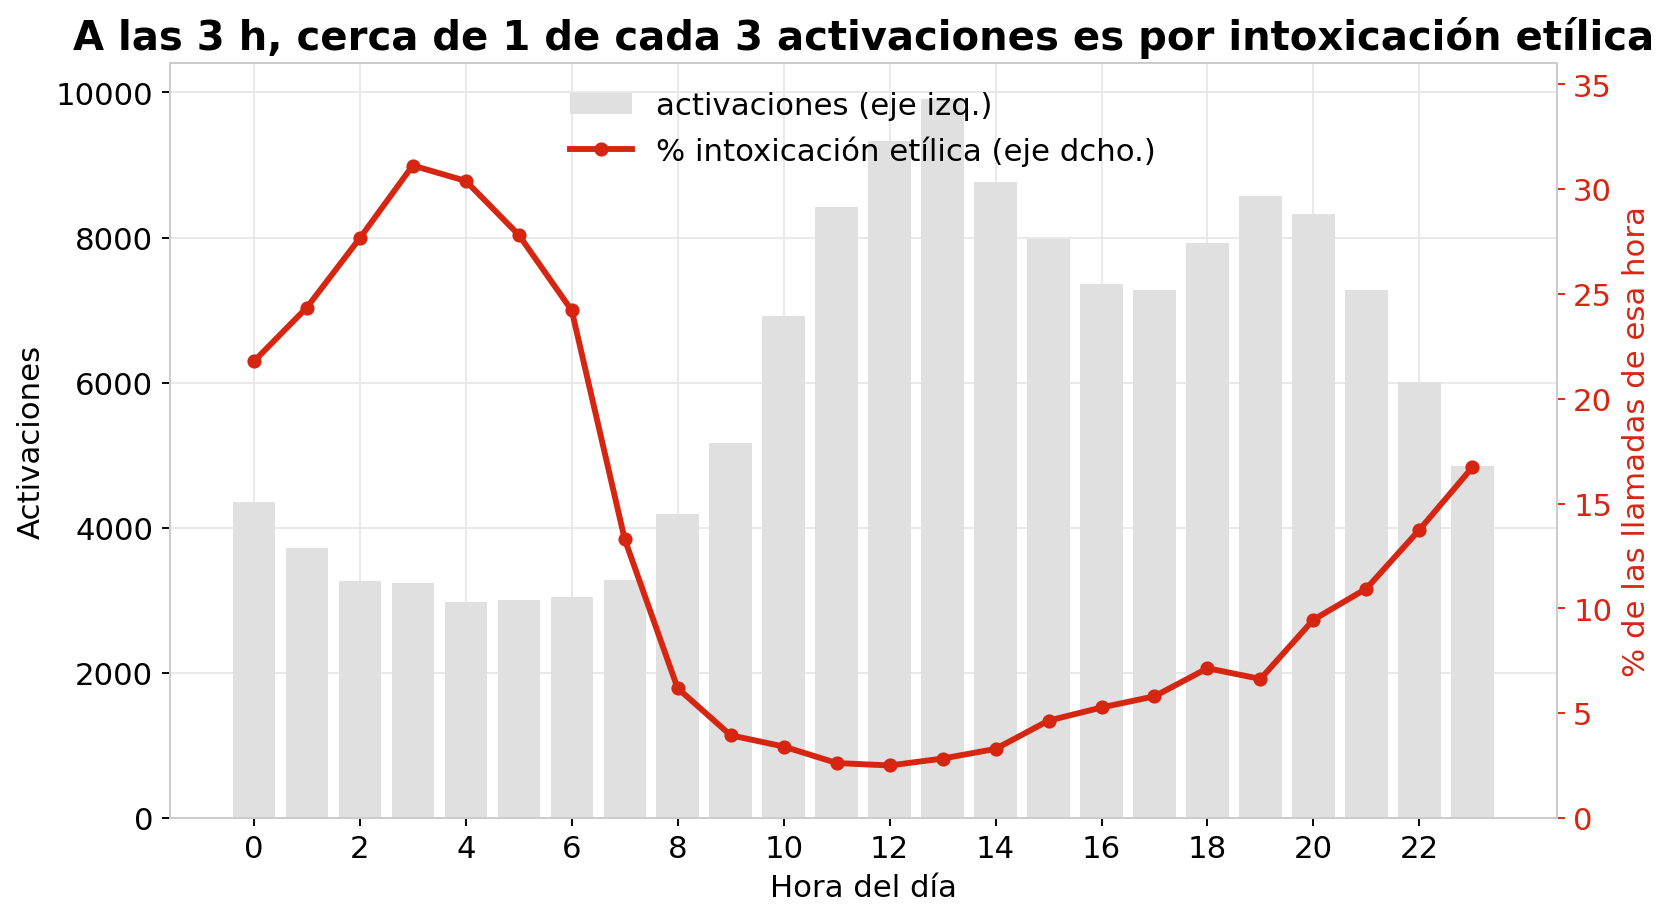

In [21]:
con_hora = act.dropna(subset=['hora'])
es_ie = con_hora['tipo_emergencia'] == 'Intoxicación etílica'  # código exacto del catálogo
share_ie = es_ie.groupby(con_hora['hora']).mean() * 100

# De madrugada (0-7h), ¿cuál es el tipo nº1?
madrugada = con_hora[con_hora['hora'] < 7]
print("Tipo nº1 de 0 a 7h:", madrugada['tipo_emergencia'].value_counts().idxmax())
print(f"Intoxicación etílica a las 3h: {share_ie[3]:.0f}% de las llamadas")
print(f"Intoxicación etílica a las 12h: {share_ie[12]:.0f}% de las llamadas")
tot_ie = es_ie.mean() * 100
print(f"En todo el año: {tot_ie:.0f}% de las activaciones")

fig, ax = plt.subplots()
ax.bar(por_hora.index, por_hora.values, color='#e0e0e0', label='activaciones (eje izq.)')
ax.set_xlabel('Hora del día')
ax.set_ylabel('Activaciones')
ax.set_xticks(range(0, 24, 2))
ax2 = ax.twinx()
ax2.plot(share_ie.index, share_ie.values, color=ROJO, linewidth=2.5, marker='o', markersize=5,
         label='% intoxicación etílica (eje dcho.)')
ax2.set_ylabel('% de las llamadas de esa hora', color=ROJO)
ax2.tick_params(axis='y', colors=ROJO)
ax2.grid(False)
ax2.set_ylim(0, 36)
ax.set_title('A las 3 h, cerca de 1 de cada 3 activaciones es por intoxicación etílica')
lineas = ax.get_legend_handles_labels()
lineas2 = ax2.get_legend_handles_labels()
ax.legend(lineas[0] + lineas2[0], lineas[1] + lineas2[1], frameon=False, loc='upper center')
plt.tight_layout()
plt.savefig(FIG_EDA / 'intoxicacion_nocturna.png', bbox_inches='tight')
plt.show()

**Lo que vemos:** entre las 0 y las 7h la intoxicación etílica es el **tipo de emergencia nº1**, y a las 3 de la mañana es el **31%** de todas las llamadas (a mediodía no llega al 3%). Es el mismo servicio, pero dos realidades distintas según la hora, y eso importa para decidir qué recursos hacen falta en cada turno.

## 4. Categorías del catálogo de tipos (cohesión con el caso 2.2)

Desde la última versión de la limpieza de activaciones, `tipo_emergencia` **ya es** el código del catálogo canónico (`tipos_emergencia_clean.csv`, 39 tipos): la limpieza resolvió los alias y eliminó las filas cuyo tipo no describía una urgencia, así que el 100% de las activaciones tiene tipo catalogado. Aquí solo añadimos la **categoría** de cada tipo con un `merge` directo, para ver el reparto general del servicio.

Nota de cohesión: la prioridad que traen ahora las activaciones es la del catálogo (lo grave que suele ser cada tipo), no la registrada en cada evento; la del registro solo coincidía con ella en el 37,7% de las filas. El detalle está en `limpieza_activaciones.ipynb` (sección "Criterio del catálogo").

In [22]:
cat = cargar('tipos_emergencia_clean.csv', [raiz / 'data_clean', carpeta])

# Merge directo: tipo_emergencia ya es el codigo del catalogo (lo dejo asi la limpieza)
act = act.merge(cat[['codigo', 'categoria_correcta', 'prioridad_base_correcta']],
                left_on='tipo_emergencia', right_on='codigo', how='left').drop(columns=['codigo'])
act['tipo_figura'] = act['tipo_emergencia']  # etiqueta para figuras: el codigo literal del catalogo

clasificada = act['categoria_correcta'].notna()
print(f"Clasificadas en el catálogo: {clasificada.sum():,} de {len(act):,} ({clasificada.mean()*100:.2f}%)".replace(',', '.'))
assert clasificada.all(), 'La limpieza garantiza que el 100% trae tipo del catálogo'

Clasificadas en el catálogo: 146.567 de 146.567 (100.00%)


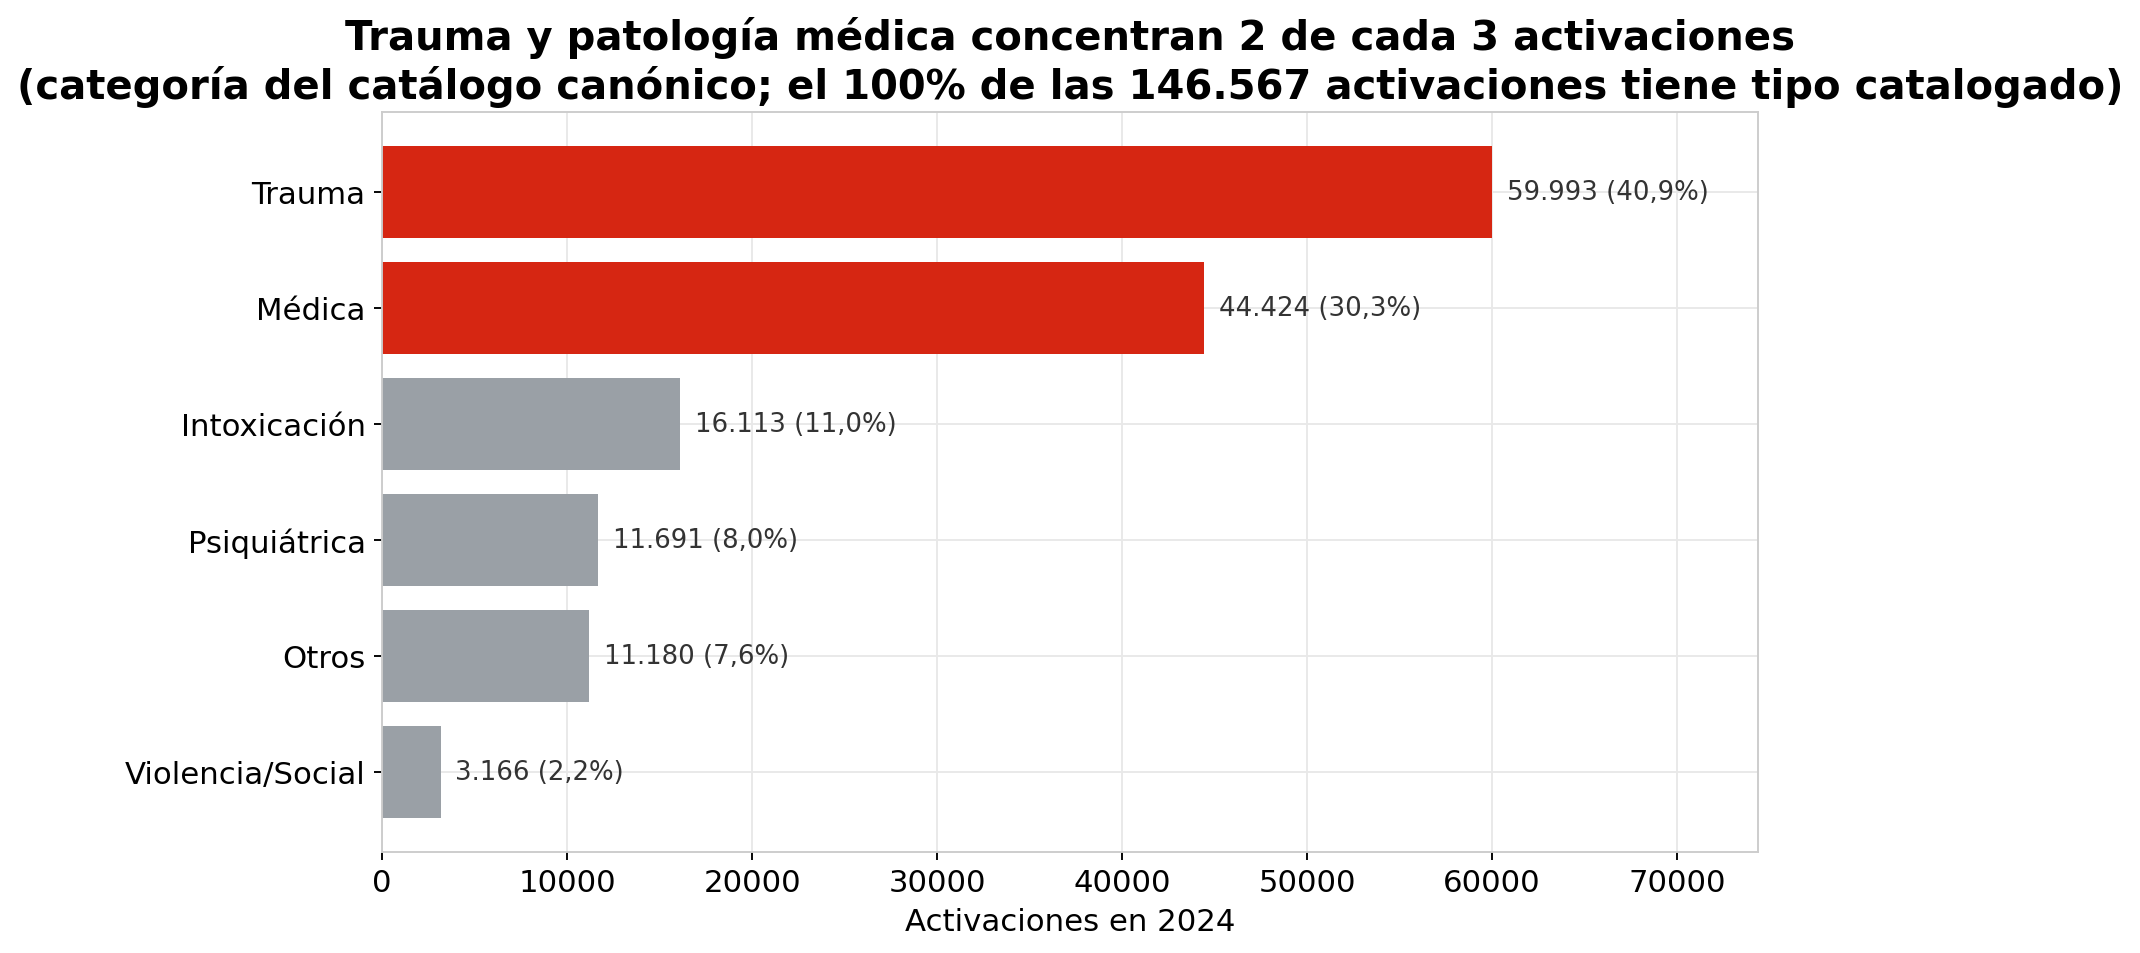

In [23]:
total = len(act)
por_cat = act['categoria_correcta'].value_counts()
etiquetas = list(por_cat.index)
valores = list(por_cat.values)
colores = [ROJO if e in ('Trauma', 'Médica') else GRIS for e in etiquetas]

fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(range(len(etiquetas)), valores[::-1], color=colores[::-1])
ax.set_yticks(range(len(etiquetas)))
ax.set_yticklabels(etiquetas[::-1])
for i, v in enumerate(valores[::-1]):
    etiqueta_valor = f"{v:,}".replace(',', '.') + ' (' + f"{v/total*100:.1f}".replace('.', ',') + '%)'
    ax.text(v + 800, i, etiqueta_valor, va='center', fontsize=11, color='#333333')
ax.set_xlabel('Activaciones en 2024')
ax.set_title('Trauma y patología médica concentran 2 de cada 3 activaciones\n'
             '(categoría del catálogo canónico; el 100% de las 146.567 activaciones tiene tipo catalogado)')
ax.set_xlim(0, max(valores) * 1.24)
plt.tight_layout()
plt.savefig(FIG_EDA / 'activaciones_por_categoria.png', bbox_inches='tight')
plt.show()

**Lo que vemos:** con las categorías del catálogo, **trauma (59.993, 40,9%) y patología médica (44.424, 30,3%) concentran más de 2 de cada 3 activaciones** del año; las intoxicaciones pesan un 11,0%. Esto conecta directo con el clustering: el "para qué" de la demanda de cada distrito se puede perfilar con estas categorías.

Ya no queda nada fuera del catálogo: la limpieza resolvió los alias (597 filas de abreviaturas y 1.564 de equivalencias clínicas, documentadas en `limpieza_activaciones.ipynb`) y eliminó 5.513 filas (el 3,6%) cuyo `tipo_emergencia` no describía una urgencia (recursos enviados, procedencia del aviso, servicios no asistenciales o lugar).

## 5. Qué tipo de emergencias y con qué prioridad

Para contar "el problema" hace falta decir qué atiende el SAMUR. Mostramos los 10 tipos más frecuentes y el reparto por prioridad (alta/media/baja, la que el catálogo asigna a cada tipo, con el criterio unificado que confirmó Bluetab). Los tipos ya vienen con el código canónico del catálogo desde la limpieza.

Aclaración de alcance: el correo del 14/10 confirma equivalencias de escritura de la prioridad registrada y pide criterio para el catálogo. No valida específicamente todas las categorías/prioridades/tiempos corregidos. El catálogo limpio utilizado es una decisión metodológica propia documentada.

Top 3:
  Patología cardiovascular: 28.715 (20%)
  Casual: caída. etc: 26.265 (18%)
  Intoxicación etílica: 14.098 (10%)


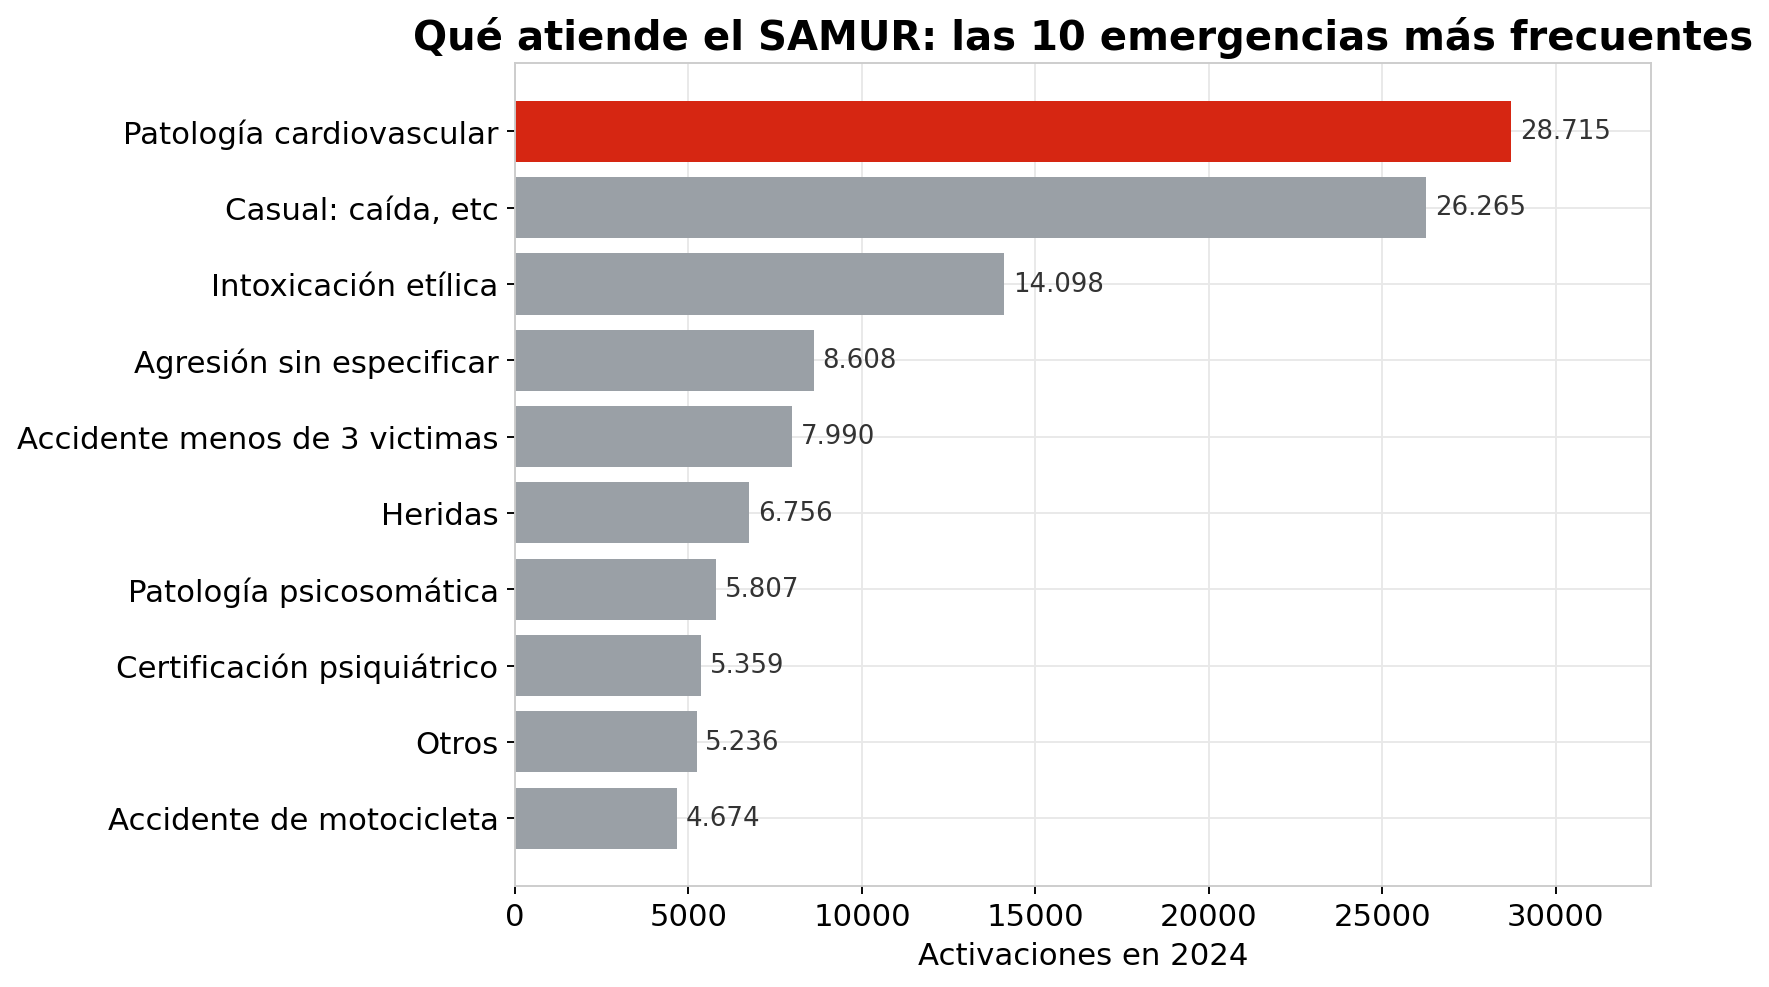


Prioridad del catálogo (gravedad típica del tipo):
  alta: 57.894 (40%)
  media: 68.100 (46%)
  baja: 20.573 (14%)


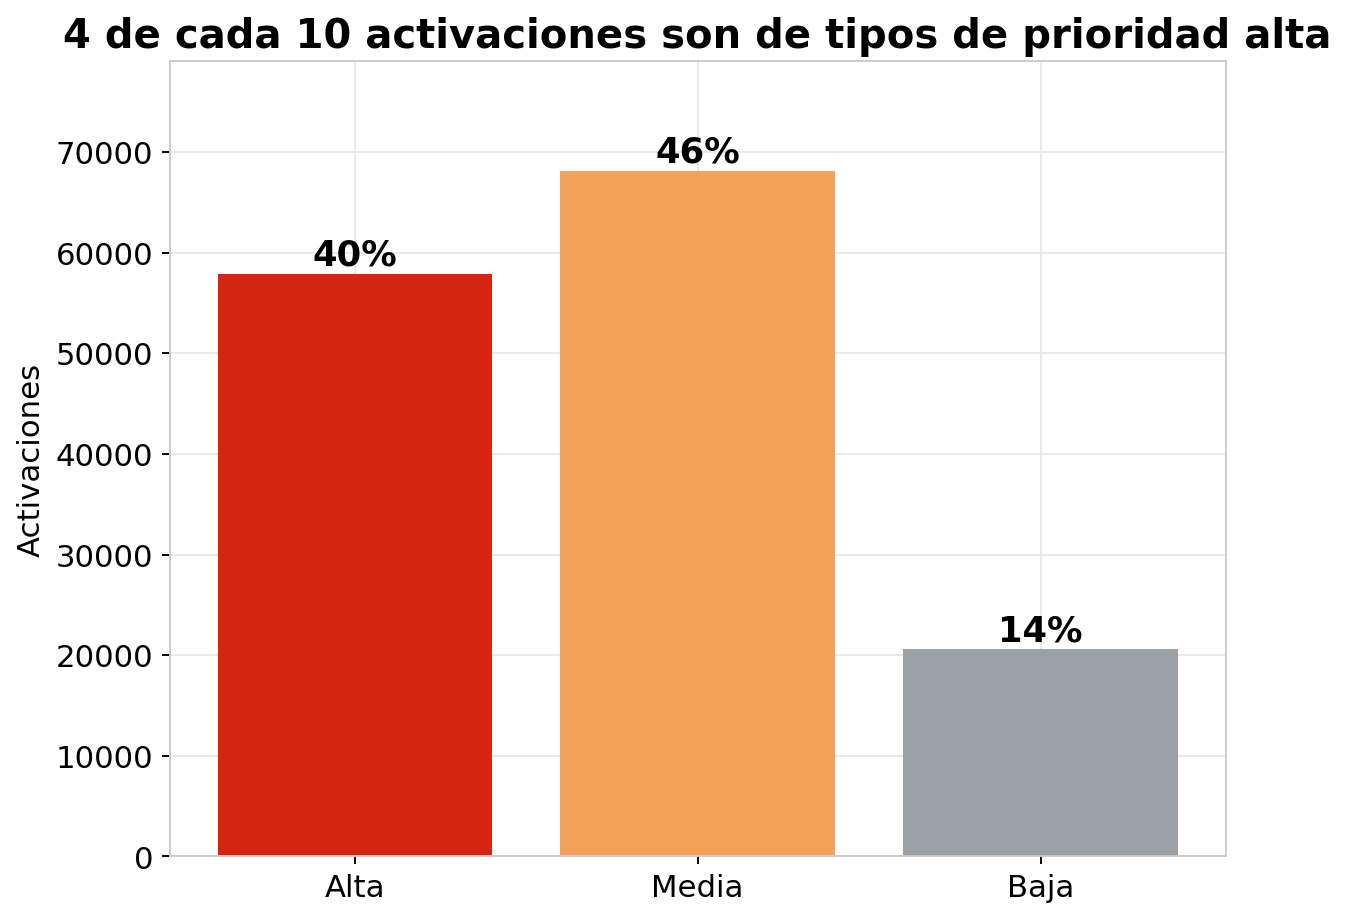

In [24]:
top10 = act['tipo_figura'].value_counts().head(10).sort_values()
print("Top 3:")
for t, n in act['tipo_figura'].value_counts().head(3).items():
    print(f"  {t}: {n:,} ({n/len(act)*100:.0f}%)".replace(',', '.'))

fig, ax = plt.subplots(figsize=(10, 6))
colores = [ROJO if t == top10.index[-1] else GRIS for t in top10.index]
ax.barh(top10.index, top10.values, color=colores)
ax.set_xlabel('Activaciones en 2024')
ax.set_title('Qué atiende el SAMUR: las 10 emergencias más frecuentes')
for i, v in enumerate(top10.values):
    ax.text(v + 250, i, f'{v:,}'.replace(',', '.'), va='center', fontsize=11, color='#333333')
ax.set_xlim(0, top10.max() * 1.14)
plt.tight_layout()
plt.savefig(FIG_EDA / 'tipos_emergencia_top10.png', bbox_inches='tight')
plt.show()

pri = act['prioridad'].value_counts().reindex(['alta', 'media', 'baja'])
print()
print("Prioridad del catálogo (gravedad típica del tipo):")
for p, n in pri.items():
    print(f"  {p}: {n:,} ({n/pri.sum()*100:.0f}%)".replace(',', '.'))

fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.bar(['Alta', 'Media', 'Baja'], pri.values, color=[ROJO, '#f4a259', GRIS])
for i, v in enumerate(pri.values):
    ax.text(i, v + 900, f'{v/pri.sum()*100:.0f}%', ha='center', fontsize=15, fontweight='bold')
ax.set_ylabel('Activaciones')
ax.set_title('4 de cada 10 activaciones son de tipos de prioridad alta')
ax.set_ylim(0, pri.max() * 1.16)
plt.tight_layout()
plt.savefig(FIG_EDA / 'prioridades.png', bbox_inches='tight')
plt.show()

**Lo que vemos:** patología cardiovascular (28.715) y caídas (26.265) concentran más de un tercio del servicio. El **40% de las activaciones son de tipos de prioridad alta** según el catálogo. Ojo: antes este porcentaje medía la prioridad registrada en cada evento; ahora mide la gravedad típica del tipo, que es lo que deja la limpieza (las dos solo coincidían en el 37,7% de las filas).

Decisión: los tipos se muestran con el código literal del catálogo, que es como vienen en `activaciones_limpio.csv` desde la última limpieza.

Un detalle que no esperábamos: la mediana del tiempo de respuesta apenas cambia con la prioridad del tipo (7,0 min en alta, 7,1 en media y 7,6 en baja). El tiempo mide desde la solicitud hasta la intervención, así que no vemos si las urgentes se cuelan antes en la cola; no permite inferir priorización clínica ni orden de atención: esa conclusión queda fuera del alcance.

## 6. Edad y sexo registrados: diagnóstico, no interpretación clínica

La edad registrada tiene un reparto casi uniforme entre 0 y 99 años. Esto no demuestra su causa ni autoriza a llamarla sintética. Decisión cerrada: conservar valores y declarar el patrón; no usar edad ni sexo registrados para insights clínicos o demográficos. El porcentaje de mayores de 65 del socioeconómico es otra fuente y describe residentes, no pacientes. El notebook final documenta aparte el efecto de la edad registrada en la segmentación.

Sexo: 70.675 mujeres y 70.093 hombres (prácticamente 50/50)
Edades distintas: 100 (de 0 a 99)
Media de activaciones por edad: 1457 (si fuera uniforme perfecta)
Mínimo y máximo por edad: 1325 - 1521 (diferencia del 13%)


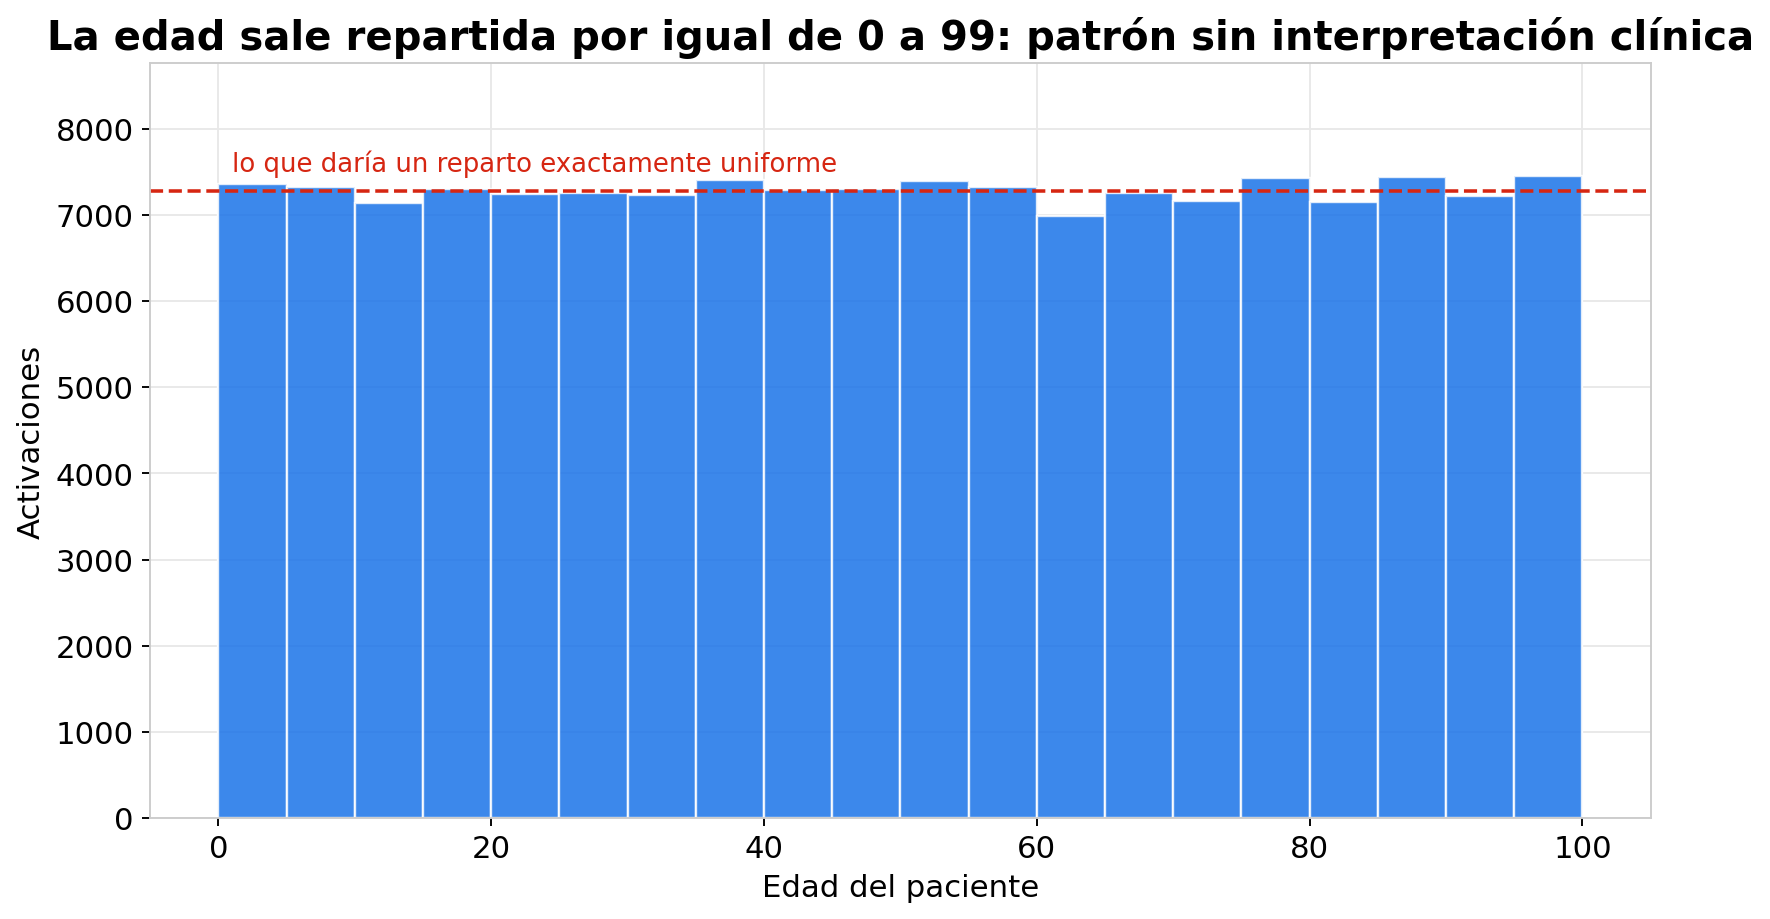

In [25]:
edad = act['paciente_edad'].dropna()
sexo = act['paciente_sexo'].value_counts()
print(f"Sexo: {sexo.get('M', 0):,} mujeres y {sexo.get('H', 0):,} hombres (prácticamente 50/50)".replace(',', '.'))

# Comprobación: activaciones por cada edad concreta (0-99)
por_edad = edad.value_counts()
print(f"Edades distintas: {edad.nunique()} (de {edad.min():.0f} a {edad.max():.0f})")
print(f"Media de activaciones por edad: {len(edad)/edad.nunique():.0f} (si fuera uniforme perfecta)")
print(f"Mínimo y máximo por edad: {por_edad.min()} - {por_edad.max()} (diferencia del {(por_edad.max()-por_edad.min())/por_edad.mean()*100:.0f}%)")

fig, ax = plt.subplots()
ax.hist(edad, bins=range(0, 105, 5), color=AZUL, alpha=0.85, edgecolor='white')
ax.axhline(len(edad)/edad.nunique()*5, color=ROJO, linestyle='--', linewidth=1.5)
ax.text(1, len(edad)/edad.nunique()*5*1.03, 'lo que daría un reparto exactamente uniforme', color=ROJO, fontsize=11)
ax.set_xlabel('Edad del paciente')
ax.set_ylabel('Activaciones')
ax.set_title('La edad sale repartida por igual de 0 a 99: patrón sin interpretación clínica')
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
plt.tight_layout()
plt.savefig(FIG_EDA / 'edad_pacientes.png', bbox_inches='tight')
plt.show()

El gráfico y los conteos muestran un reparto casi uniforme de edad y sexos registrados próximos al 50/50. La causa no se puede determinar con el archivo disponible. No se interpreta como población real de pacientes ni se extraen conclusiones clínicas.

## 7. Dónde: la demanda no se reparte igual

Cruzamos con `tabla_distritos.csv`. Para comparar distritos de distinto tamaño usamos **activaciones por 1.000 residentes** (activaciones por población residente) (decisión ya tomada en los cruces: si no, los distritos grandes parecerían peores solo por tener más gente).

Centro es un caso aparte: 141 activaciones por 1.000 residentes, 3,1 veces la media simple de los 21 distritos (45) y 2,2 veces el segundo distrito (Moncloa-Aravaca, 65). Miramos si su perfil de activaciones apunta a una explicación.

Centro: 141 activaciones/1.000 residentes
Media simple de los 21 distritos: 45 | ratio agregado de la ciudad: 44
Centro es 3.1x la media de distritos y 2.2x el segundo (Moncloa-Aravaca, 65)
Activaciones de 0 a 7h: Centro 24% vs resto 15%
Intoxicación etílica: Centro 14% vs resto 9%


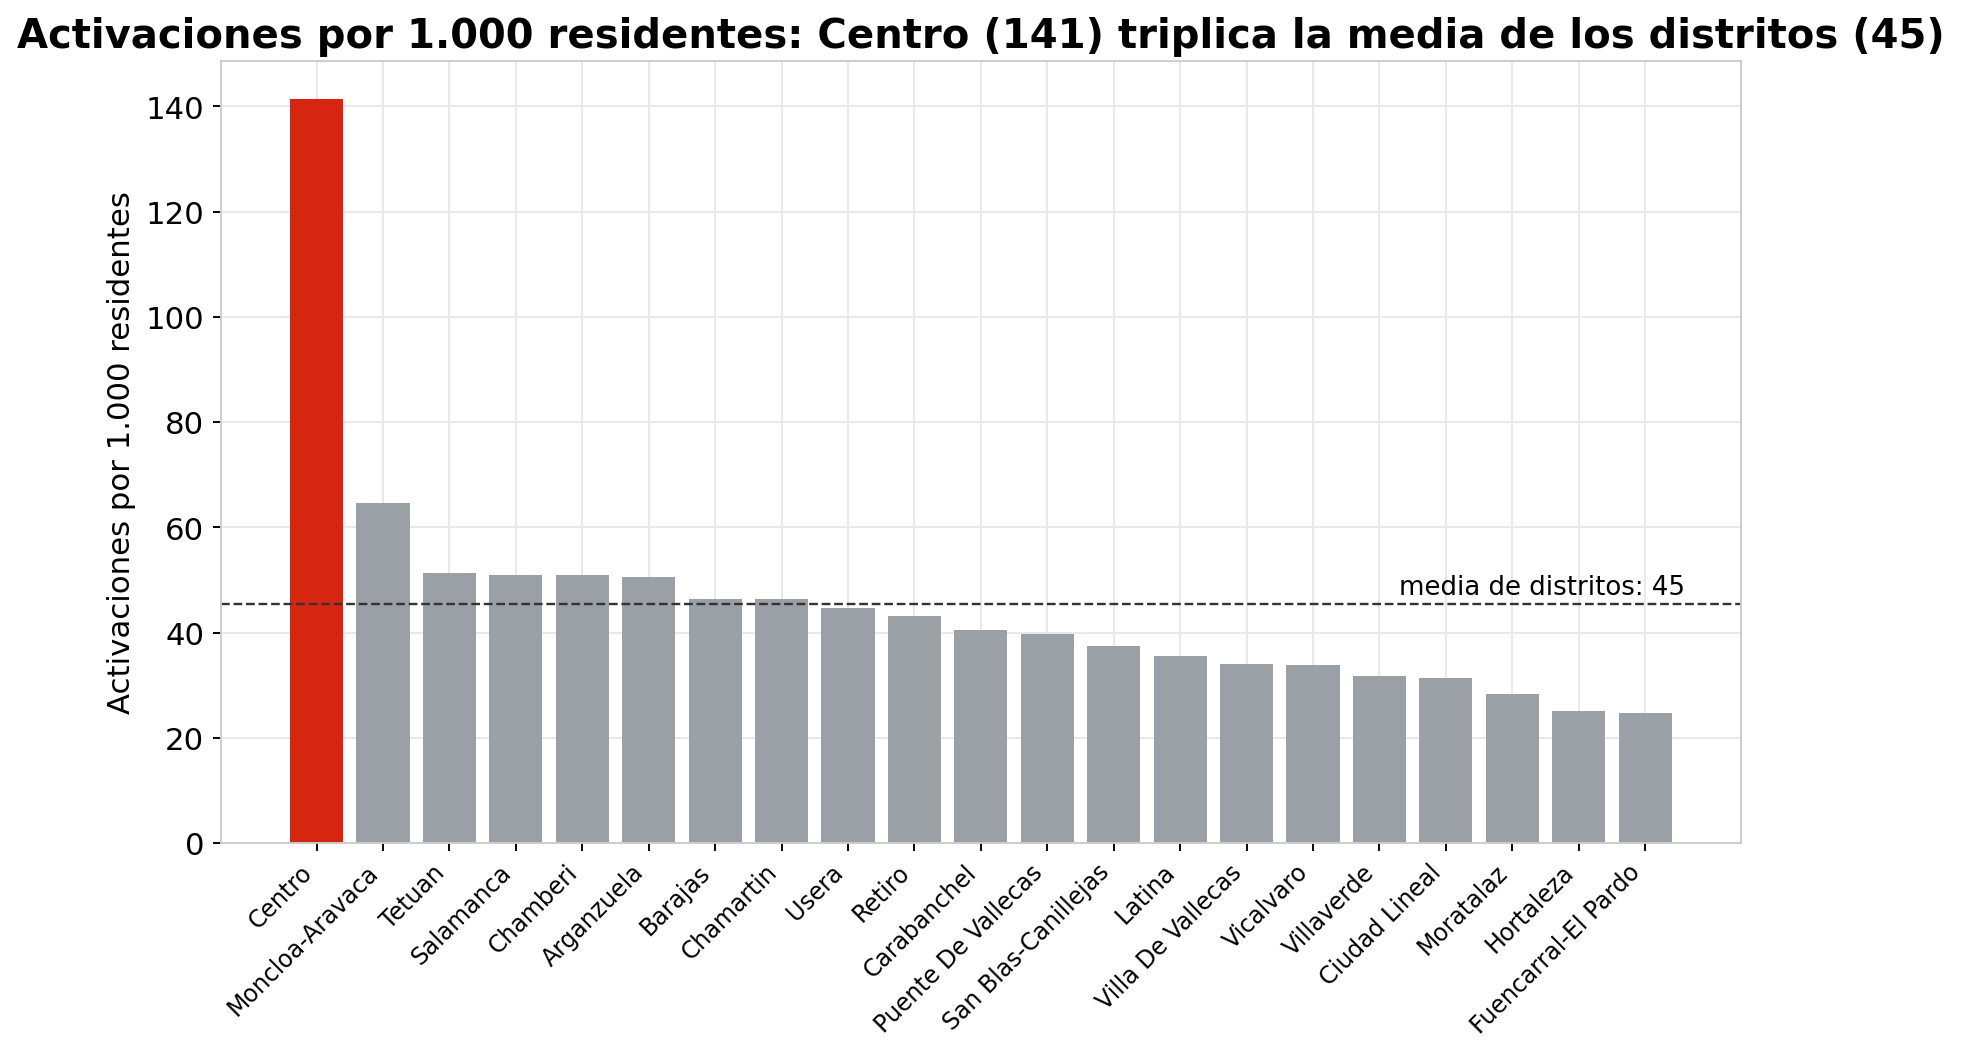

In [26]:
t = tabla.sort_values('activaciones_por_1000hab', ascending=False)
media_distritos = t['activaciones_por_1000hab'].mean()  # media simple de los 21 distritos
ratio_ciudad = t['n_activaciones'].sum() / t['poblacion'].sum() * 1000  # ratio agregado de la ciudad
centro = t.iloc[0]
segundo = t.iloc[1]
print(f"Centro: {centro['activaciones_por_1000hab']:.0f} activaciones/1.000 residentes")
print(f"Media simple de los 21 distritos: {media_distritos:.0f} | ratio agregado de la ciudad: {ratio_ciudad:.0f}")
print(f"Centro es {centro['activaciones_por_1000hab']/media_distritos:.1f}x la media de distritos y {centro['activaciones_por_1000hab']/segundo['activaciones_por_1000hab']:.1f}x el segundo ({segundo['distrito'].title()}, {segundo['activaciones_por_1000hab']:.0f})")

# Perfil de Centro: de madrugada y ocio
ce = act[act['distrito'] == 'CENTRO']
resto = act[act['distrito'] != 'CENTRO']
noche_ce = ((ce['hora'] >= 0) & (ce['hora'] < 7)).mean() * 100
noche_re = ((resto['hora'] >= 0) & (resto['hora'] < 7)).mean() * 100
ie_ce = (ce['tipo_emergencia'] == 'Intoxicación etílica').mean() * 100
ie_re = (resto['tipo_emergencia'] == 'Intoxicación etílica').mean() * 100
print(f"Activaciones de 0 a 7h: Centro {noche_ce:.0f}% vs resto {noche_re:.0f}%")
print(f"Intoxicación etílica: Centro {ie_ce:.0f}% vs resto {ie_re:.0f}%")

fig, ax = plt.subplots(figsize=(10, 6.4))
colores = [ROJO if d == 'CENTRO' else GRIS for d in t['distrito']]
ax.bar(range(len(t)), t['activaciones_por_1000hab'], color=colores)
ax.axhline(media_distritos, color='#333333', linestyle='--', linewidth=1)
ax.text(len(t) - 0.4, media_distritos + 2, f'media de distritos: {media_distritos:.0f}', ha='right', fontsize=11)
ax.set_xticks(range(len(t)))
ax.set_xticklabels(t['distrito'].str.title(), rotation=45, ha='right', fontsize=10)
ax.set_ylabel('Activaciones por 1.000 residentes')
ax.set_title(f'Activaciones por 1.000 residentes: Centro ({centro["activaciones_por_1000hab"]:.0f}) triplica la media de los distritos ({media_distritos:.0f})')
plt.tight_layout()
plt.savefig(FIG_EDA / 'demanda_por_distrito.png', bbox_inches='tight')
plt.show()

Centro concentra el 24% de sus activaciones entre las 0 y las 7 h, frente al 15% en el resto de la ciudad, y una proporción mayor de intoxicaciones etílicas (14% frente a 9%). La explicación por ocio nocturno o afluencia de no residentes es una hipótesis, no una causa observada: no tenemos itinerarios, motivo de presencia ni residencia del paciente.

El denominador es población residente y el numerador es actividad localizada en el distrito. Por eso la tasa no mide riesgo de sus vecinos. No se puede cuantificar qué parte pertenece a visitantes con estas tablas ni afirmar que esa parte sea mayoritaria. Se conserva la hipótesis histórica como posible interpretación, separada del dato medido.

Correlación demanda-renta: 0.19 con Centro, 0.41 sin Centro
Correlación demanda-%mayores65 (sin Centro): 0.38
Correlación demanda-vulnerabilidad (sin Centro): -0.36


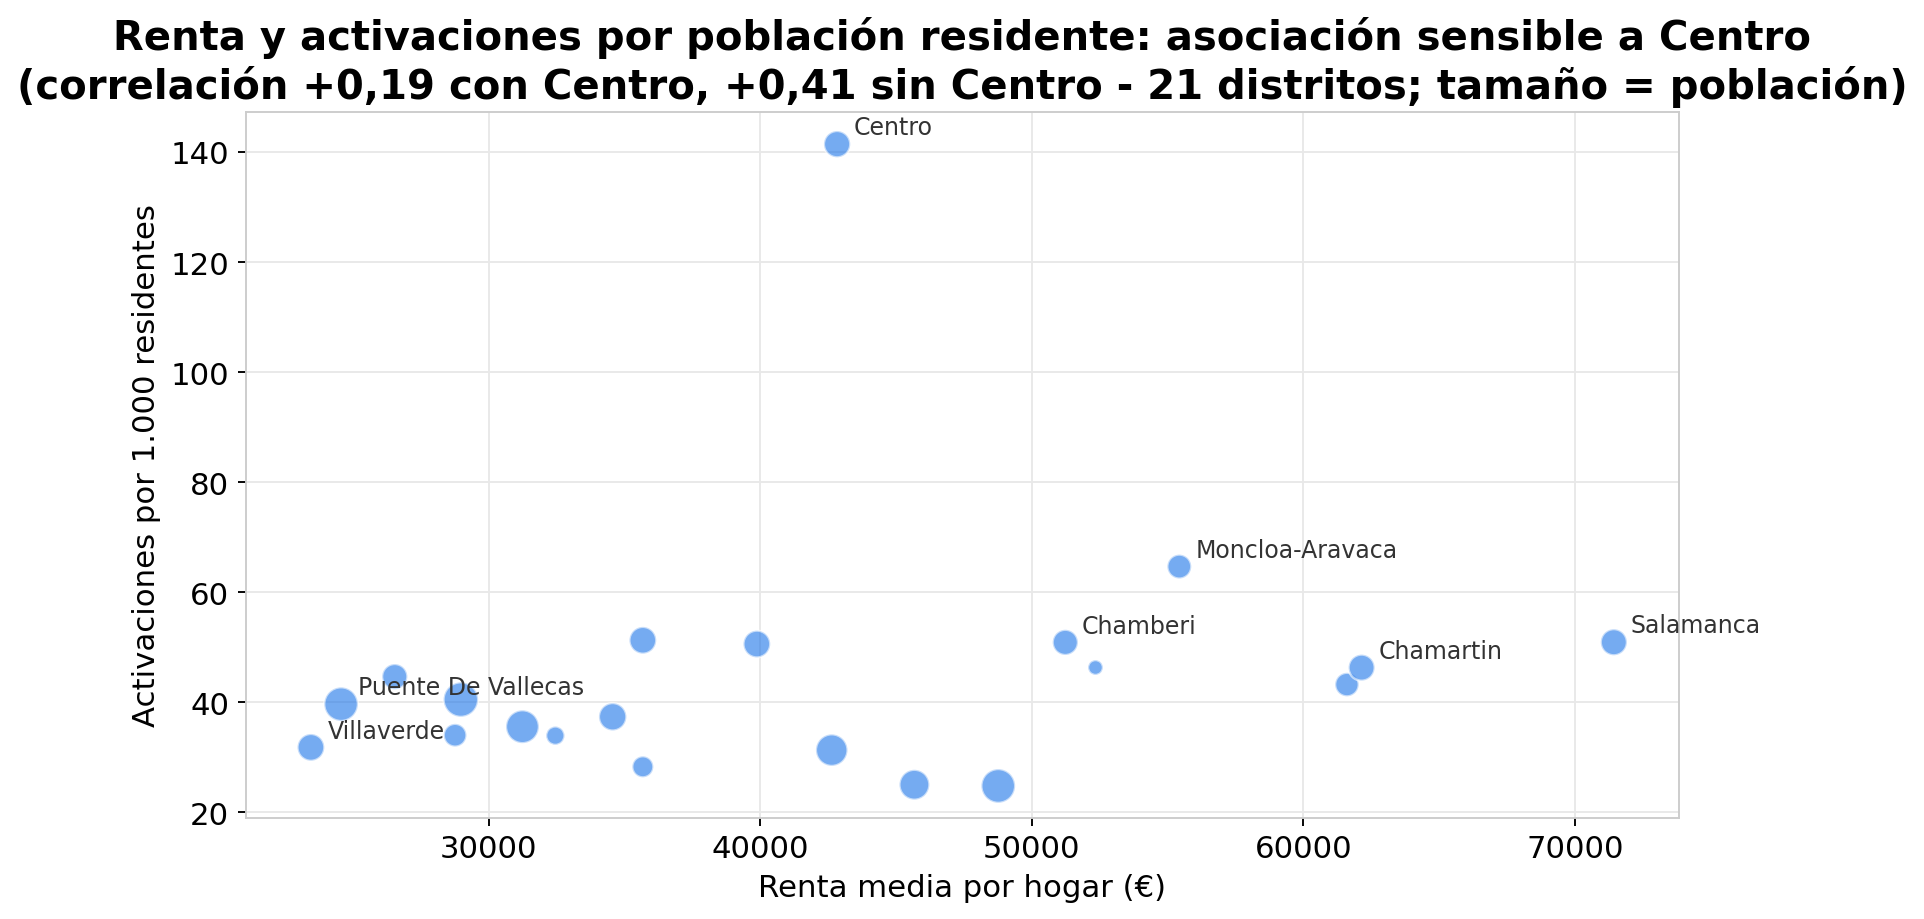

In [27]:
t2 = tabla[tabla['distrito'] != 'CENTRO']
r_con = tabla['activaciones_por_1000hab'].corr(tabla['renta_media_hogar'])
r_sin = t2['activaciones_por_1000hab'].corr(t2['renta_media_hogar'])
print(f"Correlación demanda-renta: {r_con:.2f} con Centro, {r_sin:.2f} sin Centro")
print(f"Correlación demanda-%mayores65 (sin Centro): {t2['activaciones_por_1000hab'].corr(t2['pct_mayores_65']):.2f}")
print(f"Correlación demanda-vulnerabilidad (sin Centro): {t2['activaciones_por_1000hab'].corr(t2['indice_vulnerabilidad']):.2f}")

fig, ax = plt.subplots()
ax.scatter(tabla['renta_media_hogar'], tabla['activaciones_por_1000hab'],
           s=tabla['poblacion'] / 1200, color=AZUL, alpha=0.6, edgecolor='white', linewidth=1)
for _, f in tabla.iterrows():
    if f['distrito'] in ('CENTRO', 'SALAMANCA', 'VILLAVERDE', 'PUENTE DE VALLECAS', 'MONCLOA-ARAVACA', 'CHAMARTIN', 'CHAMBERI'):
        ax.annotate(f['distrito'].title(), (f['renta_media_hogar'], f['activaciones_por_1000hab']),
                    textcoords='offset points', xytext=(7, 4), fontsize=10, color='#333333')
ax.set_xlabel('Renta media por hogar (€)')
ax.set_ylabel('Activaciones por 1.000 residentes')
ax.set_title(f'Renta y activaciones por población residente: asociación sensible a Centro\n(correlación +{r_con:.2f} con Centro, +{r_sin:.2f} sin Centro - 21 distritos; tamaño = población)'.replace('.', ','))
plt.tight_layout()
plt.savefig(FIG_EDA / 'renta_vs_demanda.png', bbox_inches='tight')
plt.show()

## 8. Tiempo de respuesta y densidad: asociación distrital

El rótulo histórico atribuía un papel determinante a la densidad. Aquí se mide asociación entre medias de distrito, no un efecto causal. Se explora la distribución de tiempos y su relación con densidad, manteniendo todos los límites del dato.

Mediana: 7.2 min | media: 7.7 min
El 60% de las activaciones se atiende en 8 minutos o menos
Percentil 90: 12 min
Más rápido: CHAMBERI (6.5 min)
Más lento: BARAJAS (10.7 min)
Correlación con la densidad: -0.87


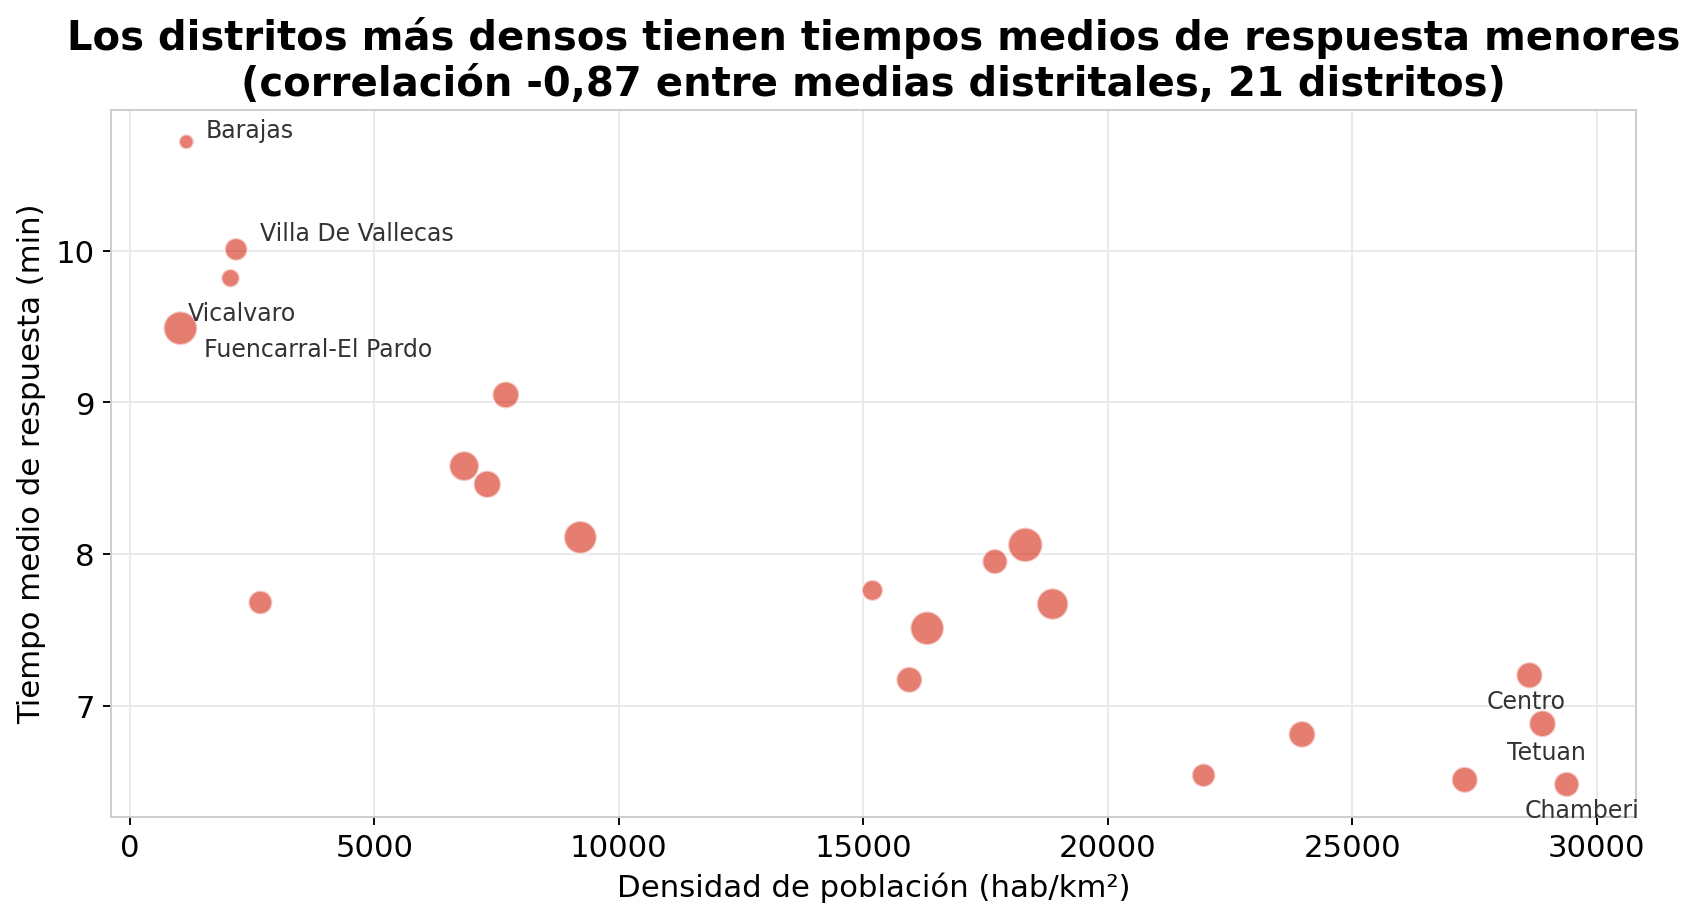

In [28]:
tr = act['tiempo_de_respuesta'].dropna()
print(f"Mediana: {tr.median():.1f} min | media: {tr.mean():.1f} min")
print(f"El {(tr <= 8).mean()*100:.0f}% de las activaciones se atiende en 8 minutos o menos")
print(f"Percentil 90: {tr.quantile(0.9):.0f} min")

por_distrito = tabla[['distrito', 'tiempo_respuesta_medio_min', 'densidad_hab_km2']].sort_values('tiempo_respuesta_medio_min')
rapido = por_distrito.iloc[0]
lento = por_distrito.iloc[-1]
print(f"Más rápido: {rapido['distrito']} ({rapido['tiempo_respuesta_medio_min']:.1f} min)")
print(f"Más lento: {lento['distrito']} ({lento['tiempo_respuesta_medio_min']:.1f} min)")
print(f"Correlación con la densidad: {tabla['tiempo_respuesta_medio_min'].corr(tabla['densidad_hab_km2']):.2f}")

fig, ax = plt.subplots()
ax.scatter(tabla['densidad_hab_km2'], tabla['tiempo_respuesta_medio_min'],
           s=tabla['poblacion'] / 1200, color=ROJO, alpha=0.6, edgecolor='white', linewidth=1)
for _, f in tabla.iterrows():
    etq = {'BARAJAS': (8, 2), 'CHAMBERI': (-18, -14), 'FUENCARRAL-EL PARDO': (8, -6),
           'CENTRO': (-18, -14), 'VILLA DE VALLECAS': (10, 4), 'VICALVARO': (-18, -18), 'FUENCARRAL-EL PARDO': (10, -12), 'TETUAN': (-15, -15)}
    if f['distrito'] in etq:
        ax.annotate(f['distrito'].title(), (f['densidad_hab_km2'], f['tiempo_respuesta_medio_min']),
                    textcoords='offset points', xytext=etq[f['distrito']], fontsize=10, color='#333333')
ax.set_xlabel('Densidad de población (hab/km²)')
ax.set_ylabel('Tiempo medio de respuesta (min)')
ax.set_title('Los distritos más densos tienen tiempos medios de respuesta menores\n(correlación -0,87 entre medias distritales, 21 distritos)')
plt.tight_layout()
plt.savefig(FIG_EDA / 'densidad_vs_tiempo_respuesta.png', bbox_inches='tight')
plt.show()

La mediana global del tiempo válido es 7,2 minutos y el 60% de las activaciones con tiempo válido está en 8 minutos o menos. Los tiempos medios distritales van de 6,5 minutos en Chamberí a 10,7 en Barajas. Densidad y tiempo medio presentan Pearson r = -0,87 en 21 distritos.

Es una asociación descriptiva fuerte entre esas dos variables, no la mayor correlación de todo el proyecto ni una prueba causal. La explicación por distancia, proximidad de unidades o geografía sigue siendo una hipótesis. No hay localización exacta de salida, trayecto ni medición de cobertura que permita identificar un cuello de botella. La mediana y el P90 con casos válidos y faltantes se desarrollan después en la sección final.

## 9. Oferta de catálogo y demanda: descripción, no prueba de cobertura

Se compara el distrito de base catalogado de las unidades con demanda por habitante. El rótulo histórico sugería funcionamiento de una red; esa eficacia o cobertura NO queda demostrada por contar bases o por la coincidencia entre base y lugar de activación. Las unidades se pueden desplazar, pero este catálogo no permite reconstruir su operación.

Se conservan todos los cálculos de la exploración y se interpretan como descripción de catálogos, con unidades ambiguas sin asignar y sin completar oferta desconocida.

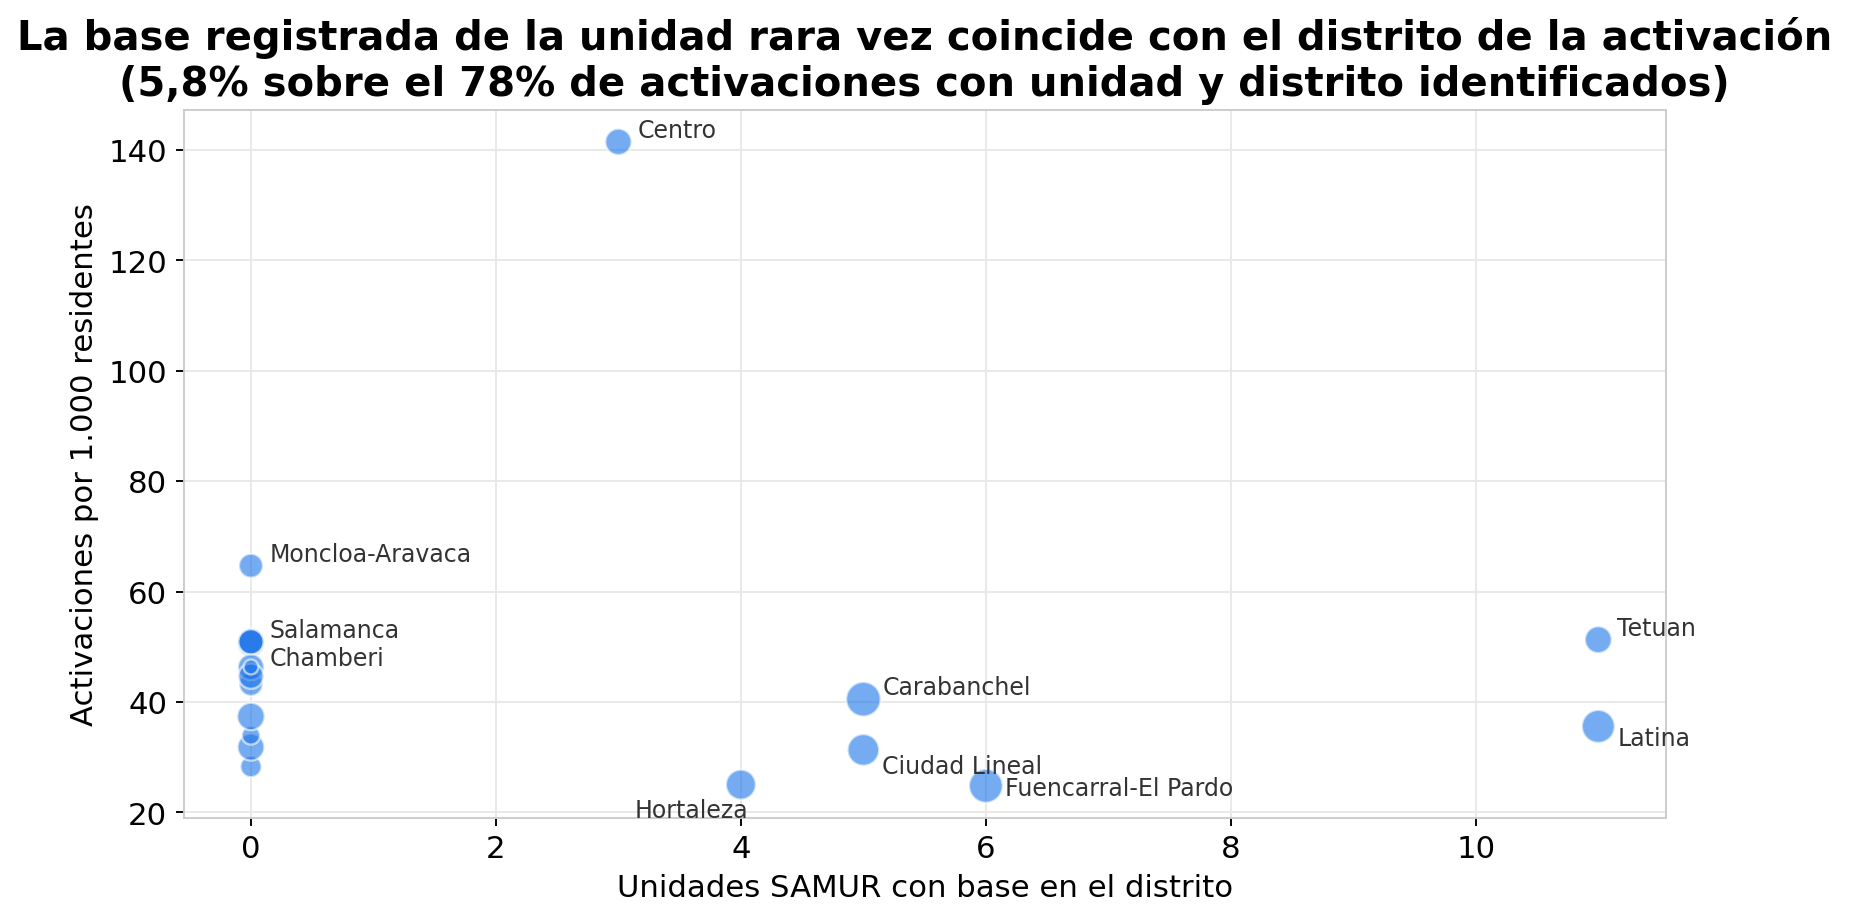

Ejemplos:
  Centro: 3.0 unidades, 141 act./1.000 hab, 7.2 min de respuesta
  Tetuan: 11.0 unidades, 51 act./1.000 hab, 6.9 min de respuesta
  Latina: 11.0 unidades, 36 act./1.000 hab, 8.1 min de respuesta
  Chamberi: 0.0 unidades, 51 act./1.000 hab, 6.5 min de respuesta
Fuera del gráfico: Puente y Villa de Vallecas (sus unidades son desconocidas, no 0)


In [29]:
tabla_od = tabla.dropna(subset=['unidades_samur'])  # fuera Puente y Villa de Vallecas: unidades desconocidas, no 0
fig, ax = plt.subplots()
ax.scatter(tabla_od['unidades_samur'], tabla_od['activaciones_por_1000hab'],
           s=tabla_od['poblacion'] / 1200, color=AZUL, alpha=0.6, edgecolor='white', linewidth=1)
etiquetas = {'CENTRO': (8, 2), 'MONCLOA-ARAVACA': (8, 2), 'SALAMANCA': (8, 2),
             'CHAMBERI': (8, -10), 'TETUAN': (8, 2),
             'LATINA': (8, -8), 'CARABANCHEL': (8, 2), 'CIUDAD LINEAL': (8, -10),
             'FUENCARRAL-EL PARDO': (8, -4), 'HORTALEZA': (-45, -14)}
for _, f in tabla_od.iterrows():
    if f['distrito'] in etiquetas:
        ax.annotate(f['distrito'].title(), (f['unidades_samur'], f['activaciones_por_1000hab']),
                    textcoords='offset points', xytext=etiquetas[f['distrito']], fontsize=10, color='#333333')
ax.set_xlabel('Unidades SAMUR con base en el distrito')
ax.set_ylabel('Activaciones por 1.000 residentes')
ax.set_title('La base registrada de la unidad rara vez coincide con el distrito de la activación\n(5,8% sobre el 78% de activaciones con unidad y distrito identificados)')
plt.tight_layout()
plt.savefig(FIG_EDA / 'oferta_vs_demanda.png', bbox_inches='tight')
plt.show()

print("Ejemplos:")
for d in ['CENTRO', 'TETUAN', 'LATINA', 'CHAMBERI']:
    f = tabla[tabla['distrito'] == d].iloc[0]
    print(f"  {d.title()}: {f['unidades_samur']} unidades, {f['activaciones_por_1000hab']:.0f} act./1.000 hab, {f['tiempo_respuesta_medio_min']:.1f} min de respuesta")
print("Fuera del gráfico: Puente y Villa de Vallecas (sus unidades son desconocidas, no 0)")

## 10. Mapas de distritos: actividad, tiempo de respuesta y contexto social

Hasta aquí hemos visto los distritos en gráficos de barras y de puntos. Los mapas responden a una pregunta que esos gráficos no enseñan bien: **dónde está cada cosa en Madrid**. Son tres, y cada uno se apoya en el anterior:

1. **Actividad frente a tiempo de respuesta** (dos mapas lado a lado): dónde se concentran las activaciones y dónde tarda más la respuesta.
2. **Mapa bivariante:** las dos variables juntas, para ver qué distritos combinan actividad alta o baja con respuesta rápida o lenta.
3. **Contexto social:** renta, vulnerabilidad y población mayor de 65, como marco para el clustering.

Usan solo la tabla por distrito del proyecto (`tabla_distritos.csv`, 21 filas, ya cargada arriba como `tabla`). No repiten la limpieza ni usan puntos por emergencia: el dato abierto no trae la ubicación exacta.

### 10.1 Datos y límites oficiales

Los límites de distrito vienen del servicio de mapas oficial del Ayuntamiento de Madrid (capa DISTRITOS, ETRS89 / UTM 30N, término municipal, no Comunidad). Se descargan al ejecutar, no se dibujan a mano. Se une por el código de distrito (1 a 21) y no por el nombre, porque los nombres se escriben distinto según la fuente (decisión coherente con los problemas de nombres que ya vimos en la limpieza).

Decisión: antes de dibujar los mapas restablecemos el estilo de matplotlib a los valores por defecto, porque el estilo de las secciones anteriores (cuadrícula, tamaño de letra) está pensado para gráficos de ejes y estropea los mapas.

In [30]:
import json, numpy as np, pandas as pd, matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MPath
from matplotlib.colors import Normalize, to_rgb
from matplotlib import cm
from shapely.geometry import shape
plt.rcdefaults()  # estilo por defecto: el de las secciones anteriores no sirve para mapas
plt.rcParams.update({"font.family":"DejaVu Sans"})
import os, urllib.request, urllib.parse
t=tabla.copy(); t["cod"]=t.distrito_id  # misma tabla ya cargada arriba
# Límites oficiales: servicio de mapas del Ayuntamiento de Madrid, capa DISTRITOS, ETRS89 / UTM 30N (EPSG:25830)
URL=("https://sigma.madrid.es/hosted/rest/services/CARTOGRAFIA/LIMITES_ADMINISTRATIVOS/MapServer/3/query?"
     +urllib.parse.urlencode({"where":"1=1","outFields":"COD_DIS_TX,NOMBRE","outSR":25830,"f":"geojson"}))
if not (carpeta / "distritos_madrid.geojson").exists():
    urllib.request.urlretrieve(URL, carpeta / "distritos_madrid.geojson")
g=json.load(open(carpeta / "distritos_madrid.geojson"))
geo={int(f["properties"]["COD_DIS_TX"]):(shape(f["geometry"]),f["properties"]["NOMBRE"]) for f in g["features"]}
assert sorted(geo)==list(t.cod) and len(t)==21
t["nombre"]=t.cod.map(lambda c:geo[c][1])
short={"Fuencarral - El Pardo":"Fuencarral\nEl Pardo","Moncloa - Aravaca":"Moncloa\nAravaca","San Blas - Canillejas":"San Blas\nCanillejas","Puente de Vallecas":"Puente de\nVallecas","Villa de Vallecas":"Villa de\nVallecas","Ciudad Lineal":"Ciudad\nLineal"}
t["lab"]=t.nombre.map(lambda n:short.get(n,n))
INK="#1f2933"; BG="#ffffff"
def patch(poly,fc,lw=1.0,ec="white"):
    verts=[];codes=[]
    for ring in [poly.exterior]+list(poly.interiors):
        xy=np.array(ring.coords);verts+=list(xy);codes+=[MPath.MOVETO]+[MPath.LINETO]*(len(xy)-2)+[MPath.CLOSEPOLY]
    return PathPatch(MPath(verts,codes),fc=fc,ec=ec,lw=lw)
CORE=[1,2,3,4,5,6,7,14,15]
def _fill(ax,colors):
    for _,r in t.iterrows(): ax.add_patch(patch(geo[r.cod][0],colors[r.cod]))
def _lab(ax,labels,txtcol,fs,codes):
    for c in codes:
        p=geo[c][0].representative_point()
        ax.text(p.x,p.y,labels[c],ha="center",va="center",fontsize=fs,color=(txtcol[c] if txtcol else INK),fontweight="bold",linespacing=1.05)
def draw(ax,colors,labels=None,fs=7.5,txtcol=None,ifs=7.5):
    _fill(ax,colors)
    b=[geo[c][0].bounds for c in geo]
    x0=min(x[0] for x in b);y0=min(x[1] for x in b);x1=max(x[2] for x in b);y1=max(x[3] for x in b)
    w=x1-x0
    ax.set_xlim(x0-500,x1+0.40*w);ax.set_ylim(y0-500,y1+500);ax.set_aspect("equal");ax.axis("off")
    if labels is None: return
    _lab(ax,labels,txtcol,fs,[c for c in geo if c not in CORE])
    ys={c:geo[c][0].representative_point() for c in CORE}
    order=sorted(CORE,key=lambda c:-ys[c].y)
    yc=np.mean([p.y for p in ys.values()]);span=(y1-y0)*0.075
    xs=x1+0.03*w
    for k,c in enumerate(order):
        yy=yc+(len(order)/2-k-0.5)*span*1.0
        p=ys[c]
        ax.plot([p.x,xs],[p.y,yy],color="#3e4c59",lw=.7,zorder=5,solid_capstyle="round")
        ax.plot(p.x,p.y,"o",ms=3,color="#3e4c59",zorder=6,mec="white",mew=.6)
        col=colors[c];tcol=("white" if lum(col)<.5 else INK)
        ax.text(xs,yy,labels[c].replace("\n"," "),ha="left",va="center",fontsize=ifs,fontweight="bold",color=tcol,zorder=7,
                bbox=dict(boxstyle="round,pad=0.3",fc=col,ec="#3e4c59",lw=.6))
    ax.text(xs,yc+(len(order)/2)*span+span*.3,"Distritos centrales",fontsize=ifs,color="#52606d",ha="left",va="bottom",style="italic")

def lum(c): r,g_,b=to_rgb(c);return .299*r+.587*g_+.114*b
IMP={'renta_media_hogar':{3,15},'pct_mayores_65':{5,15},'indice_vulnerabilidad':{11,21}}
def choro(var,cmap,fmt,vmin=None,vmax=None):
    n=Normalize(vmin if vmin is not None else t[var].min(),vmax if vmax is not None else t[var].max())
    col={r.cod:cmap(n(r[var])) for _,r in t.iterrows()}
    lab={r.cod:r.lab+"\n"+fmt(r[var])+("*" if r.cod in IMP.get(var,()) else "") for _,r in t.iterrows()}
    tc={c:("white" if lum(col[c])<.5 else INK) for c in col}
    return n,col,lab,tc
def cbar(fig,ax,n,cmap,label,fmt=None):
    sm=cm.ScalarMappable(norm=n,cmap=cmap);cb=fig.colorbar(sm,ax=ax,orientation="horizontal",fraction=.035,pad=.01,aspect=35)
    fm=(lambda x:f'{x:,.0f}'.replace(',','.')) if n.vmax>100 else (lambda x:f'{x:.2f}' if n.vmax<2 else f'{x:.1f}');label=label+f'  (mín. {fm(n.vmin)} · máx. {fm(n.vmax)})';cb.set_label(label,fontsize=9,color=INK);cb.ax.tick_params(labelsize=8,colors=INK);cb.outline.set_visible(False)
SRC="Fuentes: activaciones SAMUR (limpias, proyecto Bluetab-UC3M 2024); población y renta: tabla_distritos.csv del proyecto; límites de distrito: Ayuntamiento de Madrid (Cartografía, ETRS89 / UTM 30N)."
def foot(fig,extra=""):
    fig.text(.5,.012,SRC+("\n"+extra if extra else ""),ha="center",va="bottom",fontsize=7.5,color="#52606d",linespacing=1.4)

### 10.2 Comprobaciones antes de dibujar

Los 21 códigos coinciden y la superficie del polígono oficial es parecida a la de la tabla. Si algo no encajara, el `assert` de arriba pararía el notebook en vez de dibujar un mapa con distritos mal unidos.

In [31]:
sup=pd.Series({c:geo[c][0].area/1e6 for c in geo})
chk=t.set_index("cod").superficie_km2
print("Distritos en tabla:",len(t),"| en cartografía:",len(geo),"| códigos iguales:",set(t.cod)==set(geo))
print("Diferencia máxima de superficie (km2, mapa vs tabla):",round((sup-chk).abs().max(),2))
print("Suma de activaciones en tabla:",int(t.n_activaciones.sum()))

Distritos en tabla: 21 | en cartografía: 21 | códigos iguales: True
Diferencia máxima de superficie (km2, mapa vs tabla): 0.67
Suma de activaciones en tabla: 145966


### 10.3 Mapa 1: actividad y tiempo de respuesta, lado a lado

**Pregunta:** ¿dónde se concentra la actividad del SAMUR y dónde tarda más la respuesta?

**Cómo está hecho:** activaciones por 1.000 residentes (mapa izquierdo) y tiempo medio de respuesta en minutos (mapa derecho), cada uno con su escala y su rango real (mínimo y máximo en la leyenda). Los distritos centrales son pequeños, así que sus etiquetas van aparte, unidas con una línea.

**Cómo leerlo:** cuanto más oscuro, mayor valor. Los dos mapas tienen escalas distintas y no se comparan color con color: se comparan posiciones.

**Qué vemos:** Centro destaca mucho en actividad (141 activaciones por 1.000 residentes, 3,5 veces la media simple de los otros 20 distritos, que es 41; después viene Moncloa-Aravaca con 65). En tiempo de respuesta pasa casi lo contrario: los más lentos están en el borde del municipio (Barajas 10,7 min, Villa de Vallecas 10,0, Vicálvaro 9,8) y el más rápido es Chamberí (6,5).

**Qué no dice:** la activación se cuenta en el distrito donde ocurre, no donde vive el paciente, y la población es de residentes. En Centro y Barajas la población presente no está medida, y eso puede afectar a la interpretación de la ratio (es una hipótesis sobre visitantes, no algo medido). El denominador de "3,5 veces" es la media simple de los otros 20 distritos; en la sección 7 la comparación era con los 21 (3,1 veces): mismo dato, distinto denominador. Un tiempo de respuesta largo tampoco demuestra falta de cobertura.

**Para qué sirve en el proyecto:** plantea las dos variables que tiene que capturar el clustering (demanda por habitante y tiempo de respuesta) y enseña que no van siempre juntas.

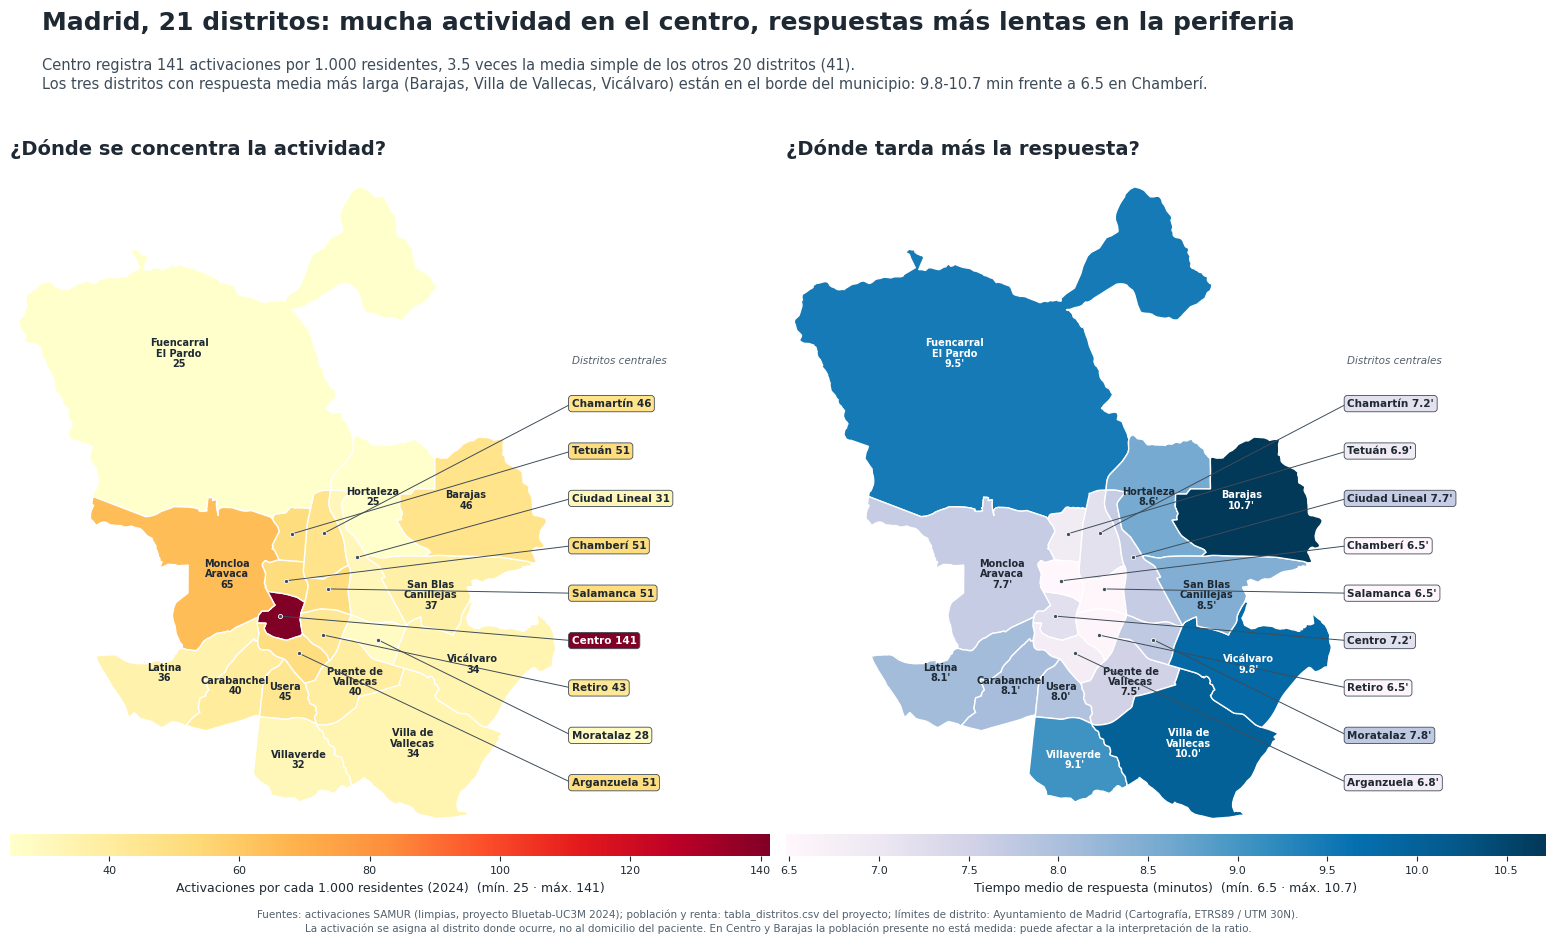

In [32]:
c1=plt.cm.YlOrRd; c2=plt.cm.PuBu
n1,col1,lab1,tc1=choro("activaciones_por_1000hab",c1,lambda v:f"{v:.0f}")
n2,col2,lab2,tc2=choro("tiempo_respuesta_medio_min",c2,lambda v:f"{v:.1f}'")
fig,axs=plt.subplots(1,2,figsize=(16,9.6),facecolor=BG)
draw(axs[0],col1,lab1,7,tc1,7.5);draw(axs[1],col2,lab2,7,tc2,7.5)
cbar(fig,axs[0],n1,c1,"Activaciones por cada 1.000 residentes (2024)");cbar(fig,axs[1],n2,c2,"Tiempo medio de respuesta (minutos)")
axs[0].set_title("¿Dónde se concentra la actividad?",fontsize=14,fontweight="bold",color=INK,loc="left")
axs[1].set_title("¿Dónde tarda más la respuesta?",fontsize=14,fontweight="bold",color=INK,loc="left")
top=t.nlargest(3,"activaciones_por_1000hab");slow=t.nlargest(3,"tiempo_respuesta_medio_min");fast=t.nsmallest(1,"tiempo_respuesta_medio_min").iloc[0]
tot=t.n_activaciones.sum()
fig.suptitle("Madrid, 21 distritos: mucha actividad en el centro, respuestas más lentas en la periferia",fontsize=18,fontweight="bold",color=INK,x=.04,ha="left",y=.975)
fig.text(.04,.925,f"Centro registra {top.iloc[0].activaciones_por_1000hab:.0f} activaciones por 1.000 residentes, {top.iloc[0].activaciones_por_1000hab/t[t.cod!=1].activaciones_por_1000hab.mean():.1f} veces la media simple de los otros 20 distritos ({t[t.cod!=1].activaciones_por_1000hab.mean():.0f}). "
 f"\nLos tres distritos con respuesta media más larga ({', '.join(slow.nombre)}) están en el borde del municipio: {slow.tiempo_respuesta_medio_min.min():.1f}-{slow.tiempo_respuesta_medio_min.max():.1f} min frente a {fast.tiempo_respuesta_medio_min:.1f} en {fast.nombre}.",
 fontsize=10.5,color="#3e4c59",ha="left",va="top")
foot(fig,"La activación se asigna al distrito donde ocurre, no al domicilio del paciente. En Centro y Barajas la población presente no está medida: puede afectar a la interpretación de la ratio.")
fig.subplots_adjust(left=.02,right=.98,top=.83,bottom=.09,wspace=.02)
fig.savefig(FIG_EDA / 'mapa_demanda_vs_respuesta.png',dpi=130,facecolor=BG);plt.show()

### 10.4 Mapa 2: bivariante (actividad y tiempo de respuesta juntos)

**Pregunta:** si cruzamos las dos variables, ¿qué tipos de distrito aparecen?

**Cómo está hecho:** cada variable se divide en terciles (tres grupos de 7 distritos: bajo, medio, alto) y se combinan en una paleta de 3×3. Es una clasificación para visualizar, **no es un modelo de clustering**.

**Cómo leerlo:** el eje horizontal de la leyenda es la actividad por 1.000 residentes y el vertical, la lentitud de la respuesta. El título del mapa y el recuadro de la derecha dicen qué distritos caen en cada esquina.

**Qué vemos:** más actividad por habitante suele ir con respuesta media más rápida (Spearman -0,60, n = 21). Alta actividad y respuesta rápida: Centro, Arganzuela, Salamanca, Tetuán y Chamberí. Baja actividad y respuesta lenta: Fuencarral-El Pardo, Hortaleza, Villaverde, Villa de Vallecas y Vicálvaro. Alta actividad con respuesta lenta solo aparece en Barajas. El tiempo de respuesta se asocia todavía más con la densidad (Spearman -0,88).

**Qué no dice:** con 21 distritos la correlación es orientativa y no es causal. Los terciles dependen de dónde se ponga el corte (un distrito cerca del límite podría cambiar de grupo). Aquí la correlación es de Spearman (por rangos); en la sección 8 usamos Pearson (-0,87 entre densidad y tiempo): son dos medidas distintas de lo mismo y las dos apuntan a lo mismo. No mide cobertura, porque no tenemos la ubicación exacta de las unidades.

**Para qué sirve en el proyecto:** da una primera clasificación a mano con la que comparar después el resultado del k-means y del jerárquico: si el clustering encuentra algo distinto, tendremos que explicar por qué.

Aclaración: actividad-tiempo y densidad-tiempo son pares de variables distintos. Spearman y Pearson no deben presentarse como si midieran necesariamente el mismo par. Aquí se especifica en cada cifra qué variables y coeficiente se usan.

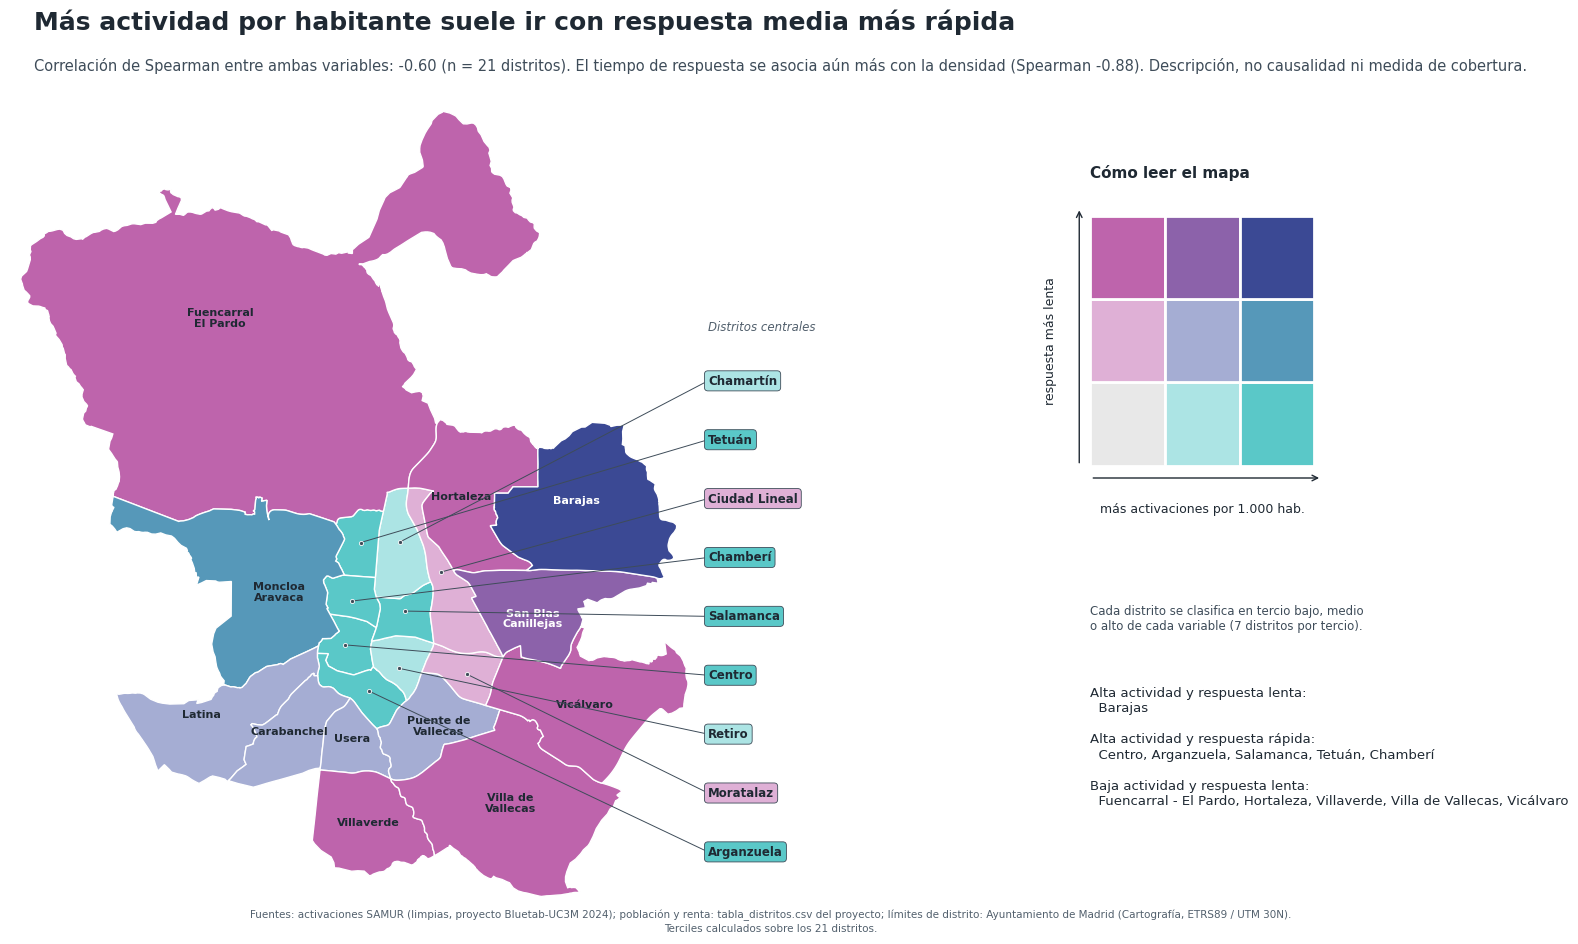

In [33]:
q=lambda s:pd.qcut(s,3,labels=False)
t["qa"]=q(t.activaciones_por_1000hab);t["qt"]=q(t.tiempo_respuesta_medio_min)
# bivariate palette (3x3), x=demand (cols), y=response time (rows)
pal=[["#e8e8e8","#ace4e4","#5ac8c8"],["#dfb0d6","#a5add3","#5698b9"],["#be64ac","#8c62aa","#3b4994"]]
colb={r.cod:pal[int(r.qt)][int(r.qa)] for _,r in t.iterrows()}
tcb={c:("white" if lum(colb[c])<.5 else INK) for c in colb}
labb={r.cod:r.lab for _,r in t.iterrows()}
fig=plt.figure(figsize=(16,9.6),facecolor=BG)
ax=fig.add_axes([.0,.04,.64,.84]);draw(ax,colb,labb,8,tcb,8.5)
# legend
lx=fig.add_axes([.70,.50,.14,.26]);lx.set_xlim(0,3);lx.set_ylim(0,3);lx.axis("off")
for i in range(3):
    for j in range(3): lx.add_patch(plt.Rectangle((j,i),1,1,fc=pal[i][j],ec="white",lw=2))
lx.annotate("",xy=(3.1,-.15),xytext=(0,-.15),arrowprops=dict(arrowstyle="->",color=INK),annotation_clip=False)
lx.annotate("",xy=(-.15,3.1),xytext=(-.15,0),arrowprops=dict(arrowstyle="->",color=INK),annotation_clip=False)
lx.text(1.5,-.45,"más activaciones por 1.000 hab.",ha="center",va="top",fontsize=9,color=INK)
lx.text(-.45,1.5,"respuesta más lenta",ha="right",va="center",rotation=90,fontsize=9,color=INK)
fig.text(.70,.80,"Cómo leer el mapa",fontsize=11,fontweight="bold",color=INK)
fig.text(.70,.355,"Cada distrito se clasifica en tercio bajo, medio\no alto de cada variable (7 distritos por tercio).",fontsize=8.5,color="#3e4c59",va="top")
hh=t[(t.qa==2)&(t.qt==2)].nombre.tolist();hl=t[(t.qa==2)&(t.qt==0)].nombre.tolist();lh=t[(t.qa==0)&(t.qt==2)].nombre.tolist()
txt=("Alta actividad y respuesta lenta:\n  "+(", ".join(hh) or "ninguno")+"\n\nAlta actividad y respuesta rápida:\n  "+(", ".join(hl) or "ninguno")+"\n\nBaja actividad y respuesta lenta:\n  "+(", ".join(lh) or "ninguno"))
fig.text(.70,.27,txt,fontsize=9.5,color=INK,va="top",linespacing=1.25)
rho=t[["activaciones_por_1000hab","tiempo_respuesta_medio_min"]].corr(method="spearman").iloc[0,1]
fig.text(.04,.975,"Más actividad por habitante suele ir con respuesta media más rápida",fontsize=18,fontweight="bold",color=INK,va="top")
rd=t[["densidad_hab_km2","tiempo_respuesta_medio_min"]].corr(method="spearman").iloc[0,1]
fig.text(.04,.925,f"Correlación de Spearman entre ambas variables: {rho:+.2f} (n = 21 distritos). El tiempo de respuesta se asocia aún más con la densidad (Spearman {rd:+.2f}). Descripción, no causalidad ni medida de cobertura.",fontsize=10.5,color="#3e4c59",va="top")
foot(fig,"Terciles calculados sobre los 21 distritos.")
fig.savefig(FIG_EDA / 'mapa_bivariante_demanda_respuesta.png',dpi=130,facecolor=BG);plt.show()

### 10.5 Mapa 3: contexto social

**Pregunta:** ¿cómo son socialmente los distritos que acabamos de ver?

**Cómo está hecho:** tres mapas con la renta media del hogar, el índice de vulnerabilidad (0 a 1) y el porcentaje de población mayor de 65 años. Los **6 valores marcados con \*** están imputados: en los datos originales faltaban 10 huecos y se rellenaron con la media de los 3 distritos más parecidos (como indica el README del proyecto); solo 6 de ellos se ven en estos mapas.

**Cómo leerlo:** cada mapa tiene su propia escala y su rango real en la leyenda (por ejemplo, mayores de 65: de 11,2 % a 26,8 %).

**Qué vemos:** el sur (Villaverde, Usera, Vallecas, Latina) reúne menos renta y más vulnerabilidad; Salamanca, Chamartín, Retiro y Chamberí combinan más renta y más población mayor.

**Qué no dice:** no explica las activaciones. En la sección 7 ya vimos que en estos 21 distritos no aparece la relación "más vulnerabilidad, más emergencias", y estos mapas no la contradicen ni la demuestran. Los valores con * son estimaciones metodológicas, no datos observados; su sensibilidad se mide en el cierre.

**Para qué sirve en el proyecto:** es el marco de las variables sociales del clustering y permite imaginar qué perfiles de distrito vamos a comparar.

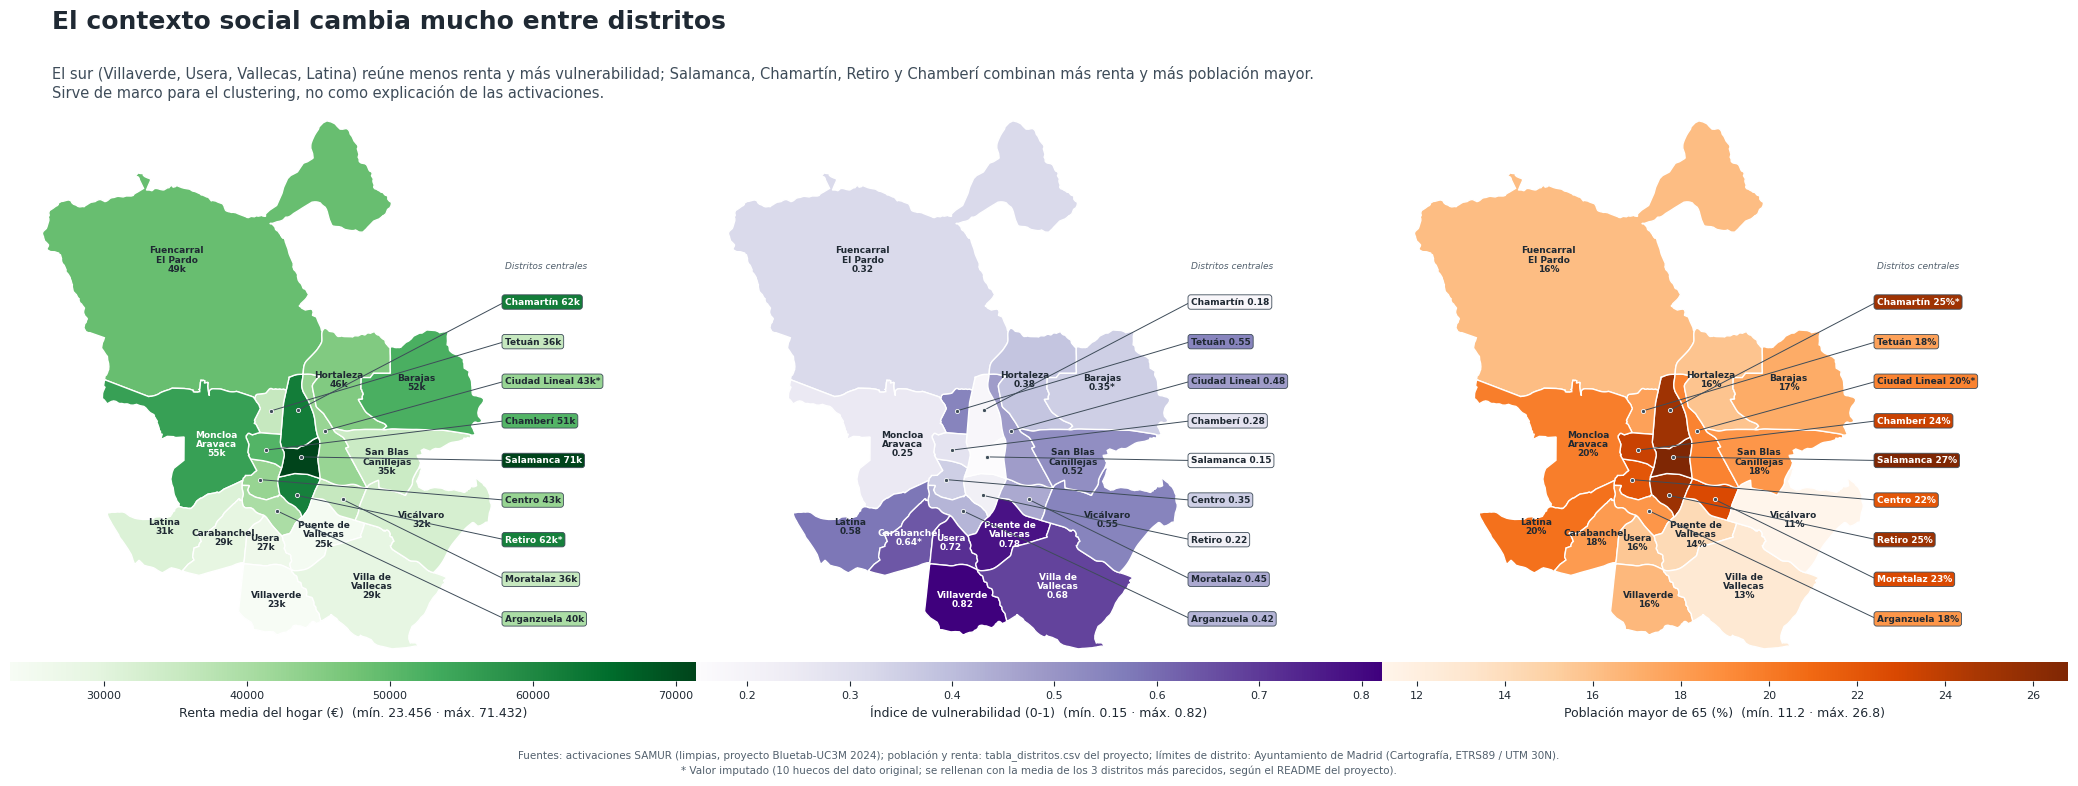

In [34]:
vars_=[("renta_media_hogar",plt.cm.Greens,lambda v:f"{v/1000:.0f}k","Renta media del hogar (€)"),
       ("indice_vulnerabilidad",plt.cm.Purples,lambda v:f"{v:.2f}","Índice de vulnerabilidad (0-1)"),
       ("pct_mayores_65",plt.cm.Oranges,lambda v:f"{v:.0f}%","Población mayor de 65 (%)")]
fig,axs=plt.subplots(1,3,figsize=(21,8),facecolor=BG)
for ax,(v,cmap,f,l) in zip(axs,vars_):
    n,col,lab,tc=choro(v,cmap,f);draw(ax,col,lab,6.5,tc,6.5);cbar(fig,ax,n,cmap,l)
fig.suptitle("El contexto social cambia mucho entre distritos",fontsize=18,fontweight="bold",color=INK,x=.03,ha="left",y=.97)
fig.text(.03,.90,"El sur (Villaverde, Usera, Vallecas, Latina) reúne menos renta y más vulnerabilidad; Salamanca, Chamartín, Retiro y Chamberí combinan más renta y más población mayor.\nSirve de marco para el clustering, no como explicación de las activaciones.",fontsize=10.5,color="#3e4c59",va="top")
foot(fig,"* Valor imputado (10 huecos del dato original; se rellenan con la media de los 3 distritos más parecidos, según el README del proyecto).")
fig.subplots_adjust(left=.01,right=.99,top=.84,bottom=.13,wspace=.0)
fig.savefig(FIG_EDA / 'mapa_contexto_social.png',dpi=120,facecolor=BG);plt.show()

## 11. Resumen para los slides

| # | Insight | Cifra clave | Gráfico |
|---|---------|-------------|---------|
| 1 | El SAMUR no para: volumen diario enorme | 146.567 activaciones en 2024; 400 al día de media (146.567 / 366 días, promedio calculado, no una serie diaria observada) | `activaciones_por_mes.png` |
| 2 | La demanda cambia con el mes | por día: junio 438, agosto 338 (-23% respecto a junio) | `activaciones_por_mes.png` |
| 3 | El día tiene un ritmo parecido todos los meses | pico a las 13h, 3,3x el valle de las 4h | `activaciones_por_hora.png`, `heatmap_mes_hora.png` |
| 4 | La noche es otra emergencia | a las 3h, el 31% de las activaciones es por intoxicación etílica (a mediodía no llega al 3%); de 0 a 7h es el tipo nº1 | `intoxicacion_nocturna.png` |
| 5 | Qué se atiende | cardiovascular y caídas = más de 1/3 del servicio; 40% de tipos de prioridad alta (catálogo) | `tipos_emergencia_top10.png`, `prioridades.png` |
| 6 | La edad y el sexo publicados tienen un patrón no interpretable clínicamente | reparto casi uniforme 0-99 y sexos próximos al50/50; causa no determinada, sin interpretación clínica | `edad_pacientes.png` |
| 7 | Centro es otro mundo | 141 act./1.000 residentes, 3,1x la media de distritos (2,2x el segundo); 24% de su demanda es de madrugada | `demanda_por_distrito.png` |
| 8 | En estos 21 distritos no se ve "más vulnerabilidad, más emergencias" | corr. renta-activaciones/residente +0,19 (+0,41 sin Centro); suben con el % de mayores del censo | `renta_vs_demanda.png` |
| 9 | Los distritos densos tienen respuesta más rápida | corr. -0,87 entre medias distritales (n=21); de 6,5 min (Chamberí) a 10,7 min (Barajas) | `densidad_vs_tiempo_respuesta.png` |
| 10 | Base de la unidad y distrito de la activación casi nunca coinciden | 5,8% de las identificadas (13% en los 7 distritos con base propia) | `oferta_vs_demanda.png` |
| 11 | Trauma y patología médica son 2 de cada 3 activaciones | 40,9% + 30,3% (categoría del catálogo canónico; el 100% de las activaciones ya trae tipo catalogado de la limpieza) | `activaciones_por_categoria.png` |
| 12 | Mapa: mucha actividad en el centro, respuestas más lentas en la periferia | Centro 141 act./1.000 residentes (3,5x la media simple de los otros 20 distritos, 41); Barajas 10,7 min, Villa de Vallecas 10,0, Vicálvaro 9,8 frente a 6,5 en Chamberí | `mapa_demanda_vs_respuesta.png` |
| 13 | Mapa bivariante: más actividad por habitante suele ir con respuesta más rápida | Spearman -0,60 (actividad vs tiempo) y -0,88 (densidad vs tiempo), n = 21; solo Barajas combina actividad alta y respuesta lenta. Terciles descriptivos, no clustering | `mapa_bivariante_demanda_respuesta.png` |
| 14 | Mapa social: el sur tiene menos renta y más vulnerabilidad | Villaverde, Usera, Vallecas y Latina frente a Salamanca, Chamartín, Retiro y Chamberí (más renta, más mayores). Marco del clustering, no explicación; 6 valores imputados marcados con * | `mapa_contexto_social.png` |

Conexión con el caso 1.3: los insights 7-9 y los tres mapas (12-14) son exactamente lo que el clustering tiene que capturar: distritos con perfiles de demanda y respuesta muy distintos, que piden estrategias distintas.

## 12. Limitaciones (para no vender de más)

- **Correlación ≠ causalidad**, y con 21 distritos cualquier correlación es frágil. Los insights 8 y 9 son hipótesis buenas para el clustering, no conclusiones cerradas.
- **Sin día de la semana:** el dato abierto solo trae año, mes y hora (confirmado por Bluetab). No podemos separar fin de semana de laborable ni cruzar con meteo o calendario.
- **La oferta es de catálogo y puede estar incompleta:** contar hospitales o bases no mide la cobertura real, y un distrito sin registros se contó como 0.
- **Datos imputados:** 10 huecos del socioeconómico se imputaron con los 3 distritos más parecidos (kNN) y están marcados como imputados en la tabla.
- **Edad y sexo del paciente:** el reparto es prácticamente uniforme (0-99, 50/50), su causa no se puede determinar con estos datos: patrón no interpretable clínicamente con estos datos; decisión definitiva: no usarlos para insights demográficos.
- **Lugar de activación ≠ residencia:** la demanda por 1.000 habitantes usa población residente, pero la gente se mueve; en Centro (ocio, turismo) el ratio mezcla demanda de visitantes con población vecina.
- **Prioridad y tipos son del catálogo:** desde la última limpieza, `tipo_emergencia` es el código del catálogo (39 tipos) y `prioridad` la gravedad típica que el catálogo asigna al tipo; la prioridad registrada en cada evento ya no está en el CSV (solo coincidía con la del catálogo en el 37,7% de las filas). Las filas cuyo tipo no describía una urgencia (5.513, el 3,6%) se eliminaron en la limpieza y no entran en estos gráficos. El script que genera el catálogo (`limpieza_tipos_emergencia.py`) cita un "anexo" como fuente de sus valores corregidos y ese documento no está en el repo; además el script sigue generando el catálogo antiguo de 42 tipos, no el de 39 que usa la limpieza (versión histórica; el cierre usa y comprueba el catálogo limpio de39códigos).
- **Catálogo de unidades sin zona de cobertura:** los `unidad_id` encajan al 100% con el catálogo, pero el catálogo no dice qué zona cubre cada unidad (base ≠ zona de cobertura).
- **Distritos sin asignar:** 601 activaciones (0,4%) sin distrito de Madrid ciudad (NO CONSTA, fuera de término y carreteras; sin afirmar cuántas de las39 etiquetas VALLECAS de origen sobreviven a filtros) quedan fuera del análisis por distrito.
- **Años:** las activaciones son de 2024 y el socioeconómico usa población de 2024; otros indicadores pueden ser de otra ola.
- **Mapas (sección 10):** son descriptivos. Los terciles del mapa bivariante dependen del corte y no son clustering. El denominador es población residente, no población presente (en Centro y Barajas no está medida). El tiempo de respuesta medio no es cobertura ni calidad del servicio. No hay ubicación exacta de las emergencias, por eso no hay puntos en los mapas. En el mapa social, 6 valores visibles son imputados (marcados con *).
- **Dos denominadores para Centro:** 3,1 veces la media simple de los 21 distritos (sección 7) y 3,5 veces la media simple de los otros 20 (mapa 1): mismo dato, distinto denominador, y en cada sitio se dice cuál es.

Aclaración de alcance: el correo del 14/10 confirma equivalencias de escritura de la prioridad registrada y pide criterio para el catálogo. No valida específicamente todas las categorías/prioridades/tiempos corregidos. El catálogo limpio utilizado es una decisión metodológica propia documentada.

In [35]:
plt.close('all')
plt.rcdefaults()

## F. Modelo, validación y análisis socioeconómico

A partir de las tablas generadas por el notebook de cruces se comprueba su identidad y escalado y se ejecuta todo el análisis. El principal excluye edad registrada de paciente; la comparación 10D se calcula de forma separada en el mismo notebook. La decisión y sus contrapartidas se explican junto al diagnóstico y las pruebas.

## 1. Carga y comprobaciones

Se cargan las tablas del caso y las activaciones limpias, y se comprueba antes de nada que cada distrito es quien dice ser (21 filas, id único, nombre coherente entre la tabla real y la normalizada) y que el escalado 0-1 del CSV sigue correspondiendo a los valores reales. Si algo no cuadrara, el notebook pararía aquí en vez de analizar datos mal unidos.

Para los análisis por distrito solo valen las filas de los 21 distritos oficiales: se dejan fuera 567 activaciones sin distrito (`NO CONSTA`, decisión ya tomada en la limpieza) y 34 fuera del término municipal o en carreteras de circunvalación.

In [36]:
%matplotlib inline
import json, os, urllib.request, urllib.parse
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MPath
from matplotlib.colors import Normalize, to_rgb
from matplotlib import cm
from shapely.geometry import shape

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

carpeta = Path('.') if Path('tabla_distritos.csv').is_file() else Path('1_3_clustering')
raiz = carpeta if (carpeta / 'data_clean').is_dir() else carpeta / '..'
FIG = carpeta / 'graficos_cierre_9D'
FIG.mkdir(exist_ok=True)

def guarda(fig, nombre):
    fig.savefig(FIG / nombre, dpi=150, bbox_inches='tight')
    print('guardado:', FIG / nombre)

df = pd.read_csv(carpeta / 'tabla_distritos.csv')
nrm = pd.read_csv(carpeta / 'tabla_distritos_norm.csv')

# No unir por posición sin comprobar la identidad de cada distrito.
for nombre, tabla in [('real', df), ('normalizada', nrm)]:
    assert len(tabla) == 21, f'Tabla {nombre}: se esperan 21 distritos'
    assert tabla['distrito_id'].notna().all() and tabla['distrito_id'].is_unique
assert set(df.distrito_id) == set(nrm.distrito_id)
nrm = nrm.set_index('distrito_id').loc[df.distrito_id].reset_index()
assert df['distrito'].equals(nrm['distrito'])

print('Entradas utilizadas (SHA-256):')
for archivo in ['tabla_distritos.csv', 'tabla_distritos_norm.csv']:
    print(' ', archivo, hashlib.sha256((carpeta / archivo).read_bytes()).hexdigest()[:16], '…')

act = pd.read_csv(raiz / 'data_clean' / 'activaciones_limpio.csv')
cat = pd.read_csv(raiz / 'data_clean' / 'tipos_emergencia_clean.csv')
n_total = len(act)
act = act[act.distrito.isin(df.distrito)].copy()
print(f'\nActivaciones: {n_total:,} en total; {n_total - len(act):,} fuera de los 21 distritos '
      f'(NO CONSTA / fuera de término / circunvalaciones) -> quedan {len(act):,}'.replace(',', '.'))

# Cada activación hereda la categoría corregida del catálogo de tipos (la columna
# "categoria" original era poco fiable; la limpieza ya dejó la versión corregida).
act = act.merge(cat[['codigo', 'categoria_correcta']],
                left_on='tipo_emergencia', right_on='codigo', how='left')
assert act['codigo'].notna().all(), 'Hay tipos de emergencia sin correspondencia en el catálogo'
act['hora'] = pd.to_datetime(act.hora_solicitud, format='%H:%M:%S', errors='coerce').dt.hour
print('Activaciones sin hora válida (cuentan para demanda, no para franjas):', int(act.hora.isna().sum()))
print('\nTablas cargadas y comprobadas:', df.shape, nrm.shape, act.shape)
COLORES_C = {0: '#e07b39', 1: '#2f7fb8', 2: '#5aa454'}


Entradas utilizadas (SHA-256):
  tabla_distritos.csv e4d4125966f0f9bf …
  tabla_distritos_norm.csv f9c792f732ca8f4c …

Activaciones: 146.567 en total; 601 fuera de los 21 distritos (NO CONSTA / fuera de término / circunvalaciones) -> quedan 145.966


Activaciones sin hora válida (cuentan para demanda, no para franjas): 1407

Tablas cargadas y comprobadas: (21, 22) (21, 22) (145966, 16)


## 1.1 Decisiones cerradas, evidencia y trazabilidad

El análisis es definitivo **dentro de su alcance exploratorio**: definitivo no significa que conozcamos los valores ausentes ni causalidad. No hay solicitudes abiertas de confirmación al cliente. Se conservan raw y valores observados; cada estimación se etiqueta como tal.

|Decisión|Evidencia y comprobación|Límite|
|---|---|---|
|Corregir hospital 13 a Villa y hospital 8 a Moncloa|Direcciones oficiales consultadas 17/11/2026, tabla siguiente y limpieza_hospitales.ipynb|Ubicación del recurso, no residencia ni cobertura|
|No completar camas con otra serie|SERMAS2024, tabla 10; valores del catálogo difieren de instaladas 2024 y dos referencias agrupan centros|No afirmar capacidad homogénea ni sumar conocidos como total|
|No repartir unidades VALLECAS|IDs locales sin correspondencia verificable con directorio municipal|Base y cobertura no son equivalentes|
|NO CONSTA en activaciones ambiguas|Origen dice solo VALLECAS; unidad/hospital no identifican el lugar del aviso|39 es número de origen, no un subconjunto final contado aquí|
|Mantener 21 distritos con imputación social kNN3|Notebook de limpieza muestra vecinos; prueba sin 4 distritos afectados más abajo, ARI|La estabilidad de estas pruebas no convierte imputaciones en observaciones|
|No análisis diario ni meteo|CSV tiene año,mes,horas, no día ni clave compatible|No inventar fecha|
|Tasas por población residente|Tamaño de distritos distinto; se muestran conteos y denominador|Visitantes no medidos; no riesgo individual|
|Prioridad de catálogo|`prioridad` deriva de tipo en CSV limpio, no de triaje registrado por evento|Es mezcla de gravedad típica, no gravedad clínica observada|

La edad del paciente presenta un patrón de registro anómalo en la exploración. No se usa para explicar diferencias demográficas o clínicas. Se excluye edad_media_paciente del modelo principal 9D por prudencia interpretativa: el patrón no explicado y su influencia sobre los grupos hacen débil usarla para definir perfiles. No se excluye por un rango pequeño ni por buscar mejor silueta. Se conserva 10D como comparación ejecutada; se explican ventajas y contrapartidas de robustez en 7.9. pct_mayores_65 del censo se mantiene.

Fuentes oficiales: [Infanta Leonor](https://www.comunidad.madrid/hospital/infantaleonor/ciudadanos/llegar-contactar), [Jiménez Díaz](https://www.comunidad.madrid/centros/hospital-universitario-fundacion-jimenez-diaz), [SERMAS2024, tabla 10, p 31](https://gestiona3.madrid.org/bvirtual/BVCM051700.pdf), [bases municipales](https://www.madrid.es/portales/munimadrid/es/Inicio/El-Ayuntamiento/Villa-de-Vallecas/SAMUR-Proteccion-Civil/?idCapitulo=1231815&vgnextchannel=8291ca5d5fb96010VgnVCM100000dc0ca8c0RCRD&vgnextfmt=default&vgnextoid=c88fcdb1bfffa010VgnVCM100000d90ca8c0RCRD).


In [37]:
# Comprobaciones reproducibles de decisiones y entradas, sin modificar datos originales.
hospitales = pd.read_csv(raiz / 'data_clean/hospitales_limpio.csv')
assert hospitales.set_index('hospital_id').loc[13,'distrito'] == 'VILLA DE VALLECAS'
assert hospitales.set_index('hospital_id').loc[8,'distrito'] == 'MONCLOA-ARAVACA'
print(hospitales.loc[hospitales.hospital_id.isin([8,13]), ['hospital_id','nombre_corto','distrito','camas']].to_string(index=False))
print('Celdas vacías actuales por columna de oferta:')
print(df[['unidades_samur','num_hospitales_cat','camas_hospital']].isna().sum().to_string())
print('Tiempos: duración observada en minutos = intervención-solicitud, regla nocturna documentada en limpieza.')
print('Prioridad: mezcla de tipos según catálogo; no triaje observado.')

comparacion_camas=pd.DataFrame([
('La Paz',1328,1187,'Complejo La Paz-CarlosIII-Cantoblanco: perímetro distinto'),
('Gregorio Marañón',1500,1239,'Diferencia'),('Clínico San Carlos',961,861,'Diferencia'),
('12 de Octubre',1256,1161,'Diferencia'),('Ramón y Cajal',1092,877,'Diferencia'),
('La Princesa',480,533,'Diferencia'),('Puerta de Hierro',613,613,'Coincidencia numérica'),
('Getafe',560,543,'Diferencia'),('Severo Ochoa',425,386,'Diferencia'),
('Infanta Leonor',260,402,'Incluye Virgen de la Torre: perímetro distinto'),
('Henares',310,258,'Diferencia'),('Infanta Sofía',283,334,'Diferencia'),
('Infanta Cristina',213,188,'Diferencia'),('Gómez Ulla',500,475,'Diferencia')],
columns=['hospital','catalogo_sin_ano_definido','instaladas2024_SERMAS','comparabilidad'])
display(comparacion_camas)
print('Fuente: Memoria SERMAS2024, tabla10, p31/PDF32. Diferencia no equivale a error histórico.')
print('Beata María Ana:150 en catálogo frente a163 en ficha Ministerio sin año visible; no contraste2024.')


 hospital_id           nombre_corto          distrito  camas
           8 FUNDACION JIMENEZ DIAZ   MONCLOA-ARAVACA    NaN
          13         INFANTA LEONOR VILLA DE VALLECAS  260.0
Celdas vacías actuales por columna de oferta:
unidades_samur        2
num_hospitales_cat    0
camas_hospital        1
Tiempos: duración observada en minutos = intervención-solicitud, regla nocturna documentada en limpieza.
Prioridad: mezcla de tipos según catálogo; no triaje observado.


,hospital,catalogo_sin_ano_definido,instaladas2024_SERMAS,comparabilidad
0,La Paz,1328,1187,Complejo La Paz-CarlosIII-Cantoblanco: perímet...
1,Gregorio Marañón,1500,1239,Diferencia
2,Clínico San Carlos,961,861,Diferencia
3,12 de Octubre,1256,1161,Diferencia
4,Ramón y Cajal,1092,877,Diferencia
5,La Princesa,480,533,Diferencia
6,Puerta de Hierro,613,613,Coincidencia numérica
7,Getafe,560,543,Diferencia
8,Severo Ochoa,425,386,Diferencia
9,Infanta Leonor,260,402,Incluye Virgen de la Torre: perímetro distinto


Fuente: Memoria SERMAS2024, tabla10, p31/PDF32. Diferencia no equivale a error histórico.
Beata María Ana:150 en catálogo frente a163 en ficha Ministerio sin año visible; no contraste2024.


### 1.2 Diagnóstico de edad registrada: no equivale al censo

`paciente_edad` procede del CSV limpio de activaciones. La limpieza conserva edades válidas y pasa fuera de 0..115 a nulo: no genera ni imputa edades. La distribución casi uniforme 0..99 es un hecho del archivo, no prueba su causa. No se afirma anonimización ni datos sintéticos. El min-max aplicado a una media distrital de rango estrecho puede amplificar diferencias pequeñas. Se muestra el diagnóstico reproducible para decidir su papel en el modelo. `pct_mayores_65` procede del socioeconómico y describe residentes: es otra variable y otra fuente, no la edad de pacientes.


Edad registrada en activaciones distritales: n_total= 145966 n_validos= 145063 nulos= 903
Rango y valores únicos: 0.0 99.0 100
Conteos por edad min/max/media/desv: 1318 1514 1450.63 39.06085772305322
Rango de medias por distrito: 48.67 50.7
guardado: 1_3_clustering/graficos_cierre_9D/18_diagnostico_edad_registrada.png


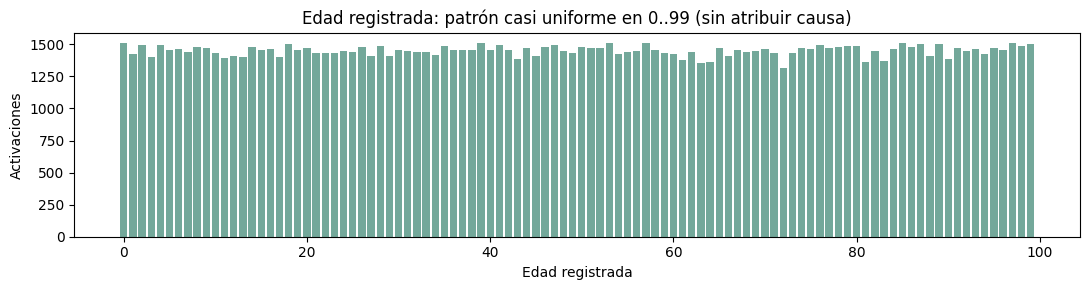

,distrito,edad_media_paciente,pct_mayores_65
0,CENTRO,50.07,22.1
1,ARGANZUELA,49.27,18.5
2,RETIRO,49.14,25.3
3,SALAMANCA,49.33,26.8
4,CHAMARTIN,49.02,25.2
5,TETUAN,49.94,17.8
6,CHAMBERI,49.49,23.5
7,FUENCARRAL-EL PARDO,49.52,16.2
8,MONCLOA-ARAVACA,49.07,19.8
9,LATINA,49.55,20.5


In [38]:
edades=act.paciente_edad
conteo_edades=edades.value_counts().sort_index()
print('Edad registrada en activaciones distritales:', 'n_total=',len(edades), 'n_validos=',edades.notna().sum(), 'nulos=',edades.isna().sum())
print('Rango y valores únicos:',edades.min(),edades.max(),edades.nunique())
print('Conteos por edad min/max/media/desv:',conteo_edades.min(),conteo_edades.max(),conteo_edades.mean(),conteo_edades.std())
print('Rango de medias por distrito:',df.edad_media_paciente.min(),df.edad_media_paciente.max())
fig,ax=plt.subplots(figsize=(11,3));ax.bar(conteo_edades.index,conteo_edades,color='#73a89a');ax.set(xlabel='Edad registrada',ylabel='Activaciones',title='Edad registrada: patrón casi uniforme en 0..99 (sin atribuir causa)');fig.tight_layout();guarda(fig,'18_diagnostico_edad_registrada.png');plt.show()
display(df[['distrito','edad_media_paciente','pct_mayores_65']])


## 2. Selección de variables para el clustering

Criterios de selección del modelo principal 9D, en este orden. Además de las reglas siguientes se excluye edad_media_paciente por el diagnóstico 1.2 y la comparación 7.9; no se altera el archivo de activaciones ni el censo.

1. **Fuera las 3 columnas de oferta** (`unidades_samur`, `num_hospitales_cat`, `camas_hospital`): decisión definitiva del alcance. Las unidades carecen de distrito demostrable en 15 filas; las camas no tienen año/definición común verificados; contar hospitales de catálogo no mide capacidad operativa. Los perfiles se definen con contexto y servicio y la oferta se analiza aparte con bases conocidas. Las dos correcciones geográficas y su evidencia se auditan a continuación; no se imputan recursos.
2. **Fuera `num_bases_samur`**: es oferta, y la oferta no debe decidir cómo se agrupan los distritos por su perfil socio-sanitario.
3. **Fuera las redundantes por construcción**: `poblacion` y `superficie_km2` (se prefiere densidad a tamaño absoluto) y `n_activaciones` (ya está en `activaciones_por_1000hab`, comparable entre distritos).
4. **Fuera las muy correlacionadas entre sí** (|r| > 0,85): con 21 distritos, meter dos columnas casi idénticas cuenta esa dimensión dos veces. Se queda una representante por grupo: `renta_media_hogar` (eje económico) y `pct_mayores_65` (eje edad), por ser las más directas de explicar.


#### Escalado de las variables para K-Means

Las variables seleccionadas mezclan euros, porcentajes, habitantes y minutos. K-Means asigna los grupos por distancias euclídeas: sin escalar, una variable con rango numérico mayor podría pesar mucho más en la distancia aunque no sea conceptualmente más importante. Se usa min-max por variable para llevar los valores a `[0, 1]` en `tabla_distritos_norm.csv`. Esto iguala los rangos, no decide pesos ni corrige redundancia; por eso la selección de variables correlacionadas se justifica aparte. En la celda siguiente se recalcula el min-max desde los datos reales, se compara con el CSV (tolerancia de 0,000051 por el redondeo a cuatro decimales) y se comprueba que la matriz `X` sea finita y esté en `[0, 1]` antes de entrar a K-Means.

El mapa de calor de abajo enseña **todas las combinaciones de variables** de la tabla, no solo las candidatas, para que la regla 4 se pueda auditar de un vistazo.

guardado: 1_3_clustering/graficos_cierre_9D/00_correlacion_todas_las_variables.png


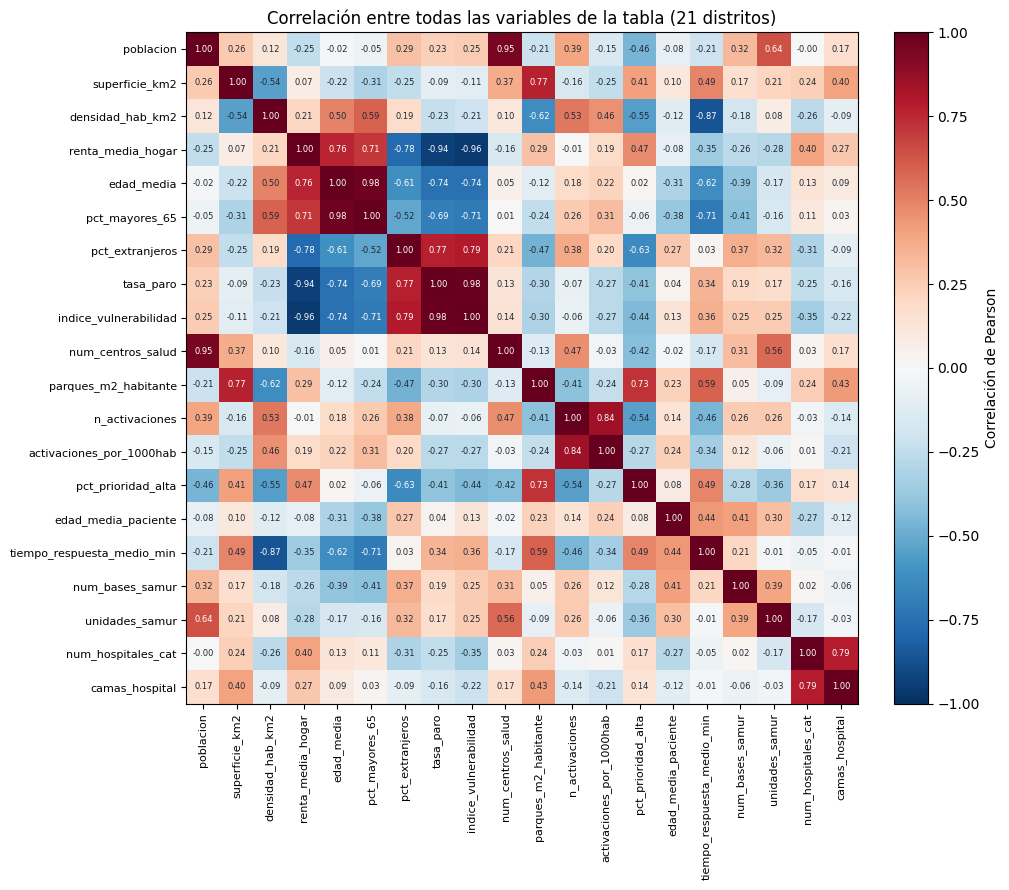

Pares de candidatas con |r| > 0,85 (regla 4):
  densidad_hab_km2 ~ tiempo_respuesta_medio_min: r = 0.87
  renta_media_hogar ~ tasa_paro: r = 0.94
  renta_media_hogar ~ indice_vulnerabilidad: r = 0.96
  edad_media ~ pct_mayores_65: r = 0.98
  tasa_paro ~ indice_vulnerabilidad: r = 0.98

Variables finales del clustering (9):
 - densidad_hab_km2
 - renta_media_hogar
 - pct_mayores_65
 - pct_extranjeros
 - num_centros_salud
 - parques_m2_habitante
 - activaciones_por_1000hab
 - pct_prioridad_alta
 - tiempo_respuesta_medio_min

Matriz del clustering sin huecos: (21, 9)


In [39]:
numericas = [c for c in df.columns if c not in ('distrito_id', 'distrito')]
corr = df[numericas].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(numericas))); ax.set_yticks(range(len(numericas)))
ax.set_xticklabels(numericas, rotation=90, fontsize=8)
ax.set_yticklabels(numericas, fontsize=8)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=6,
                color='white' if abs(v) > 0.6 else '#1f2933')
fig.colorbar(im, fraction=0.046, pad=0.04, label='Correlación de Pearson')
ax.set_title('Correlación entre todas las variables de la tabla (21 distritos)')
fig.tight_layout()
guarda(fig, '00_correlacion_todas_las_variables.png')
plt.show()

candidatas = ['densidad_hab_km2', 'renta_media_hogar', 'edad_media', 'pct_mayores_65',
              'pct_extranjeros', 'tasa_paro', 'indice_vulnerabilidad', 'num_centros_salud',
              'parques_m2_habitante', 'activaciones_por_1000hab', 'pct_prioridad_alta',
              'edad_media_paciente', 'tiempo_respuesta_medio_min']
cc = df[candidatas].corr().abs()
print('Pares de candidatas con |r| > 0,85 (regla 4):')
for i, a in enumerate(candidatas):
    for b in candidatas[i+1:]:
        if cc.loc[a, b] > 0.85:
            print(f'  {a} ~ {b}: r = {cc.loc[a, b]:.2f}')

variables = ['densidad_hab_km2', 'renta_media_hogar', 'pct_mayores_65', 'pct_extranjeros',
             'num_centros_salud', 'parques_m2_habitante', 'activaciones_por_1000hab',
             'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
variables = [v for v in variables if v != 'edad_media_paciente']
print(f'\nVariables finales del clustering ({len(variables)}):')
for v in variables:
    print(' -', v)

# Comprobar que el CSV normalizado sigue correspondiendo a los valores reales
# (el cruce guarda cuatro decimales: tolerancia de medio último decimal).
recalculada = (df[variables] - df[variables].min()) / (df[variables].max() - df[variables].min())
assert np.allclose(recalculada, nrm[variables], atol=0.000051, rtol=0), 'Escalado desactualizado'
X = nrm[variables].to_numpy()
assert np.isfinite(X).all() and ((X >= 0) & (X <= 1)).all().all()
print('\nMatriz del clustering sin huecos:', X.shape)

`renta_media_hogar`, `tasa_paro` e `indice_vulnerabilidad` miden casi lo mismo (r hasta 0,98), y `edad_media` y `pct_mayores_65` también (r = 0,98). `densidad_hab_km2` y `tiempo_respuesta_medio_min` (r = -0,87) se conservan las dos porque miden cosas distintas del caso (geografía del distrito frente a servicio prestado); la sensibilidad a esta decisión se mide en la sección de robustez.

## 3. Elección de algoritmo y de k (ensayo y error)

Se prueban los dos algoritmos que sugiere el enunciado más el jerárquico:

- **K-means** con k = 2…8 (codo por inercia y silueta).
- **Jerárquico Ward** con k = 2…8 (silueta).
- **DBSCAN** se evalúa con la rejilla ampliada de la sección 3.1. Se reportan grupos, ruido y tamaños para todas las configuraciones; se prefiere k-means para resumir todos los distritos, sin afirmar que DBSCAN sea inválido en general.

Para elegir k se miran tres cosas: la silueta, que el codo deje de bajar fuerte y que los grupos sean accionables para el caso (perfiles distintos con los que planificar).

guardado: 1_3_clustering/graficos_cierre_9D/01_eleccion_de_k.png


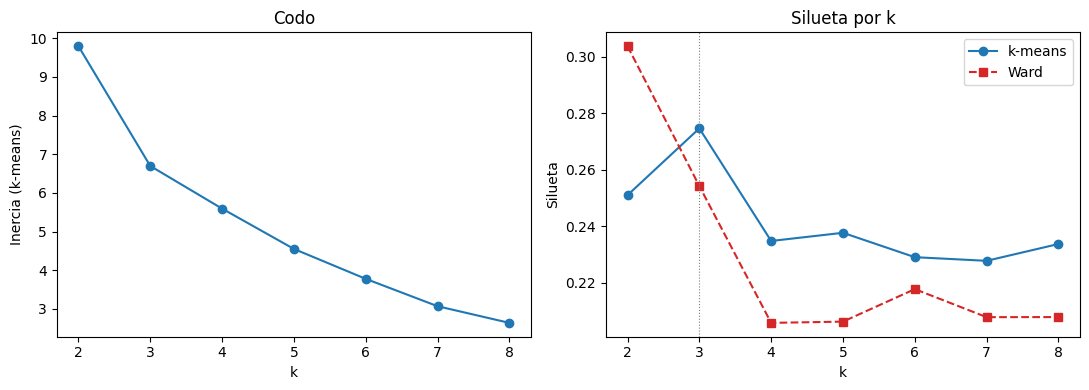

 k  inercia  silueta_kmeans  silueta_ward
 2      9.8           0.251         0.304
 3      6.7           0.275         0.254
 4      5.6           0.235         0.206
 5      4.5           0.238         0.206
 6      3.8           0.229         0.218
 7      3.1           0.228         0.208
 8      2.6           0.234         0.208

Prueba de DBSCAN (rejilla):
  eps=0.3, min_samples=2: 0 grupos, 21 puntos de ruido
  eps=0.3, min_samples=3: 0 grupos, 21 puntos de ruido
  eps=0.4, min_samples=2: 3 grupos, 15 puntos de ruido
  eps=0.4, min_samples=3: 0 grupos, 21 puntos de ruido
  eps=0.5, min_samples=2: 4 grupos, 11 puntos de ruido
  eps=0.5, min_samples=3: 2 grupos, 15 puntos de ruido
  eps=0.6, min_samples=2: 3 grupos, 6 puntos de ruido
  eps=0.6, min_samples=3: 2 grupos, 8 puntos de ruido
  eps=0.7, min_samples=2: 1 grupos, 3 puntos de ruido
  eps=0.7, min_samples=3: 1 grupos, 3 puntos de ruido

Qué hace cada k candidata (k-means):
  k=2:
   - Centro + Arganzuela + Retiro + Salamanc

In [40]:
ks = range(2, 9)
inercias, sil_km, sil_hc = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    hc = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X)
    inercias.append(km.inertia_)
    sil_km.append(silhouette_score(X, km.labels_))
    sil_hc.append(silhouette_score(X, hc.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(list(ks), inercias, 'o-', color='#1f77b4')
ax1.set_xlabel('k'); ax1.set_ylabel('Inercia (k-means)'); ax1.set_title('Codo')
ax2.plot(list(ks), sil_km, 'o-', label='k-means', color='#1f77b4')
ax2.plot(list(ks), sil_hc, 's--', label='Ward', color='#d62728')
ax2.axvline(3, color='grey', lw=0.8, ls=':')
ax2.set_xlabel('k'); ax2.set_ylabel('Silueta'); ax2.set_title('Silueta por k'); ax2.legend()
fig.tight_layout()
guarda(fig, '01_eleccion_de_k.png')
plt.show()

print(pd.DataFrame({'k': list(ks), 'inercia': np.round(inercias, 1),
                    'silueta_kmeans': np.round(sil_km, 3), 'silueta_ward': np.round(sil_hc, 3)}).to_string(index=False))

print('\nPrueba de DBSCAN (rejilla):')
for eps in (0.3, 0.4, 0.5, 0.6, 0.7):
    for ms in (2, 3):
        lab = DBSCAN(eps=eps, min_samples=ms).fit(X).labels_
        print(f'  eps={eps}, min_samples={ms}: {len(set(lab) - {-1})} grupos, {(lab == -1).sum()} puntos de ruido')

print('\nQué hace cada k candidata (k-means):')
for k in (2, 3, 4):
    lab = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X).labels_
    grupos = [' + '.join(df.distrito.str.title()[lab == c]) for c in range(k)]
    print(f'  k={k}:')
    for g in grupos:
        print('   -', g)

### 3.1 DBSCAN: rejilla y evidencia del descarte

Se prueba la misma matriz 9D min-max y distancia euclídea: `eps=0,2...1,2` (paso 0,1) y `min_samples=2...5`, incluyendo puntos propios como define sklearn. No se comparan siluetas de una partición completa con otra que descarta gran parte de los distritos como ruido. Se muestran **todos** los resultados de esta rejilla, no solo la configuración peor. El rango amplía el ensayo inicial 0,3...0,7. La distancia ordenada al vecino de orden `min_samples` ayuda a leer las escalas, sin fijar un eps óptimo automático. DBSCAN admite ruido; no es un error del algoritmo. Se evalúa si ofrece perfiles multigrupo razonables y estables para resumir los 21 distritos. Ninguna rejilla prueba que DBSCAN sea inútil en cualquier parametrización o escalado.


,eps,min_samples,grupos,ruido,tamanos,silueta_sin_ruido
0,0.2,2,0,21,[],NaN
1,0.3,2,0,21,[],NaN
2,0.4,2,3,15,"[2, 2, 2]",0.539
3,0.5,2,4,11,"[2, 3, 3, 2]",0.397
4,0.6,2,3,6,"[10, 3, 2]",0.390
5,0.7,2,1,3,[18],NaN
6,0.8,2,1,2,[19],NaN
7,0.9,2,1,1,[20],NaN
8,1.0,2,1,1,[20],NaN
9,1.1,2,1,0,[21],NaN


guardado: 1_3_clustering/graficos_cierre_9D/14_dbscan_rejilla_completa.png


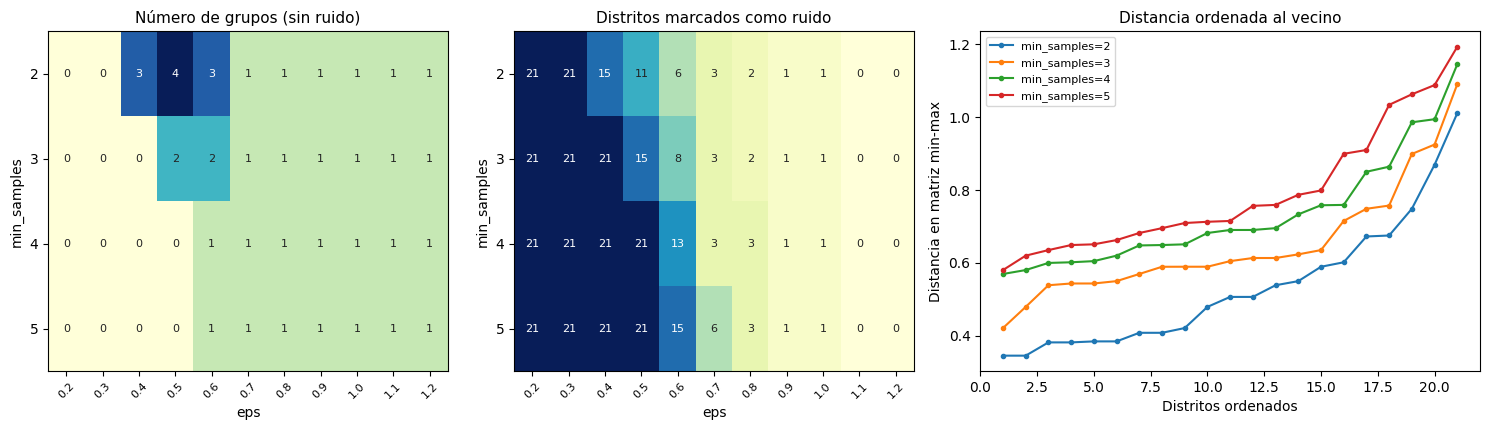

Configuraciones multigrupo sin ruido en esta rejilla: 0 de 44
Configuraciones con2+ grupos: 5
 eps  min_samples  grupos  ruido      tamanos
 0.4            2       3     15    [2, 2, 2]
 0.5            2       4     11 [2, 3, 3, 2]
 0.6            2       3      6   [10, 3, 2]
 0.5            3       2     15       [3, 3]
 0.6            3       2      8      [10, 3]


In [41]:
from sklearn.neighbors import NearestNeighbors
rejilla=[]
for ms in [2,3,4,5]:
    for eps in np.round(np.arange(.2,1.21,.1),2):
        labels=DBSCAN(eps=float(eps),min_samples=ms).fit_predict(X)
        ids=sorted(set(labels)-{-1}); sizes=[int((labels==c).sum()) for c in ids]
        good=labels!=-1
        sil=float(silhouette_score(X[good], labels[good])) if len(ids)>=2 and good.sum()>len(ids) else np.nan
        rejilla.append(dict(eps=eps,min_samples=ms,grupos=len(ids),ruido=int((~good).sum()),tamanos=str(sizes),silueta_sin_ruido=sil))
dbscan_pruebas=pd.DataFrame(rejilla)
display(dbscan_pruebas.round(3))
fig,axes=plt.subplots(1,3,figsize=(15,4.4),gridspec_kw={'width_ratios':[1,1,1.25]})
for ax,var,title in zip(axes[:2],['grupos','ruido'],['Número de grupos (sin ruido)','Distritos marcados como ruido']):
    mat=dbscan_pruebas.pivot(index='min_samples',columns='eps',values=var)
    ax.imshow(mat,cmap='YlGnBu',aspect='auto',vmin=0)
    ax.set_xticks(range(len(mat.columns)));ax.set_xticklabels([f'{v:.1f}' for v in mat.columns],rotation=45,fontsize=8)
    ax.set_yticks(range(4));ax.set_yticklabels(mat.index);ax.set_xlabel('eps');ax.set_ylabel('min_samples');ax.set_title(title,fontsize=11)
    for i in range(4):
        for j in range(len(mat.columns)):
            ax.text(j,i,str(mat.iloc[i,j]),ha='center',va='center',fontsize=8,color='white' if mat.iloc[i,j]>mat.to_numpy().max()*.55 else '#222')
for ms in [2,3,4,5]:
    dist,_=NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)
    axes[2].plot(range(1,22),np.sort(dist[:,-1]),marker='.',label=f'min_samples={ms}')
axes[2].set_title('Distancia ordenada al vecino',fontsize=11);axes[2].set_xlabel('Distritos ordenados');axes[2].set_ylabel('Distancia en matriz min-max');axes[2].legend(fontsize=8)
fig.tight_layout();guarda(fig,'14_dbscan_rejilla_completa.png');plt.show()
completas=dbscan_pruebas.query('grupos >= 2 and ruido == 0')
print('Configuraciones multigrupo sin ruido en esta rejilla:',len(completas),'de',len(dbscan_pruebas))
print('Configuraciones con2+ grupos:',len(dbscan_pruebas.query('grupos >= 2')))
print(dbscan_pruebas.query('grupos >= 2')[['eps','min_samples','grupos','ruido','tamanos']].to_string(index=False))


**Lectura de la rejilla 9D:**5 de 44 configuraciones producen 2+grupos y dejan 6..15 distritos como ruido. Ninguna multigrupo incluye los 21 distritos. Las siluetas de puntos no ruido no se comparan como si cubrieran toda la ciudad. Se prefiere KMeans para resumir todos los distritos; no se declara DBSCAN inválido para otras tareas o parámetros.

**Lectura y elección:** k 3 es la mayor silueta KMeans ensayada(0,2747); k 4 baja a 0,2349. Ward k 2 alcanza 0,3038 pero ofrece una división menos detallada de perfiles sociales. El codo es gradual. Se elige KMeans k 3 por balance de separación modesta e interpretación social, no por máximo universal entre algoritmos. La silueta no prueba validez externa.

## 4. Modelo principal 9D y perfiles

In [42]:
k_final = 3
km = KMeans(n_clusters=k_final, n_init=50, random_state=42).fit(X)
df['cluster'] = pd.Series(km.labels_).map({0:1,1:0,2:2}).to_numpy()  # solo renombrar etiquetas, no reasignar distritos

# Los nombres salen de la tabla de perfiles de abajo, no al revés.
nombres = {0: 'Denso y vulnerable', 1: 'Acomodado y envejecido', 2: 'Periférico y disperso'}
df['cluster_nombre'] = df.cluster.map(nombres)

for c in range(k_final):
    d = df[df.cluster == c]
    print(f'Cluster {c} - {nombres[c]} ({len(d)} distritos, '
          f'{int(d.n_activaciones.sum()):,} activaciones, {d.n_activaciones.sum() / df.n_activaciones.sum() * 100:.0f}% del total):'.replace(',', '.'))
    print('  ', ', '.join(d.distrito.str.title()))

cols_desc = ['renta_media_hogar', 'tasa_paro', 'indice_vulnerabilidad', 'pct_mayores_65',
             'pct_extranjeros', 'densidad_hab_km2', 'activaciones_por_1000hab',
             'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
perfil = df.groupby('cluster_nombre')[cols_desc].mean().round(2)
perfil.loc['MEDIA 21 DISTRITOS'] = df[cols_desc].mean().round(2)
print('\nPerfil de cada grupo (valores reales, no normalizados):')
print(perfil.to_string())

Cluster 0 - Denso y vulnerable (9 distritos. 83.261 activaciones. 57% del total):
   Centro, Arganzuela, Tetuan, Latina, Carabanchel, Usera, Puente De Vallecas, Ciudad Lineal, Villaverde
Cluster 1 - Acomodado y envejecido (5 distritos. 29.203 activaciones. 20% del total):
   Retiro, Salamanca, Chamartin, Chamberi, Moratalaz
Cluster 2 - Periférico y disperso (7 distritos. 33.502 activaciones. 23% del total):
   Fuencarral-El Pardo, Moncloa-Aravaca, Hortaleza, Villa De Vallecas, Vicalvaro, San Blas-Canillejas, Barajas

Perfil de cada grupo (valores reales, no normalizados):
                        renta_media_hogar  tasa_paro  indice_vulnerabilidad  pct_mayores_65  pct_extranjeros  densidad_hab_km2  activaciones_por_1000hab  pct_prioridad_alta  edad_media_paciente  tiempo_respuesta_medio_min
cluster_nombre                                                                                                                                                                                         

guardado: 1_3_clustering/graficos_cierre_9D/02_perfil_de_los_grupos.png


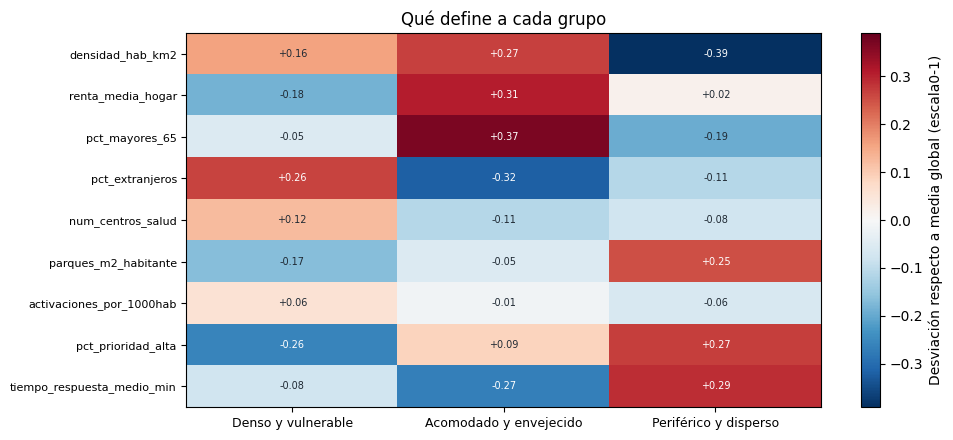

In [43]:
# Qué variable hace distinto a cada grupo: media normalizada del grupo menos media global
med_global = nrm[variables].mean()
dif = nrm[variables].assign(cluster=df.cluster).groupby('cluster').mean() - med_global

fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(dif.T, cmap='RdBu_r', vmin=-np.abs(dif.to_numpy()).max(),
               vmax=np.abs(dif.to_numpy()).max(), aspect='auto')
fig.colorbar(im, label='Desviación respecto a media global (escala0-1)')
ax.set_xticks(range(k_final)); ax.set_xticklabels([nombres[c] for c in range(k_final)], fontsize=9)
ax.set_yticks(range(len(variables))); ax.set_yticklabels(variables, fontsize=8)
for i in range(len(variables)):
    for j in range(k_final):
        ax.text(j, i, f'{dif.T.to_numpy()[i, j]:+.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(dif.T.to_numpy()[i, j]) > 0.25 else '#1f2933')
ax.set_title('Qué define a cada grupo')
fig.tight_layout()
guarda(fig, '02_perfil_de_los_grupos.png')
plt.show()

### 4.1 ¿Qué distritos encajan mejor? Silueta individual

La silueta compara distancia media al propio grupo (`a`) con la menor distancia media a otro (`b`): `(b-a)/max(a,b)`. Cercana a 1 indica mejor separación, alrededor de 0 una frontera y negativa mayor proximidad media a otro grupo. Se calcula en **las mismas 9 variables min-max**, no en el PCA2D. La media reproduce la silueta global; no es validación externa. Un distrito con silueta negativa no prueba que esté mal asignado ni exige moverlo a mano.


guardado: 1_3_clustering/graficos_cierre_9D/15_silueta_por_distrito.png


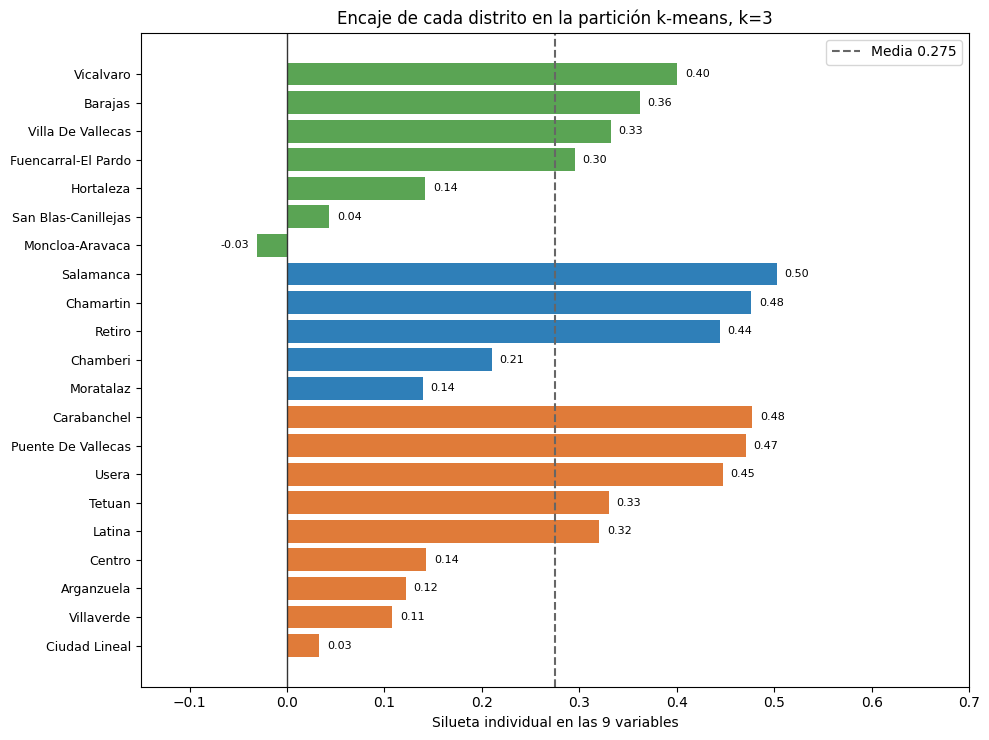

,distrito,cluster,cluster_nombre,silueta
14,CIUDAD LINEAL,0,Denso y vulnerable,0.033
16,VILLAVERDE,0,Denso y vulnerable,0.108
1,ARGANZUELA,0,Denso y vulnerable,0.122
0,CENTRO,0,Denso y vulnerable,0.143
9,LATINA,0,Denso y vulnerable,0.320
5,TETUAN,0,Denso y vulnerable,0.330
11,USERA,0,Denso y vulnerable,0.447
12,PUENTE DE VALLECAS,0,Denso y vulnerable,0.471
10,CARABANCHEL,0,Denso y vulnerable,0.477
13,MORATALAZ,1,Acomodado y envejecido,0.139


Siluetas negativas: ['MONCLOA-ARAVACA']


In [44]:
from sklearn.metrics import silhouette_samples
siluetas = df[['distrito','cluster','cluster_nombre']].copy()
siluetas['silueta']=silhouette_samples(X,df.cluster)
assert np.isclose(siluetas.silueta.mean(),silhouette_score(X,df.cluster))
siluetas=siluetas.sort_values(['cluster','silueta'])
fig,ax=plt.subplots(figsize=(10,7.5))
ax.barh(range(21),siluetas.silueta,color=[COLORES_C[c] for c in siluetas.cluster])
ax.set_yticks(range(21));ax.set_yticklabels(siluetas.distrito.str.title(),fontsize=9)
ax.axvline(0,color='#333',lw=1);ax.axvline(siluetas.silueta.mean(),ls='--',color='#666',label=f'Media {siluetas.silueta.mean():.3f}')
for i,v in enumerate(siluetas.silueta):ax.text(v+(.008 if v>=0 else -.008),i,f'{v:.2f}',ha='left' if v>=0 else 'right',va='center',fontsize=8)
ax.set_xlim(min(-.15,siluetas.silueta.min()-.1),max(.7,siluetas.silueta.max()+.1));ax.set_xlabel('Silueta individual en las 9 variables');ax.set_title('Encaje de cada distrito en la partición k-means, k=3');ax.legend()
fig.tight_layout();guarda(fig,'15_silueta_por_distrito.png');plt.show()
display(siluetas.round(3))
print('Siluetas negativas:',siluetas.loc[siluetas.silueta<0,'distrito'].tolist())


**Lectura individual 9D:** Moncloa-Aravaca es el único negativo(-0,030); Ciudad Lineal(0,033) y San Blas(0,043) están en frontera. Salamanca(0,503) y Carabanchel(0,477) están mejor separados en esta representación. Media 0,2747: separación modesta. Se conserva asignación del algoritmo, sin mover distritos a mano.

**Perfiles principales 9D:** denso y vulnerable 9 distritos,83.261 activaciones(57,0%); acomodado y envejecido 5 distritos,29.203(20,0%); periférico y disperso 7 distritos,33.502(23,0%). El perfil acomodado tiene 24,72% residentes mayores 65; los otros 18,10% y 15,93%. Es edad del censo, no edad de pacientes.

## 5. El mapa de Madrid por grupos

guardado: 1_3_clustering/graficos_cierre_9D/03_mapa_grupos.png


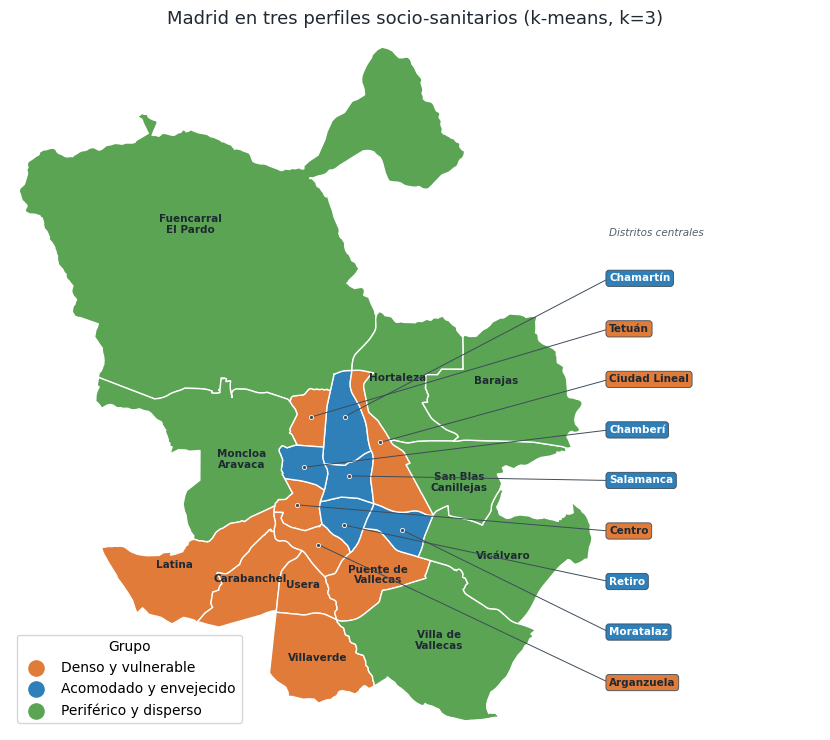

In [45]:
# Límites oficiales: servicio de mapas del Ayuntamiento de Madrid, capa DISTRITOS (ETRS89 / UTM 30N)
URL = ('https://sigma.madrid.es/hosted/rest/services/CARTOGRAFIA/LIMITES_ADMINISTRATIVOS/MapServer/3/query?'
       + urllib.parse.urlencode({'where': '1=1', 'outFields': 'COD_DIS_TX,NOMBRE', 'outSR': 25830, 'f': 'geojson'}))
if not (carpeta / 'distritos_madrid.geojson').exists():
    urllib.request.urlretrieve(URL, carpeta / 'distritos_madrid.geojson')
g = json.load(open(carpeta / 'distritos_madrid.geojson'))
geo = {int(f['properties']['COD_DIS_TX']): (shape(f['geometry']), f['properties']['NOMBRE']) for f in g['features']}
assert sorted(geo) == sorted(df.distrito_id), 'Los códigos del mapa no coinciden con la tabla'

t = df.copy(); t['cod'] = t.distrito_id
t['nombre'] = t.cod.map(lambda c: geo[c][1])
short = {'Fuencarral - El Pardo': 'Fuencarral\nEl Pardo', 'Moncloa - Aravaca': 'Moncloa\nAravaca',
         'San Blas - Canillejas': 'San Blas\nCanillejas', 'Puente de Vallecas': 'Puente de\nVallecas',
         'Villa de Vallecas': 'Villa de\nVallecas', 'Ciudad Lineal': 'Ciudad\nLineal'}
t['lab'] = t.nombre.map(lambda n: short.get(n, n))
INK = '#1f2933'
CORE = [1, 2, 3, 4, 5, 6, 7, 14, 15]

def lum(c):
    r, g_, b = to_rgb(c); return .299 * r + .587 * g_ + .114 * b

def patch(poly, fc, lw=1.0, ec='white'):
    verts, codes = [], []
    for ring in [poly.exterior] + list(poly.interiors):
        xy = np.array(ring.coords)
        verts += list(xy); codes += [MPath.MOVETO] + [MPath.LINETO] * (len(xy) - 2) + [MPath.CLOSEPOLY]
    return PathPatch(MPath(verts, codes), fc=fc, ec=ec, lw=lw)

def draw(ax, colors, labels=None, fs=7.5, txtcol=None, ifs=7.5):
    for _, r in t.iterrows():
        ax.add_patch(patch(geo[r.cod][0], colors[r.cod]))
    b = [geo[c][0].bounds for c in geo]
    x0 = min(x[0] for x in b); y0 = min(x[1] for x in b)
    x1 = max(x[2] for x in b); y1 = max(x[3] for x in b); w = x1 - x0
    ax.set_xlim(x0 - 500, x1 + 0.40 * w); ax.set_ylim(y0 - 500, y1 + 500)
    ax.set_aspect('equal'); ax.axis('off')
    if labels is None:
        return
    for c in [c for c in geo if c not in CORE]:
        p = geo[c][0].representative_point()
        col = colors[c]
        ax.text(p.x, p.y, labels[c], ha='center', va='center', fontsize=fs,
                color=(txtcol[c] if txtcol else ('white' if lum(col) < .5 else INK)),
                fontweight='bold', linespacing=1.05)
    ys = {c: geo[c][0].representative_point() for c in CORE}
    order = sorted(CORE, key=lambda c: -ys[c].y)
    yc = np.mean([p.y for p in ys.values()]); span = (y1 - y0) * 0.075
    xs = x1 + 0.03 * w
    ax.text(xs, yc + (len(order) / 2) * span + span * .3, 'Distritos centrales',
            fontsize=ifs, color='#52606d', ha='left', va='bottom', style='italic')
    for k, c in enumerate(order):
        yy = yc + (len(order) / 2 - k - 0.5) * span
        p = ys[c]
        ax.plot([p.x, xs], [p.y, yy], color='#3e4c59', lw=.7, zorder=5, solid_capstyle='round')
        ax.plot(p.x, p.y, 'o', ms=3, color='#3e4c59', zorder=6, mec='white', mew=.6)
        col = colors[c]; tcol = ('white' if lum(col) < .5 else INK)
        ax.text(xs, yy, labels[c].replace('\n', ' '), ha='left', va='center', fontsize=ifs,
                fontweight='bold', color=tcol, zorder=7,
                bbox=dict(boxstyle='round,pad=0.3', fc=col, ec='#3e4c59', lw=.6))

COLORES_C = {0: '#e07b39', 1: '#2f7fb8', 2: '#5aa454'}
fig, ax = plt.subplots(figsize=(11, 7.5))
colores = {r.cod: COLORES_C[r.cluster] for _, r in t.iterrows()}
draw(ax, colores, labels=dict(zip(t.cod, t.lab)))
for c in range(3):
    ax.scatter([], [], color=COLORES_C[c], s=120, label=f'{nombres[c]}')
ax.legend(loc='lower left', fontsize=10, frameon=True, title='Grupo', title_fontsize=10)
ax.set_title('Madrid en tres perfiles socio-sanitarios (k-means, k=3)', fontsize=13, color=INK, pad=10)
fig.tight_layout()
guarda(fig, '03_mapa_grupos.png')
plt.show()

guardado: 1_3_clustering/graficos_cierre_9D/04_dendrograma_y_pca.png


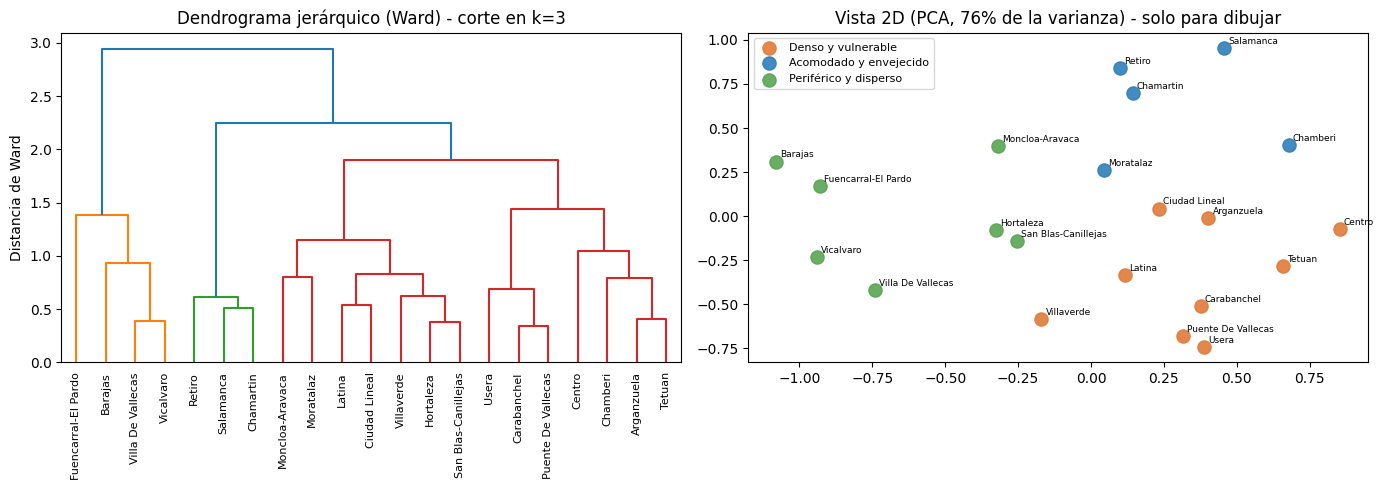

Varianza explicada PCA2D: [0.43172487 0.32393415] acumulada: 0.7556590166000411
PCA solo visualiza: clusters calculados en matriz9D principal min-max; no en los2 componentes.


In [46]:
# Dendrograma Ward y vista 2D (PCA): dos formas de ver la misma estructura
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
Z = linkage(X, method='ward')
dendrogram(Z, labels=df.distrito.str.title().tolist(), leaf_rotation=90, ax=ax1,
           color_threshold=Z[-(k_final - 1), 2], leaf_font_size=8)
ax1.set_title('Dendrograma jerárquico (Ward) - corte en k=3'); ax1.set_ylabel('Distancia de Ward')

pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(X)
for c in range(k_final):
    m = df.cluster.to_numpy() == c
    ax2.scatter(P[m, 0], P[m, 1], s=90, color=COLORES_C[c], label=nombres[c], alpha=0.9)
for i, r in df.iterrows():
    ax2.annotate(r.distrito.title(), (P[i, 0], P[i, 1]), fontsize=6.5,
                 xytext=(3, 3), textcoords='offset points')
ax2.set_title(f'Vista 2D (PCA, {pca.explained_variance_ratio_.sum() * 100:.0f}% de la varianza) - solo para dibujar')
ax2.legend(fontsize=8)
fig.tight_layout()
guarda(fig, '04_dendrograma_y_pca.png')
plt.show()
print('Varianza explicada PCA2D:',pca.explained_variance_ratio_, 'acumulada:',pca.explained_variance_ratio_.sum())
print('PCA solo visualiza: clusters calculados en matriz9D principal min-max; no en los2 componentes.')


## 6. Robustez: qué aguanta y qué no

Antes de sacar conclusiones, varias pruebas sobre la partición k = 3:

- **Otras 19 semillas** de k-means: ¿el resultado depende del azar del arranque?
- **Sin Centro**: distrito atípico (su tasa de activaciones por habitante es aproximadamente el doble de la del segundo).
- **Sin los 4 distritos con celdas imputadas** en las variables usadas (Retiro, Ciudad Lineal, Chamartín, San Blas-Canillejas).
- **Sin `renta_media_hogar` ni `pct_mayores_65`**: las dos variables con más peso social del modelo.
- **Ward en vez de k-means**: ¿otro algoritmo ve la misma estructura?

Se mide con ARI (1 = misma partición salvo el nombre de las etiquetas, 0 = acuerdo esperado por azar).

In [47]:
res = {}
aris = []
for seed in range(1, 20):
    lab = KMeans(n_clusters=3, n_init=50, random_state=seed).fit(X).labels_
    aris.append(adjusted_rand_score(df.cluster, lab))
res['19 semillas distintas'] = f'ARI mín {min(aris):.2f} / mediano {np.median(aris):.2f}'

mA = df.distrito != 'CENTRO'
kmA = KMeans(n_clusters=3, n_init=50, random_state=42).fit(X[mA.to_numpy()])
res['Sin Centro'] = f'ARI {adjusted_rand_score(df.loc[mA, "cluster"], kmA.labels_):.2f}'

afectados = ['RETIRO', 'CIUDAD LINEAL', 'CHAMARTIN', 'SAN BLAS-CANILLEJAS']
mB = ~df.distrito.isin(afectados)
kmB = KMeans(n_clusters=3, n_init=50, random_state=42).fit(X[mB.to_numpy()])
res['Sin los 4 con imputaciones'] = f'ARI {adjusted_rand_score(df.loc[mB, "cluster"], kmB.labels_):.2f}'

vars_sin = [v for v in variables if v not in ('renta_media_hogar', 'pct_mayores_65')]
kmS = KMeans(n_clusters=3, n_init=50, random_state=42).fit(nrm[vars_sin].to_numpy())
res['Sin renta ni % >65'] = f'ARI {adjusted_rand_score(df.cluster, kmS.labels_):.2f}'

hc3 = AgglomerativeClustering(n_clusters=3, linkage='ward').fit(X)
res['Ward en vez de k-means'] = f'ARI {adjusted_rand_score(df.cluster, hc3.labels_):.2f}'

for k, v in res.items():
    print(f'{k:32s} {v}')
print('Comparación con Ward: ver ARI y tabla, sin asumir fronteras iguales.')
print('Coincidencia parcial entre estos métodos, no validación externa.')
print('Sensibilidad a variables de interpretación delicada (mismo k=3, escalado fijo):')
for quitar in ['densidad_hab_km2','tiempo_respuesta_medio_min','edad_media_paciente']:
    vv=[v for v in variables if v!=quitar]
    lab=KMeans(n_clusters=3,n_init=50,random_state=42).fit_predict(nrm[vv].to_numpy())
    print(f'Sin {quitar}: ARI={adjusted_rand_score(df.cluster,lab):.3f}')


19 semillas distintas            ARI mín 1.00 / mediano 1.00
Sin Centro                       ARI 1.00
Sin los 4 con imputaciones       ARI 0.59
Sin renta ni % >65               ARI 0.73
Ward en vez de k-means           ARI 0.33
Comparación con Ward: ver ARI y tabla, sin asumir fronteras iguales.
Coincidencia parcial entre estos métodos, no validación externa.
Sensibilidad a variables de interpretación delicada (mismo k=3, escalado fijo):
Sin densidad_hab_km2: ARI=0.608
Sin tiempo_respuesta_medio_min: ARI=1.000
Sin edad_media_paciente: ARI=1.000


**Sensibilidad 9D:** retirar densidad da ARI0,608; retirar tiempo 1,000. La excepción a la regla de correlación densidad-tiempo se mantiene porque geografía y servicio representan conceptos distintos del enunciado, pero no se afirma independencia de sus pesos. La comparación 10D/9D aparece en 7.9.

**Robustez 9D:** ARI1,000 en 19 semillas y sin Centro;0,593 sin 4 distritos imputados;0,733 sin renta ni mayores 65;0,331 con Ward. La elección de variables y la muestra importan. No se vende estabilidad universal ni validación externa; las diferencias por grupo describen esta partición.

## 7. Cómo se distribuye Madrid: el análisis socioeconómico

Los mapas y cruces siguientes responden al enunciado por distrito, sin inferencia individual.

guardado: 1_3_clustering/graficos_cierre_9D/05_mapas_variables.png


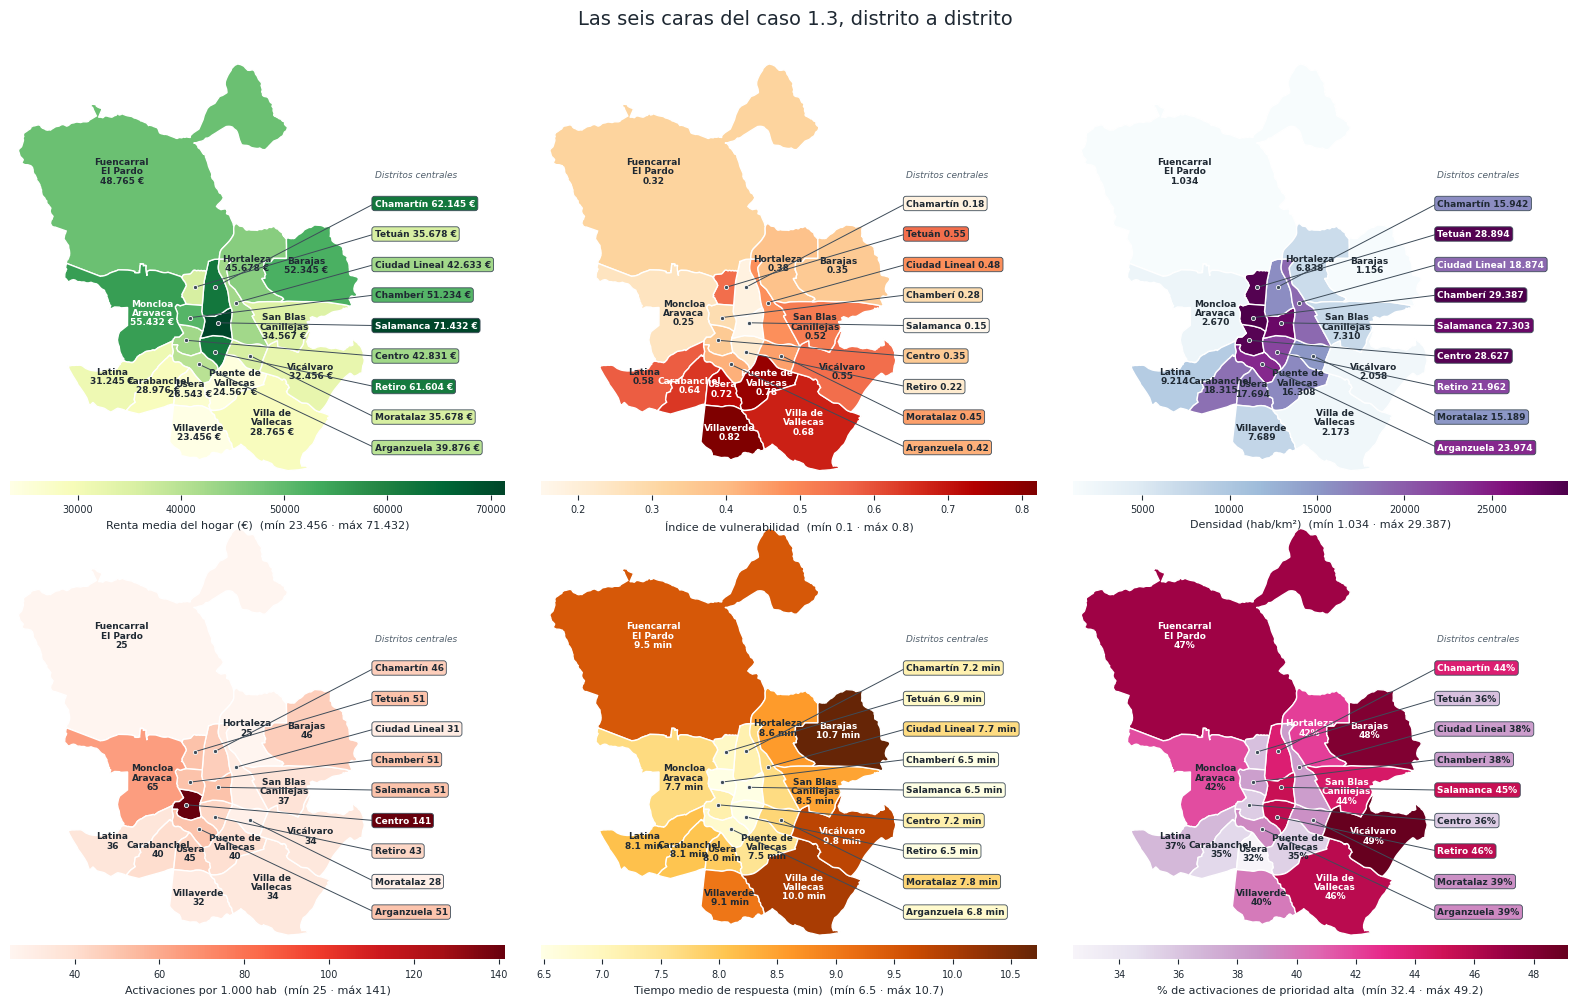

In [48]:
def choro(var, cmap, fmt):
    n = Normalize(t[var].min(), t[var].max())
    col = {r.cod: cmap(n(r[var])) for _, r in t.iterrows()}
    lab = {r.cod: r.lab + '\n' + fmt(r[var]) for _, r in t.iterrows()}
    tc = {c: ('white' if lum(col[c]) < .5 else INK) for c in col}
    return n, col, lab, tc

def cbar(fig, ax, n, cmap, label):
    sm = cm.ScalarMappable(norm=n, cmap=cmap)
    cb = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=.035, pad=.01, aspect=35)
    fm = (lambda x: f'{x:,.0f}'.replace(',', '.')) if n.vmax > 100 else (lambda x: f'{x:.1f}')
    cb.set_label(label + f'  (mín {fm(n.vmin)} · máx {fm(n.vmax)})', fontsize=8, color=INK)
    cb.ax.tick_params(labelsize=7, colors=INK); cb.outline.set_visible(False)

paneles = [
    ('renta_media_hogar', plt.get_cmap('YlGn'), lambda v: f'{v:,.0f} €'.replace(',', '.'), 'Renta media del hogar (€)'),
    ('indice_vulnerabilidad', plt.get_cmap('OrRd'), lambda v: f'{v:.2f}', 'Índice de vulnerabilidad'),
    ('densidad_hab_km2', plt.get_cmap('BuPu'), lambda v: f'{v:,.0f}'.replace(',', '.'), 'Densidad (hab/km²)'),
    ('activaciones_por_1000hab', plt.get_cmap('Reds'), lambda v: f'{v:.0f}', 'Activaciones por 1.000 hab'),
    ('tiempo_respuesta_medio_min', plt.get_cmap('YlOrBr'), lambda v: f'{v:.1f} min', 'Tiempo medio de respuesta (min)'),
    ('pct_prioridad_alta', plt.get_cmap('PuRd'), lambda v: f'{v:.0f}%', '% de activaciones de prioridad alta'),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (var, cmap, fmt, label) in zip(axes.flat, paneles):
    n, col, lab, tc = choro(var, cmap, fmt)
    draw(ax, col, labels=lab, txtcol=tc, fs=6.5, ifs=6.5)
    cbar(fig, ax, n, cmap, label)
fig.suptitle('Las seis caras del caso 1.3, distrito a distrito', fontsize=14, color=INK, y=1.00)
fig.tight_layout()
guarda(fig, '05_mapas_variables.png')
plt.show()

Los mapas ya cuentan la historia: la renta cae del noroeste al sureste, la vulnerabilidad hace justo el camino contrario, y la demanda por habitante se concentra en el centro. Los tiempos de respuesta crecen hacia el anillo exterior.

### 7.1 Lo que más y lo que menos se asocia al tiempo de respuesta

guardado: 1_3_clustering/graficos_cierre_9D/06_densidad_vs_tiempo.png


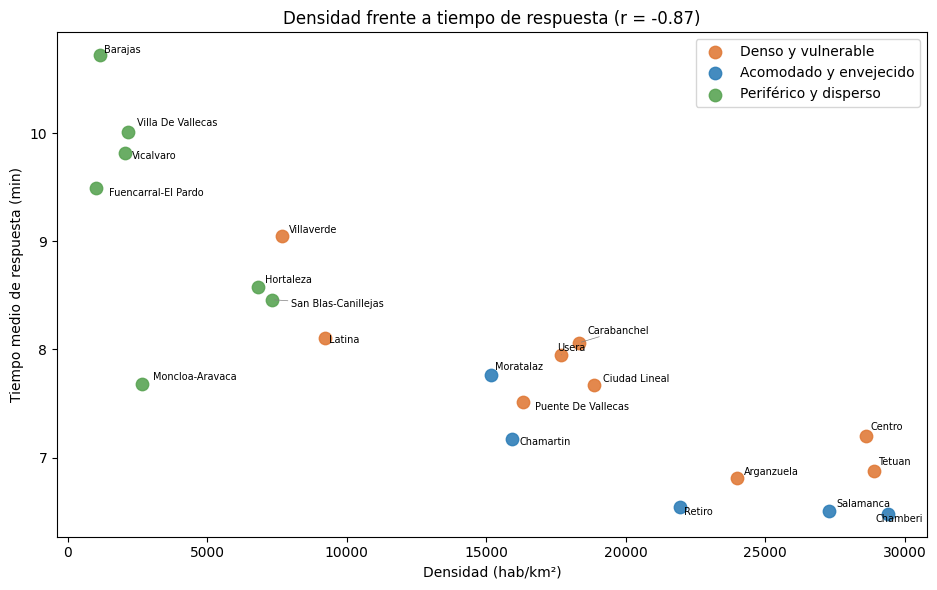

Correlación de cada variable con el tiempo medio de respuesta:
densidad_hab_km2           -0.87
pct_mayores_65             -0.71
edad_media                 -0.62
n_activaciones             -0.46
renta_media_hogar          -0.35
activaciones_por_1000hab   -0.34
poblacion                  -0.21
num_centros_salud          -0.17
num_hospitales_cat         -0.05
camas_hospital             -0.01
unidades_samur             -0.01
pct_extranjeros             0.03
num_bases_samur             0.21
tasa_paro                   0.34
indice_vulnerabilidad       0.36
edad_media_paciente         0.44
superficie_km2              0.49
pct_prioridad_alta          0.49
parques_m2_habitante        0.59


In [49]:
fig, ax = plt.subplots(figsize=(9.5, 6))
for c in range(3):
    d = df[df.cluster == c]
    ax.scatter(d.densidad_hab_km2, d.tiempo_respuesta_medio_min, s=80, color=COLORES_C[c],
               label=nombres[c], alpha=0.9)
texts = []
for _, r in df.iterrows():
    texts.append(ax.text(r.densidad_hab_km2, r.tiempo_respuesta_medio_min,r.distrito.title(),fontsize=7))
from adjustText import adjust_text
np.random.seed(42)
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='grey', lw=.5))
r_val = df[['densidad_hab_km2', 'tiempo_respuesta_medio_min']].corr().iloc[0, 1]
ax.set_xlabel('Densidad (hab/km²)'); ax.set_ylabel('Tiempo medio de respuesta (min)')
ax.set_title(f'Densidad frente a tiempo de respuesta (r = {r_val:.2f})')
ax.legend(); fig.tight_layout()
guarda(fig, '06_densidad_vs_tiempo.png')
plt.show()

corr_t = df[numericas].corr().tiempo_respuesta_medio_min.drop('tiempo_respuesta_medio_min').sort_values()
print('Correlación de cada variable con el tiempo medio de respuesta:')
print(corr_t.round(2).to_string())

### 7.1 b Respuesta: mediana, cola lenta y datos ausentes

La media puede ocultar una cola de registros lentos. Se añade mediana y percentil 90 de `tiempo_de_respuesta`, con interpolación lineal de pandas, por distrito del aviso. P90 es el valor por debajo del que queda aproximadamente 90% de los registros con tiempo válido; no garantía de servicio ni umbral clínico. Se muestran `n_total`, `n_valido`, faltantes y su porcentaje. Los nulos no se reemplazan por 0 ni se eliminan de la demanda. Se conservan todos los tiempos válidos según la limpieza aprobada, incluidos extremos: se muestran mínimo/máximo/P99 para auditar su efecto, sin recorte arbitrario. Si la falta de tiempo no es aleatoria, los cuantiles de válidos no representan todo el servicio.


,n_total,n_valido,mediana,p90,p99,media,minimo,maximo,faltantes,pct_faltante
distrito,,,,,,,,,,
BARAJAS,2210,1926,10.00,16.80,26.02,10.72,0.0,42.8,284,12.85
VICALVARO,2481,2249,9.00,15.20,26.80,9.82,0.0,96.7,232,9.35
FUENCARRAL-EL PARDO,6099,5465,8.90,14.70,24.81,9.49,0.0,74.5,634,10.40
VILLA DE VALLECAS,3805,3390,9.50,14.40,24.01,10.01,0.0,55.8,415,10.91
VILLAVERDE,4943,4423,8.60,14.20,22.00,9.05,0.0,53.4,520,10.52
SAN BLAS-CANILLEJAS,6080,5533,7.70,13.48,23.20,8.46,0.0,86.9,547,9.00
HORTALEZA,4832,4385,8.20,13.40,22.45,8.58,0.0,57.6,447,9.25
LATINA,8314,7478,7.45,13.40,20.10,8.11,0.0,83.2,836,10.06
MONCLOA-ARAVACA,7995,7238,7.00,13.00,22.56,7.68,0.0,66.0,757,9.47


guardado: 1_3_clustering/graficos_cierre_9D/16_mediana_p90_respuesta.png


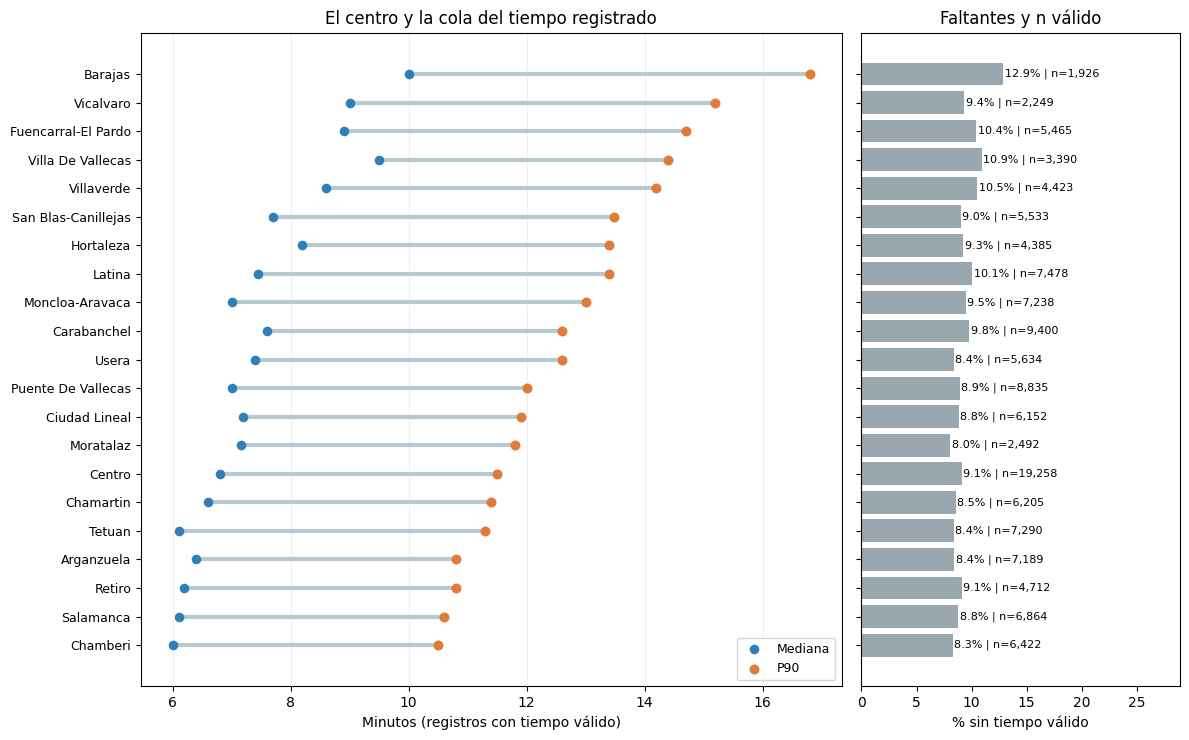

Total válido: 132540 sin tiempo: 13426


In [50]:
tiempo=pd.to_numeric(act['tiempo_de_respuesta'],errors='coerce')
assert not tiempo.dropna().lt(0).any(), 'Duración negativa sin tratar'
tiempos=act.assign(_tiempo=tiempo).groupby('distrito').agg(n_total=('activacion_id','size'),n_valido=('_tiempo','count'),mediana=('_tiempo','median'),p90=('_tiempo',lambda s:s.quantile(.9,interpolation='linear')),p99=('_tiempo',lambda s:s.quantile(.99,interpolation='linear')),media=('_tiempo','mean'),minimo=('_tiempo','min'),maximo=('_tiempo','max'))
tiempos['faltantes']=tiempos.n_total-tiempos.n_valido;tiempos['pct_faltante']=tiempos.faltantes/tiempos.n_total*100
assert tiempos.n_total.sum()==len(act)
assert np.allclose(tiempos['media'].reindex(df.distrito),df.tiempo_respuesta_medio_min,atol=.0051)
display(tiempos.sort_values('p90',ascending=False).round(2))
q=tiempos.sort_values('p90');y=np.arange(len(q))
fig,(ax,axn)=plt.subplots(1,2,figsize=(12,7.5),gridspec_kw={'width_ratios':[2.2,1]},sharey=True)
ax.hlines(y,q.mediana,q.p90,color='#b8c9d0',lw=3);ax.scatter(q.mediana,y,s=35,color='#2f7fb8',label='Mediana',zorder=3);ax.scatter(q.p90,y,s=38,color='#e07b39',label='P90',zorder=3)
ax.set_yticks(y);ax.set_yticklabels(q.index.str.title(),fontsize=9);ax.set_xlabel('Minutos (registros con tiempo válido)');ax.set_title('El centro y la cola del tiempo registrado');ax.legend(loc='lower right',fontsize=9);ax.grid(axis='x',alpha=.2)
axn.barh(y,q.pct_faltante,color='#9aa7ae');axn.set_xlabel('% sin tiempo válido');axn.set_title('Faltantes y n válido');axn.set_xlim(0,max(q.pct_faltante)*2.25)
for i,(_,v) in enumerate(q.iterrows()):axn.text(v.pct_faltante+.15,i,f'{v.pct_faltante:.1f}% | n={int(v.n_valido):,}',fontsize=8,va='center')
fig.tight_layout();guarda(fig,'16_mediana_p90_respuesta.png');plt.show()
print('Total válido:',int(tiempos.n_valido.sum()),'sin tiempo:',int(tiempos.faltantes.sum()))


**Lectura de tiempos:** Chamberí tiene mediana 6,0 y P90=10,5 min; Barajas 10,0 y 16,8 min. La diferencia se observa tanto en el centro como en la cola de la distribución registrada, no solo en medias. Entre distritos, faltan 8,0%-12,9% de tiempos; en Barajas son 284 de 2210(12,85%) y en Chamberí 579 de 7001(8,27%). En total hay 136.635 tiempos válidos y 9.331 faltantes entre 145.966 activaciones distritales. El mayor P90 no se puede atribuir causalmente a renta, bases o geografía ni comparar como garantía asistencial. La falta desigual de tiempos limita la representatividad. Los máximos/P99 se muestran arriba; no se ocultaron extremos para obtener este resultado.

A más densidad, respuesta más rápida (r = -0,87): Chamberí es el más rápido (6,5 min) y Barajas el más lento (10,7). El patrón es compatible con diferencias de geografía; estas correlaciones no separan sus efectos de los sociales. Como densidad y tiempo están tan ligados, tener las dos en el clustering refuerza el eje "compacto frente a disperso" que separa al grupo periférico.

### 7.2 La demanda por habitante no es cosa de renta

guardado: 1_3_clustering/graficos_cierre_9D/07_renta_vs_activaciones.png


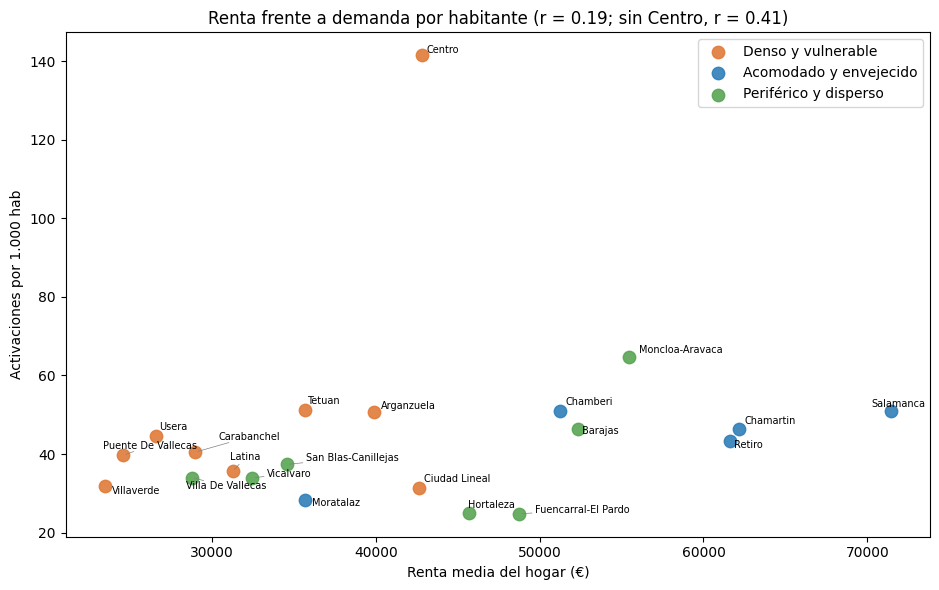

Centro: 141 activaciones/1.000 hab, frente a una media de 45


In [51]:
fig, ax = plt.subplots(figsize=(9.5, 6))
for c in range(3):
    d = df[df.cluster == c]
    ax.scatter(d.renta_media_hogar, d.activaciones_por_1000hab, s=80, color=COLORES_C[c],
               label=nombres[c], alpha=0.9)
texts = []
for _, r in df.iterrows():
    texts.append(ax.text(r.renta_media_hogar, r.activaciones_por_1000hab,r.distrito.title(),fontsize=7))
from adjustText import adjust_text
np.random.seed(42)
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='grey', lw=.5))
r_todos = df[['renta_media_hogar', 'activaciones_por_1000hab']].corr().iloc[0, 1]
sc = df[df.distrito != 'CENTRO']
r_sin = sc[['renta_media_hogar', 'activaciones_por_1000hab']].corr().iloc[0, 1]
ax.set_xlabel('Renta media del hogar (€)'); ax.set_ylabel('Activaciones por 1.000 hab')
ax.set_title(f'Renta frente a demanda por habitante (r = {r_todos:.2f}; sin Centro, r = {r_sin:.2f})')
ax.legend(); fig.tight_layout()
guarda(fig, '07_renta_vs_activaciones.png')
plt.show()
print(f'Centro: {df.loc[df.distrito=="CENTRO","activaciones_por_1000hab"].iloc[0]:.0f} activaciones/1.000 hab, '
      f'frente a una media de {df.activaciones_por_1000hab.mean():.0f}')

La asociación descriptiva demanda-renta es débil con 21 distritos (r=0,19) y cambia al retirar Centro (0,41). No demuestra ausencia de relación ni una ley sobre renta y emergencias. Centro es un mundo aparte (141 activaciones por 1.000 hab, el triple de la media): la hipótesis es que recoge demanda de visitantes y ocio nocturno, no solo de vecinos, pero estos datos no permiten confirmarlo.

### 7.3 Los distritos vulnerables sí tienen una tipología de emergencia distinta

Esta es la pregunta central del enunciado. Se cruza cada activación con la categoría corregida del catálogo de tipos.

guardado: 1_3_clustering/graficos_cierre_9D/08_tipologia_por_grupo.png


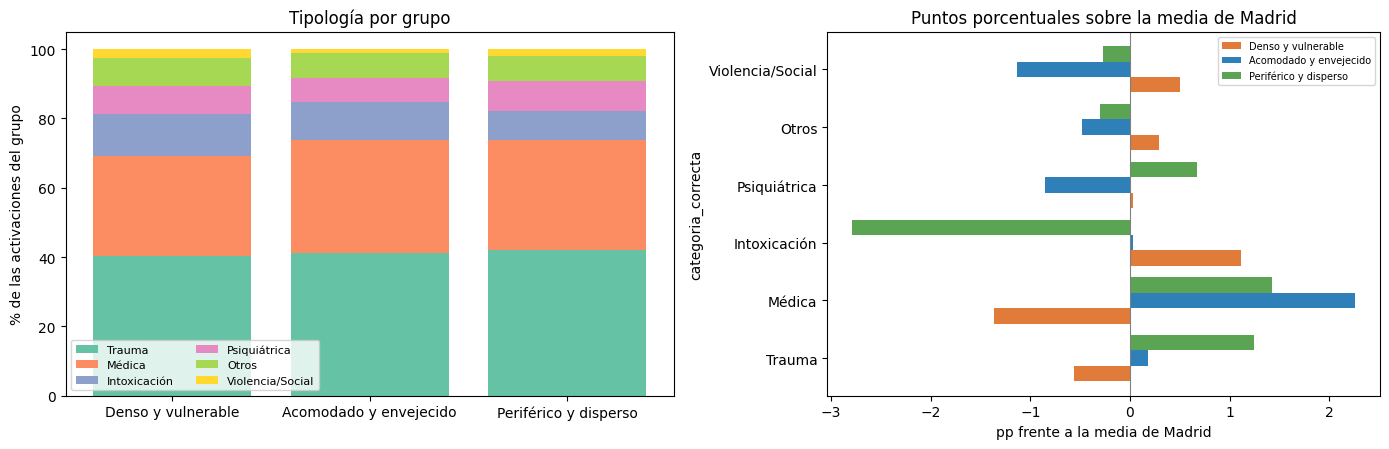

Mix por grupo (%), media de Madrid y diferencia en pp:
categoria_correcta      Trauma  Médica  Intoxicación  Psiquiátrica  Otros  Violencia/Social
Denso y vulnerable        40.3    29.0          12.1           8.0    7.9               2.7
Acomodado y envejecido    41.1    32.6          11.1           7.1    7.1               1.0
Periférico y disperso     42.1    31.8           8.2           8.7    7.3               1.9
MEDIA MADRID              40.9    30.3          11.0           8.0    7.6               2.2

Denso y vulnerable: Médica -1.4 pp; Intoxicación +1.1 pp; Trauma -0.6 pp
Acomodado y envejecido: Médica +2.3 pp; Violencia/Social -1.1 pp; Psiquiátrica -0.9 pp
Periférico y disperso: Intoxicación -2.8 pp; Médica +1.4 pp; Trauma +1.2 pp

Violencia/Social: 2.7% en el grupo denso y vulnerable frente a 1.0% en el acomodado.


In [52]:
mix = pd.crosstab(act.cluster if 'cluster' in act else act.distrito.map(dict(zip(df.distrito, df.cluster))),
                  act.categoria_correcta, normalize='index') * 100
mix.index = [nombres[i] for i in mix.index]
orden = ['Trauma', 'Médica', 'Intoxicación', 'Psiquiátrica', 'Otros', 'Violencia/Social']
mix = mix[orden]
glob = (act.categoria_correcta.value_counts(normalize=True) * 100)[orden]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1.1, 1]})
bottom = np.zeros(3)
colcat = plt.get_cmap('Set2')
for i, categoriav in enumerate(orden):
    ax1.bar(mix.index, mix[categoriav], bottom=bottom, label=categoriav, color=colcat(i))
    bottom += mix[categoriav].to_numpy()
ax1.set_ylabel('% de las activaciones del grupo'); ax1.set_title('Tipología por grupo')
ax1.legend(fontsize=8, ncol=2)

dif_pp = (mix - glob).T
dif_pp.plot.barh(ax=ax2, color=[COLORES_C[0], COLORES_C[1], COLORES_C[2]], width=0.8)
ax2.axvline(0, color='grey', lw=0.8)
ax2.legend(fontsize=7)
ax2.set_title('Puntos porcentuales sobre la media de Madrid')
ax2.set_xlabel('pp frente a la media de Madrid')
fig.tight_layout()
guarda(fig, '08_tipologia_por_grupo.png')
plt.show()

print('Mix por grupo (%), media de Madrid y diferencia en pp:')
tabla_mix = mix.copy()
tabla_mix.loc['MEDIA MADRID'] = glob
print(tabla_mix.round(1).to_string())
print()
for nombre in mix.index:
    d = (mix.loc[nombre] - glob)
    top = d.reindex(d.abs().sort_values(ascending=False).index[:3])
    print(nombre + ': ' + '; '.join(f'{k} {v:+.1f} pp' for k, v in top.items()))
print(f"\nViolencia/Social: {mix.loc['Denso y vulnerable', 'Violencia/Social']:.1f}% en el grupo denso y vulnerable "
      f"frente a {mix.loc['Acomodado y envejecido', 'Violencia/Social']:.1f}% en el acomodado.")

guardado: 1_3_clustering/graficos_cierre_9D/09_tipos_concretos_por_grupo.png


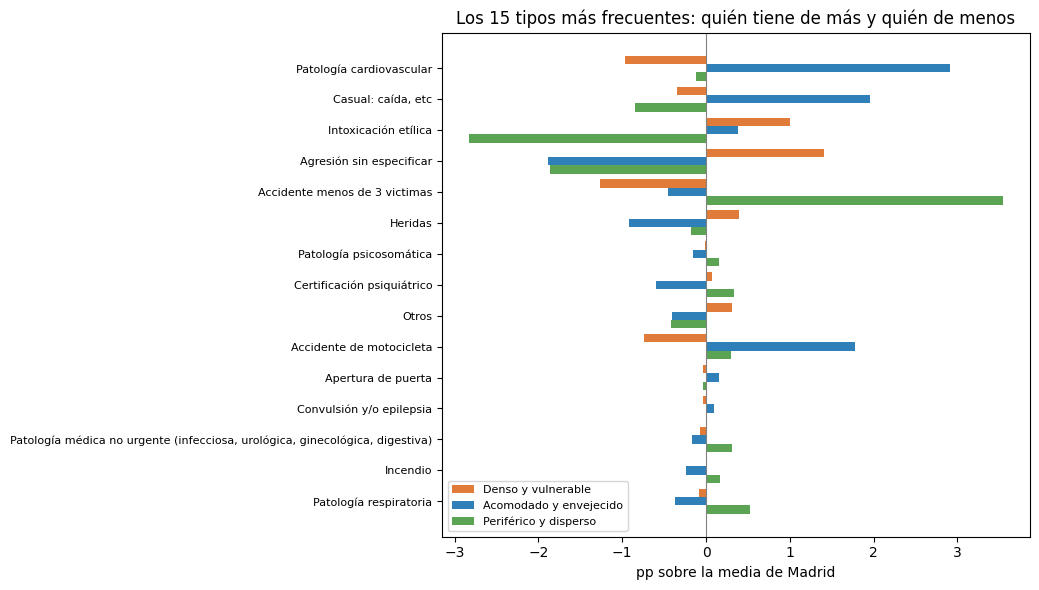

                                                                              Denso y vulnerable  Acomodado y envejecido  Periférico y disperso
tipo_emergencia                                                                                                                                
Patología cardiovascular                                                                    -1.0                     2.9                   -0.1
Casual: caída, etc                                                                          -0.3                     2.0                   -0.8
Intoxicación etílica                                                                         1.0                     0.4                   -2.8
Agresión sin especificar                                                                     1.4                    -1.9                   -1.9
Accidente menos de 3 victimas                                                               -1.3                    -0.5                

In [53]:
# Tipos concretos que más distinguen a cada grupo (pp sobre la media)
top15 = act.tipo_emergencia.value_counts().head(15).index
gr = pd.crosstab(act.distrito.map(dict(zip(df.distrito, df.cluster))), act.tipo_emergencia,
                 normalize='index')[top15] * 100
gr.index = [nombres[i] for i in gr.index]
gl = act.tipo_emergencia.value_counts(normalize=True)[top15] * 100
dift = (gr - gl).T
fig, ax = plt.subplots(figsize=(10.5, 6))
y = np.arange(len(dift)); h = 0.27
for i, nombre in enumerate(dift.columns):
    ax.barh(y + (i - 1) * h, dift[nombre], height=h, color=COLORES_C[i], label=nombre)
ax.set_yticks(y); ax.set_yticklabels(dift.index, fontsize=8); ax.invert_yaxis()
ax.axvline(0, color='grey', lw=0.8)
ax.set_xlabel('pp sobre la media de Madrid'); ax.set_title('Los 15 tipos más frecuentes: quién tiene de más y quién de menos')
ax.legend(fontsize=8)
fig.tight_layout()
guarda(fig, '09_tipos_concretos_por_grupo.png')
plt.show()
print(dift.round(1).to_string())

**Tipología 9D:** la tabla precedente muestra categorías y tipos concretos por grupo y sus diferencias respecto a Madrid. Son composiciones observadas; se contrastan directamente renta/vulnerabilidad y tasas por distrito en 7.7-7.8, sin depender solo del nombre del clúster. Más prioridad de catálogo no es gravedad clínica medida.

### 7.4 Ritmo diario e intoxicaciones

guardado: 1_3_clustering/graficos_cierre_9D/10_ritmo_diario_e_intoxicacion.png


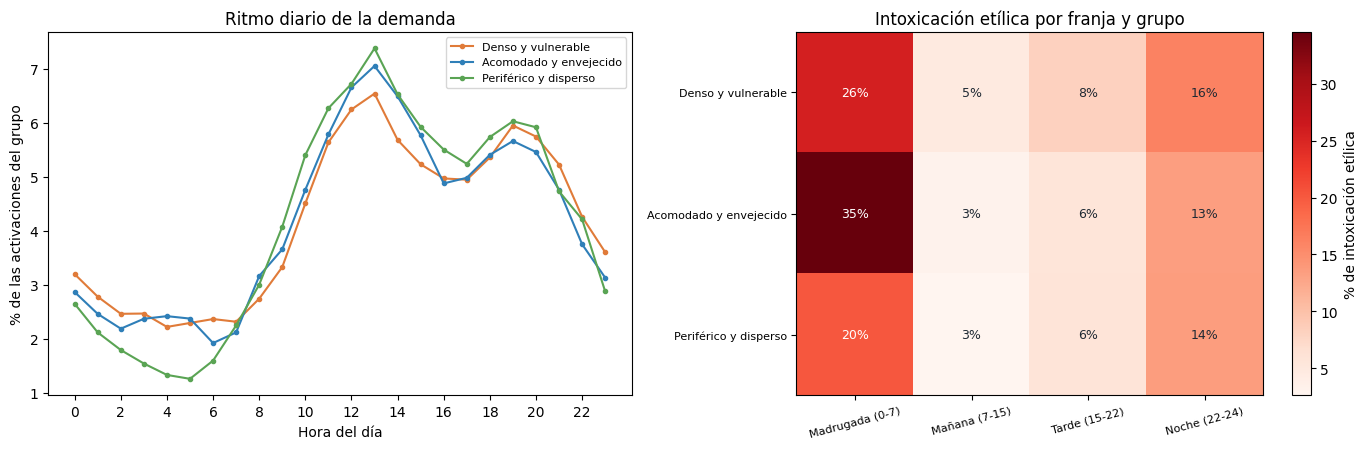

% de activaciones nocturnas (22-7 h), top 5:
distrito
CENTRO                32.2
CHAMBERI              29.1
TETUAN                25.9
USERA                 25.6
PUENTE DE VALLECAS    24.5


In [54]:
def franja(h):
    if pd.isna(h): return np.nan
    if 0 <= h < 7: return 'Madrugada (0-7)'
    if 7 <= h < 15: return 'Mañana (7-15)'
    if 15 <= h < 22: return 'Tarde (15-22)'
    return 'Noche (22-24)'
act['franja'] = act.hora.map(franja)
act['cluster_nombre'] = act.distrito.map(dict(zip(df.distrito, df.cluster_nombre)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
curvas = pd.crosstab(act.cluster_nombre, act.hora, normalize='index') * 100
for nombre in ['Denso y vulnerable', 'Acomodado y envejecido', 'Periférico y disperso']:
    ax1.plot(range(24), curvas.loc[nombre, range(24)], marker='o', ms=3,
             color=COLORES_C[{v: k for k, v in nombres.items()}[nombre]], label=nombre)
ax1.set_xlabel('Hora del día'); ax1.set_ylabel('% de las activaciones del grupo')
ax1.set_title('Ritmo diario de la demanda'); ax1.legend(fontsize=8); ax1.set_xticks(range(0, 24, 2))

intox = act[act.tipo_emergencia == 'Intoxicación etílica']
orden_f = ['Madrugada (0-7)', 'Mañana (7-15)', 'Tarde (15-22)', 'Noche (22-24)']
tot = pd.crosstab(act.cluster_nombre, act.franja)[orden_f]
ii = pd.crosstab(intox.cluster_nombre, intox.franja)[orden_f]
porc = (ii / tot * 100).loc[['Denso y vulnerable', 'Acomodado y envejecido', 'Periférico y disperso']]
im = ax2.imshow(porc, cmap='Reds', aspect='auto')
ax2.set_xticks(range(4)); ax2.set_xticklabels(orden_f, fontsize=8, rotation=15)
ax2.set_yticks(range(3)); ax2.set_yticklabels(porc.index, fontsize=8)
for i in range(3):
    for j in range(4):
        ax2.text(j, i, f'{porc.to_numpy()[i, j]:.0f}%', ha='center', va='center', fontsize=9,
                 color='white' if porc.to_numpy()[i, j] > 20 else INK)
fig.colorbar(im, ax=ax2, label='% de intoxicación etílica')
ax2.set_title('Intoxicación etílica por franja y grupo')
fig.tight_layout()
guarda(fig, '10_ritmo_diario_e_intoxicacion.png')
plt.show()

noche = act.assign(n=act.hora.map(lambda h: pd.notna(h) and (h < 7 or h >= 22))).groupby('distrito').n.mean() * 100
print('% de activaciones nocturnas (22-7 h), top 5:')
print(noche.sort_values(ascending=False).head(5).round(1).to_string())

**Ritmo diario 9D:** se compara la distribución de activaciones dentro de cada grupo y el porcentaje de etílicas dentro de cada franja. No se deduce causa de ocio ni residencia del paciente. Las cifras del gráfico se recalculan con los 9/5/7 distritos principales.

### 7.5 Estacionalidad

guardado: 1_3_clustering/graficos_cierre_9D/11_estacionalidad.png


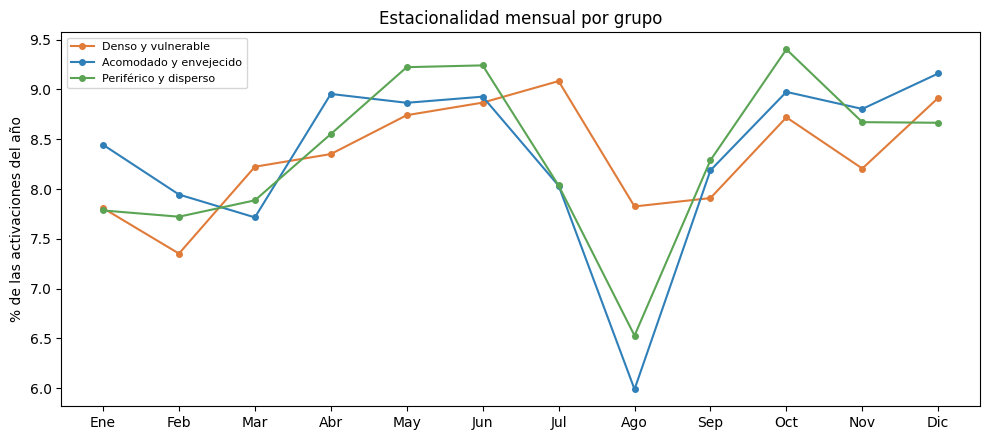

Media Madrid por mes (%):
mes
ENERO         7.9
FEBRERO       7.6
MARZO         8.0
ABRIL         8.5
MAYO          8.9
JUNIO         9.0
JULIO         8.6
AGOSTO        7.2
SEPTIEMBRE    8.1
OCTUBRE       8.9
NOVIEMBRE     8.4
DICIEMBRE     8.9


In [55]:
MESES = ['ENERO', 'FEBRERO', 'MARZO', 'ABRIL', 'MAYO', 'JUNIO', 'JULIO', 'AGOSTO',
         'SEPTIEMBRE', 'OCTUBRE', 'NOVIEMBRE', 'DICIEMBRE']
fig, ax = plt.subplots(figsize=(10, 4.5))
mensual = pd.crosstab(act.cluster_nombre, act.mes)[MESES]
mensual = mensual.div(mensual.sum(axis=1), axis=0) * 100
for nombre in ['Denso y vulnerable', 'Acomodado y envejecido', 'Periférico y disperso']:
    ax.plot(range(12), mensual.loc[nombre], marker='o', ms=4,
            color=COLORES_C[{v: k for k, v in nombres.items()}[nombre]], label=nombre)
ax.set_xticks(range(12)); ax.set_xticklabels([m[:3].title() for m in MESES])
ax.set_ylabel('% de las activaciones del año'); ax.set_title('Estacionalidad mensual por grupo')
ax.legend(fontsize=8)
fig.tight_layout()
guarda(fig, '11_estacionalidad.png')
plt.show()
print('Media Madrid por mes (%):')
print((act.mes.value_counts()[MESES] / len(act) * 100).round(1).to_string())

**Estacionalidad 9D:** porcentajes calculados dentro de cada grupo sobre su año. Los valles no miden que se vacíe la población, y no prueban movilidad ni efecto del clima. Sin día no se distingue laborable de fin de semana.

### 7.6 Prioridad y oferta frente a demanda

guardado: 1_3_clustering/graficos_cierre_9D/12_prioridad_y_oferta.png


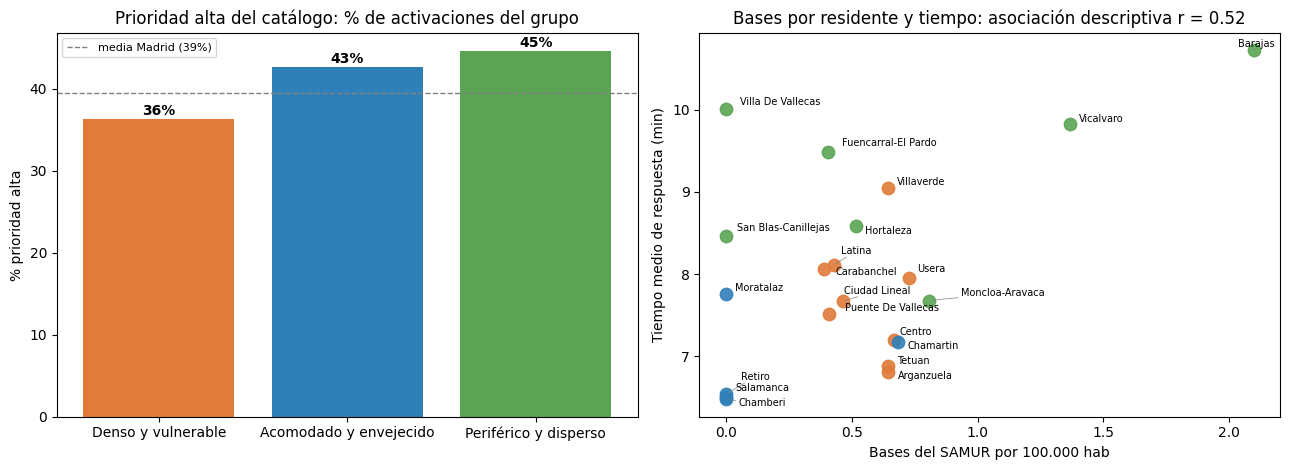

Activaciones anuales por base (media del grupo):
cluster_nombre
Acomodado y envejecido    6785.0
Denso y vulnerable        9251.0
Periférico y disperso     4723.0

Distritos sin base propia: Retiro, Salamanca, Chamberi, Moratalaz, Villa De Vallecas, San Blas-Canillejas


In [56]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
pa = act.assign(p=(act.prioridad == 'alta')).groupby('cluster_nombre').p.mean() * 100
pa = pa.loc[['Denso y vulnerable', 'Acomodado y envejecido', 'Periférico y disperso']]
ax1.bar(pa.index, pa, color=[COLORES_C[i] for i in range(3)])
for i, v in enumerate(pa):
    ax1.text(i, v + 0.5, f'{v:.0f}%', ha='center', fontweight='bold', fontsize=10)
ax1.axhline((act.prioridad == 'alta').mean() * 100, color='grey', ls='--', lw=1,
            label=f"media Madrid ({(act.prioridad == 'alta').mean() * 100:.0f}%)")
ax1.set_ylabel('% prioridad alta'); ax1.set_title('Prioridad alta del catálogo: % de activaciones del grupo')
ax1.legend(fontsize=8)

df['bases_por_100k'] = df.num_bases_samur / df.poblacion * 1e5
for c in range(3):
    d = df[df.cluster == c]
    ax2.scatter(d.bases_por_100k, d.tiempo_respuesta_medio_min, s=80, color=COLORES_C[c],
                label=nombres[c], alpha=0.9)
texts = []
for _, r in df.iterrows():
    texts.append(ax2.text(r.bases_por_100k, r.tiempo_respuesta_medio_min,r.distrito.title(),fontsize=7))
np.random.seed(42)
adjust_text(texts, ax=ax2, arrowprops=dict(arrowstyle='-', color='grey', lw=.5))
r_oferta = df[['bases_por_100k', 'tiempo_respuesta_medio_min']].corr().iloc[0, 1]
ax2.set_xlabel('Bases del SAMUR por 100.000 hab'); ax2.set_ylabel('Tiempo medio de respuesta (min)')
ax2.set_title(f'Bases por residente y tiempo: asociación descriptiva r = {r_oferta:.2f}')
fig.tight_layout()
guarda(fig, '12_prioridad_y_oferta.png')
plt.show()

df['act_por_base'] = df.n_activaciones / df.num_bases_samur.replace(0, np.nan)
print('Activaciones anuales por base (media del grupo):')
print(df.groupby('cluster_nombre').act_por_base.mean().round(0).to_string())
print('\nDistritos sin base propia:', ', '.join(df[df.num_bases_samur == 0].distrito.str.title()))

**Prioridad y oferta 9D:** en medias distritales no ponderadas, el perfil periférico tiene 45,42% de tipos de prioridad alta, frente 36,53% denso y 42,32% acomodado. Es una mezcla típica por catálogo, no triaje clínico individual. El tiempo medio periférico es 9,25 min. Bases por residente y tiempo correlacionan r=+0,52 en 21 distritos, sin identificar causa. El promedio de cocientes activaciones/base entre distritos con base es 9251 en denso,6785 acomodado y 4723 periférico. No es carga real de cada base: las unidades se desplazan fuera de su distrito, y los distritos sin base se excluyen del cociente, no de la demanda. El gráfico de barras usa la proporción sobre todas las activaciones del grupo (ponderada por volumen), no la media distrital no ponderada de los perfiles.

### 7.7 Renta y tipos concretos de emergencia

Para comparar distritos de distinto tamaño, se calcula la tasa de cada tipo por 1.000 habitantes (`conteo del tipo / población × 1.000`), no el número bruto de activaciones. Se muestran Violencia/Social (categoría corregida del catálogo), Patología cardiovascular e Intoxicación etílica (tipos concretos). El gráfico compara estas tasas con `renta_media_hogar`; etiqueta los tres distritos con mayor tasa de cada tipo y muestra los 21 distritos. `r` es solo una correlación descriptiva. El denominador es la población residente, aunque las activaciones pueden incluir no residentes, especialmente en Centro. Hay 21 distritos: no se interpreta como prueba estadística ni causalidad.


guardado: 1_3_clustering/graficos_cierre_9D/13_renta_vs_tipos_emergencia.png
Correlaciones descriptivas renta-tasa por distrito (n=21), no inferenciales:
  Violencia/Social: r = -0.59
  Patología cardiovascular: r = 0.34
  Intoxicación etílica: r = 0.13


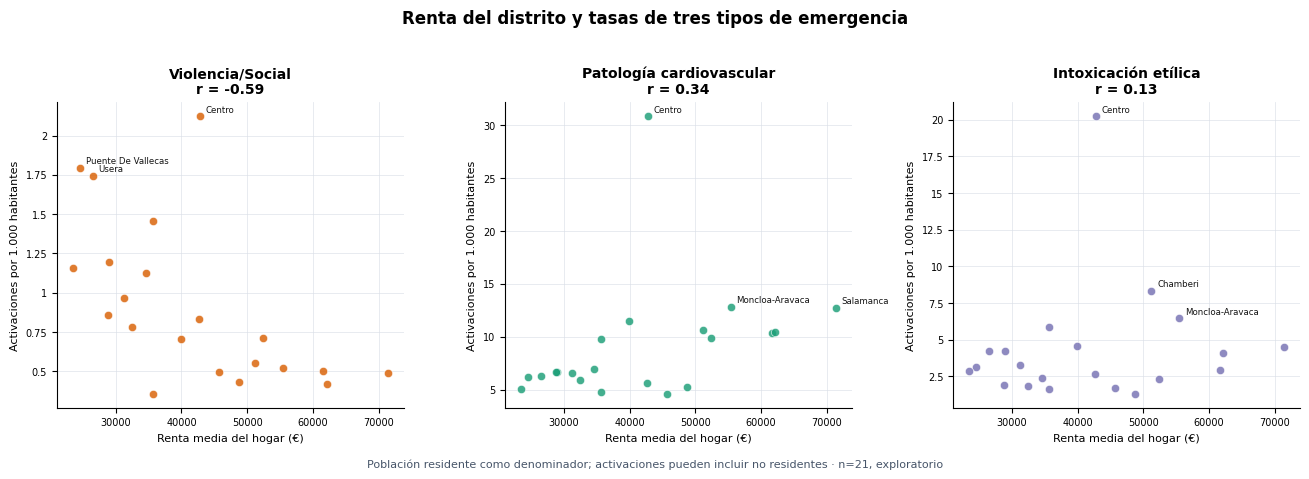

In [57]:
# Tasas distritales comparables: normalizar por población evita confundir volumen con tasa.
comparaciones = {
    'Violencia/Social': act.categoria_correcta.eq('Violencia/Social'),
    'Patología cardiovascular': act.tipo_emergencia.eq('Patología cardiovascular'),
    'Intoxicación etílica': act.tipo_emergencia.eq('Intoxicación etílica'),
}
base_renta = df.set_index('distrito')[['renta_media_hogar', 'poblacion']].copy()
conteos = pd.DataFrame({nombre: act.loc[mascara].groupby('distrito').size()
                        for nombre, mascara in comparaciones.items()})
conteos = conteos.reindex(base_renta.index, fill_value=0)
tasas = conteos.div(base_renta['poblacion'], axis=0) * 1000

fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.4), sharex=True)
colores = ['#d95f02', '#1b9e77', '#7570b3']
correlaciones = []
for ax, (nombre, valores), color in zip(axes, tasas.items(), colores):
    x = base_renta['renta_media_hogar']
    r = pd.concat([x, valores.rename('tasa')], axis=1).corr().iloc[0, 1]
    correlaciones.append((nombre, r))
    ax.scatter(x, valores, s=35, color=color, alpha=.82, edgecolor='white', linewidth=.45, zorder=3)
    top = valores.nlargest(3).index
    for distrito in top:
        ax.annotate(distrito.title(), (x.loc[distrito], valores.loc[distrito]), fontsize=6.2,
                    alpha=.92, xytext=(4, 3), textcoords='offset points')
    ax.set_title(f'{nombre}\nr = {r:.2f}', fontsize=10, fontweight='bold')
    ax.set_ylabel('Activaciones por 1.000 habitantes', fontsize=8)
    ax.grid(axis='both', color='#d9dee7', linewidth=.6, alpha=.7, zorder=0)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(labelsize=7)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
    ax.set_xlabel('Renta media del hogar (€)', fontsize=8)
fig.suptitle('Renta del distrito y tasas de tres tipos de emergencia', fontsize=12, fontweight='bold', y=1.02)
fig.text(.5, -.02, 'Población residente como denominador; activaciones pueden incluir no residentes · n=21, exploratorio',
         ha='center', fontsize=8, color='#475569')
fig.tight_layout()
guarda(fig, '13_renta_vs_tipos_emergencia.png')
print('Correlaciones descriptivas renta-tasa por distrito (n=21), no inferenciales:')
for nombre, r in correlaciones:
    print(f'  {nombre}: r = {r:.2f}')
plt.show()


### 7.8 Vulnerabilidad y tipos: contraste directo por distrito

Los grupos se construyen con variables sociales y de servicio; diferencias entre grupos describen su composición, no validan de forma independiente el modelo. Para responder al enunciado sin usar solo el nombre de un clúster, se cruza directamente `indice_vulnerabilidad` con tasas por 1.000 residentes de cada categoría de emergencia. Se añade renta y densidad en la misma matriz para ver el patrón completo, no solo el resultado más llamativo. Son correlaciones descriptivas Pearson de 21 distritos: no ajustes por movilidad, edad ni exposición; renta y vulnerabilidad están muy correlacionadas, así que no se interpretan como efectos independientes. No hay inferencia a barrios ni pacientes.


guardado: 1_3_clustering/graficos_cierre_9D/17_contexto_categorias_directo.png


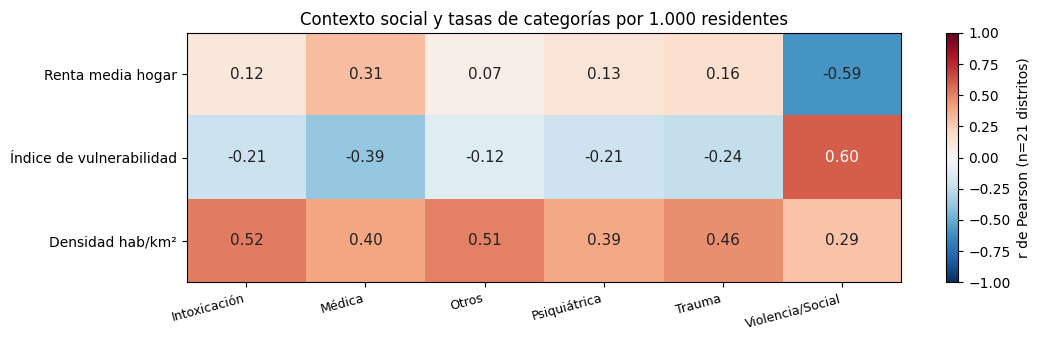

,Intoxicación,Médica,Otros,Psiquiátrica,Trauma,Violencia/Social
renta_media_hogar,0.116,0.311,0.066,0.127,0.163,-0.592
indice_vulnerabilidad,-0.212,-0.389,-0.122,-0.208,-0.238,0.602
densidad_hab_km2,0.521,0.398,0.507,0.385,0.465,0.286


categoria_correcta,Intoxicación,Médica,Otros,Psiquiátrica,Trauma,Violencia/Social
distrito,,,,,,
CENTRO,23.45,47.13,8.46,10.67,49.65,2.12
ARGANZUELA,5.09,17.10,3.76,4.22,19.73,0.70
RETIRO,3.40,15.10,3.22,3.31,17.70,0.50
SALAMANCA,4.96,17.43,3.64,3.36,21.06,0.49
CHAMARTIN,4.57,15.36,3.06,3.42,19.49,0.42
TETUAN,6.64,14.88,3.82,4.31,20.18,1.46
CHAMBERI,9.03,15.62,3.61,3.55,18.55,0.55
FUENCARRAL-EL PARDO,1.46,7.81,1.92,2.07,11.10,0.43
MONCLOA-ARAVACA,7.69,21.56,4.59,5.40,24.92,0.52


Renta-vulnerabilidad: -0.9556631675877348


In [58]:
cat_distrito=pd.crosstab(act.distrito,act.categoria_correcta).reindex(df.distrito,fill_value=0)
cat_distrito.index.name='distrito'
social=df.set_index('distrito')[['renta_media_hogar','indice_vulnerabilidad','densidad_hab_km2','poblacion']]
tasas_categoria=cat_distrito.div(social.poblacion,axis=0)*1000
correlacion_social=pd.DataFrame({c:{v:social[v].corr(tasas_categoria[c]) for v in ['renta_media_hogar','indice_vulnerabilidad','densidad_hab_km2']} for c in tasas_categoria})
fig,ax=plt.subplots(figsize=(11,3.5));im=ax.imshow(correlacion_social,cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
ax.set_yticks(range(3));ax.set_yticklabels(['Renta media hogar','Índice de vulnerabilidad','Densidad hab/km²'])
ax.set_xticks(range(len(correlacion_social.columns)));ax.set_xticklabels(correlacion_social.columns,rotation=15,ha='right',fontsize=9)
for i in range(3):
    for k in range(len(correlacion_social.columns)):
        v=correlacion_social.iloc[i,k];ax.text(k,i,f'{v:.2f}',ha='center',va='center',color='white' if abs(v)>.6 else '#222',fontsize=11)
fig.colorbar(im,ax=ax,label='r de Pearson (n=21 distritos)');ax.set_title('Contexto social y tasas de categorías por 1.000 residentes')
fig.tight_layout();guarda(fig,'17_contexto_categorias_directo.png');plt.show()
display(correlacion_social.round(3));display(tasas_categoria.round(2))
print('Renta-vulnerabilidad:',social.renta_media_hogar.corr(social.indice_vulnerabilidad))


## 7.9 Con y sin edad registrada: comparación controlada

Se conserva el modelo 10D como baseline y se compara con 9D, retirando solo `edad_media_paciente`. No se eliminan registros ni `pct_mayores_65`. Se mantienen min-max,distancia,semilla 42,n_init 50,k candidatos 2..8 y misma rejilla DBSCAN. Se alinean etiquetas por máximo acuerdo solo para comparar nombres; no se fuerza ninguna asignación. Las siluetas internas describen cada representación y no son una prueba externa de superioridad. Se elige 9D como principal por prudencia interpretativa y se conserva 10D como baseline, con cambios, perfiles y contrapartidas de robustez explícitos.


Selección k comparable (cada silueta usa su espacio):


,modelo,k,inercia,silueta_kmeans,silueta_ward
0,Con edad (10D),2,10.7143,0.2370,0.2990
1,Con edad (10D),3,7.4303,0.2683,0.2619
2,Con edad (10D),4,6.1857,0.2138,0.2277
3,Con edad (10D),5,5.2271,0.2208,0.2267
4,Con edad (10D),6,4.2805,0.2120,0.1874
5,Con edad (10D),7,3.5640,0.2159,0.1867
6,Con edad (10D),8,3.0184,0.2068,0.1983
7,Sin edad (9D),2,9.7969,0.2511,0.3038
8,Sin edad (9D),3,6.6964,0.2747,0.2543
9,Sin edad (9D),4,5.5928,0.2349,0.2059


ARI entre alternativas: 0.7292418772563177


,distrito,renta_media_hogar,pct_mayores_65,edad_media_paciente,perfil10D,perfil9D,cambia
0,CENTRO,42831.0,22.1,50.07,Denso y vulnerable,Denso y vulnerable,False
1,ARGANZUELA,39876.0,18.5,49.27,Denso y vulnerable,Denso y vulnerable,False
2,RETIRO,61604.0,25.3,49.14,Acomodado y envejecido,Acomodado y envejecido,False
3,SALAMANCA,71432.0,26.8,49.33,Acomodado y envejecido,Acomodado y envejecido,False
4,CHAMARTIN,62145.0,25.2,49.02,Acomodado y envejecido,Acomodado y envejecido,False
5,TETUAN,35678.0,17.8,49.94,Denso y vulnerable,Denso y vulnerable,False
6,CHAMBERI,51234.0,23.5,49.49,Acomodado y envejecido,Acomodado y envejecido,False
7,FUENCARRAL-EL PARDO,48765.0,16.2,49.52,Periférico y disperso,Periférico y disperso,False
8,MONCLOA-ARAVACA,55432.0,19.8,49.07,Acomodado y envejecido,Periférico y disperso,True
9,LATINA,31245.0,20.5,49.55,Denso y vulnerable,Denso y vulnerable,False


Medias por perfil9D:


,renta_media_hogar,tasa_paro,indice_vulnerabilidad,pct_mayores_65,pct_extranjeros,densidad_hab_km2,activaciones_por_1000hab,pct_prioridad_alta,edad_media_paciente,tiempo_respuesta_medio_min
Denso y vulnerable,32867.222,12.767,0.593,18.100,20.522,18843.267,51.877,36.529,49.574,7.693
Acomodado y envejecido,56418.600,7.100,0.256,24.720,11.720,21956.680,43.930,42.324,49.130,6.892
Periférico y disperso,42572.571,10.143,0.436,15.929,14.886,3319.943,38.023,45.416,49.639,9.251


... (7 outputs left out)

,eps,min_samples,grupos,ruido,tamanos,silueta_sin_ruido
8,0.4,2,3,15,"2,2,2",0.539003
12,0.5,2,4,11,"2,3,3,2",0.396924
13,0.5,3,2,15,"3,3",0.348125
16,0.6,2,3,6,"10,3,2",0.389852
17,0.6,3,2,8,"10,3",0.442448


Silueta por distrito alternativa9D:


,distrito,silueta10D,silueta9D
0,CENTRO,0.155,0.143
1,ARGANZUELA,0.121,0.122
2,RETIRO,0.429,0.444
3,SALAMANCA,0.431,0.503
4,CHAMARTIN,0.453,0.476
5,TETUAN,0.324,0.330
6,CHAMBERI,0.128,0.210
7,FUENCARRAL-EL PARDO,0.242,0.295
8,MONCLOA-ARAVACA,0.148,-0.030
9,LATINA,0.362,0.320


guardado: 1_3_clustering/graficos_cierre_9D/19_comparacion_con_sin_edad.png


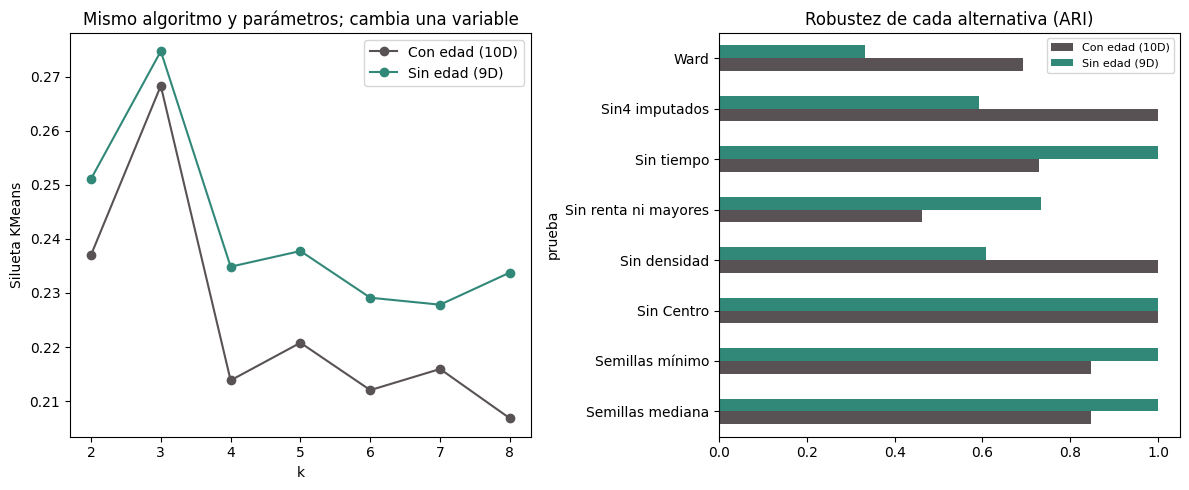

guardado: 1_3_clustering/graficos_cierre_9D/20_dbscan_sin_edad.png


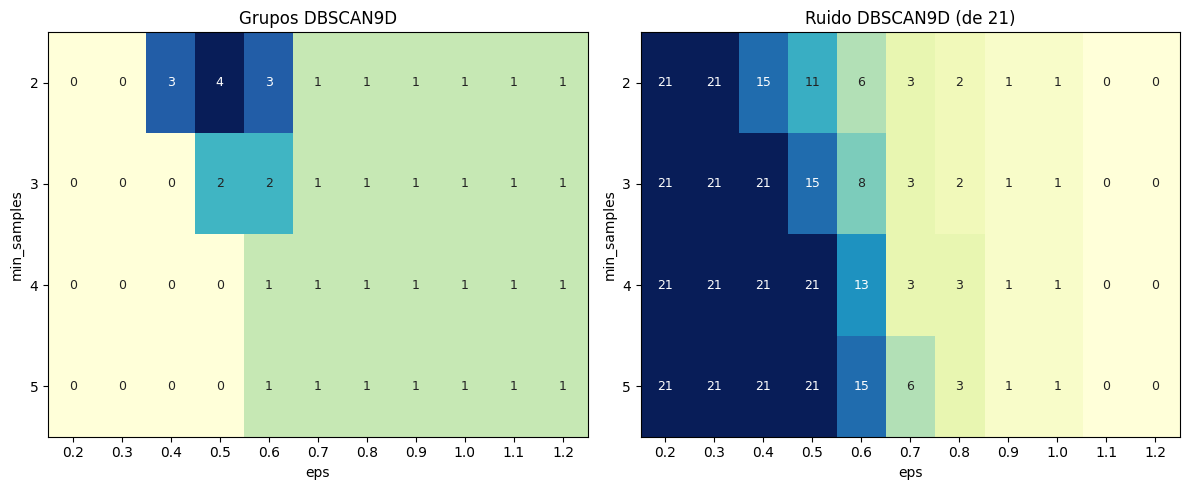

Perfil10D conservado como baseline:


,renta_media_hogar,tasa_paro,indice_vulnerabilidad,pct_mayores_65,pct_extranjeros,densidad_hab_km2,activaciones_por_1000hab,pct_prioridad_alta,edad_media_paciente,tiempo_respuesta_medio_min
Denso y vulnerable,33037.200,12.640,0.586,18.14,20.220,17689.910,50.426,37.309,49.509,7.770
Acomodado y envejecido,56254.167,7.183,0.255,23.90,11.633,18742.283,47.388,42.222,49.120,7.023
Periférico y disperso,41601.800,10.380,0.456,14.64,15.100,2651.920,32.822,46.374,49.896,9.724


DBSCAN10D: rejilla44 completa para contraste, no mezclar con tabla9D principal


,eps,min_samples,grupos,ruido,tamanos
0,0.2,2,0,21,
1,0.2,3,0,21,
2,0.2,4,0,21,
3,0.2,5,0,21,
4,0.3,2,0,21,
5,0.3,3,0,21,
6,0.3,4,0,21,
7,0.3,5,0,21,
8,0.4,2,2,17,"2,2"
9,0.4,3,0,21,


In [59]:
from itertools import permutations
variables10=['densidad_hab_km2', 'renta_media_hogar', 'pct_mayores_65', 'pct_extranjeros', 'num_centros_salud', 'parques_m2_habitante', 'activaciones_por_1000hab', 'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
X10=nrm[variables10].to_numpy()
labels10=KMeans(n_clusters=3,n_init=50,random_state=42).fit_predict(X10)
variables9=[v for v in variables10 if v!='edad_media_paciente']
X9=nrm[variables9].to_numpy()
lab9_raw=KMeans(n_clusters=3,n_init=50,random_state=42).fit_predict(X9)
mejor=max(permutations(range(3)),key=lambda perm:sum(np.array(perm)[lab9_raw]==labels10))
lab9=np.array(mejor)[lab9_raw]
comparativa_k=[]
for nombre,matriz in [('Con edad (10D)',X10),('Sin edad (9D)',X9)]:
    for k in range(2,9):
        kk=KMeans(n_clusters=k,n_init=50,random_state=42).fit(matriz)
        wh=AgglomerativeClustering(n_clusters=k,linkage='ward').fit_predict(matriz)
        comparativa_k.append(dict(modelo=nombre,k=k,inercia=kk.inertia_,silueta_kmeans=silhouette_score(matriz,kk.labels_),silueta_ward=silhouette_score(matriz,wh)))
comparativa_k=pd.DataFrame(comparativa_k)
print('Selección k comparable (cada silueta usa su espacio):');display(comparativa_k.round(4))
comparativa_distritos=df[['distrito','renta_media_hogar','pct_mayores_65','edad_media_paciente']].copy()
comparativa_distritos['perfil10D']=pd.Series(labels10,index=df.index).map(nombres)
comparativa_distritos['perfil9D']=pd.Series(lab9,index=df.index).map(nombres)
comparativa_distritos['cambia']=comparativa_distritos.perfil10D!=comparativa_distritos.perfil9D
print('ARI entre alternativas:',adjusted_rand_score(labels10,lab9));display(comparativa_distritos)
perfil9=df.groupby(lab9)[cols_desc].mean().round(3)
perfil9.index=perfil9.index.map(nombres)
print('Medias por perfil9D:');display(perfil9)
resumen9=df.assign(cluster9=lab9).groupby('cluster9').agg(distritos=('distrito','count'),activaciones=('n_activaciones','sum'))
resumen9['pct_activaciones']=resumen9.activaciones/df.n_activaciones.sum()*100
print('Tamaños y pesos9D:');display(resumen9)
comparativa_robustez=[]
for nombre,matriz,labels,vv in [('Con edad (10D)',X10,labels10,variables10),('Sin edad (9D)',X9,lab9,variables9)]:
    aa=[adjusted_rand_score(labels,KMeans(n_clusters=3,n_init=50,random_state=s).fit_predict(matriz)) for s in range(1,20)]
    comparativa_robustez.extend([dict(modelo=nombre,prueba='Semillas mínimo',ARI=min(aa)),dict(modelo=nombre,prueba='Semillas mediana',ARI=np.median(aa))])
    for prueba,mascara in [('Sin Centro',mA),('Sin4 imputados',mB)]:
        ajust=KMeans(n_clusters=3,n_init=50,random_state=42).fit_predict(matriz[mascara.to_numpy()])
        comparativa_robustez.append(dict(modelo=nombre,prueba=prueba,ARI=adjusted_rand_score(labels[mascara.to_numpy()],ajust)))
    for prueba,quitadas in [('Sin renta ni mayores',['renta_media_hogar','pct_mayores_65']),('Sin densidad',['densidad_hab_km2']),('Sin tiempo',['tiempo_respuesta_medio_min'])]:
        ajust=KMeans(n_clusters=3,n_init=50,random_state=42).fit_predict(nrm[[v for v in vv if v not in quitadas]].to_numpy())
        comparativa_robustez.append(dict(modelo=nombre,prueba=prueba,ARI=adjusted_rand_score(labels,ajust)))
    comparativa_robustez.append(dict(modelo=nombre,prueba='Ward',ARI=adjusted_rand_score(labels,AgglomerativeClustering(n_clusters=3).fit_predict(matriz))))
comparativa_robustez=pd.DataFrame(comparativa_robustez)
print('Robustez comparable:');display(comparativa_robustez.round(3))
db9=[]
for eps in np.round(np.arange(.2,1.21,.1),1):
    for ms in [2,3,4,5]:
        ll=DBSCAN(eps=float(eps),min_samples=ms).fit_predict(X9);gr=sorted(set(ll)-{-1});mask=ll!=-1
        db9.append(dict(eps=float(eps),min_samples=ms,grupos=len(gr),ruido=int((ll==-1).sum()),tamanos=','.join(str(int((ll==g).sum())) for g in gr),silueta_sin_ruido=float(silhouette_score(X9[mask],ll[mask])) if len(gr)>=2 and mask.sum()>len(gr) else np.nan))
db9=pd.DataFrame(db9);print('Rejilla DBSCAN9D completa:');display(db9)
print('Multigrupo9D:');display(db9[db9.grupos>=2])
from sklearn.metrics import silhouette_samples
sil9=silhouette_samples(X9,lab9)
print('Silueta por distrito alternativa9D:');display(pd.DataFrame({'distrito':df.distrito,'silueta10D':silhouette_samples(X10,labels10),'silueta9D':sil9}).round(3))
# Visual comparison, aligned labels only for presentation, never manual reallocation.
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(12,5))
for nombre,color in [('Con edad (10D)','#585254'),('Sin edad (9D)','#318879')]:
    dd=comparativa_k[comparativa_k.modelo==nombre];ax1.plot(dd.k,dd.silueta_kmeans,'o-',label=nombre,color=color)
ax1.set(xlabel='k',ylabel='Silueta KMeans',title='Mismo algoritmo y parámetros; cambia una variable');ax1.legend()
cc=comparativa_robustez.pivot(index='prueba',columns='modelo',values='ARI');cc.plot.barh(ax=ax2,color=['#585254','#318879']);ax2.set(title='Robustez de cada alternativa (ARI)',xlim=(0,1.05));ax2.legend(fontsize=8)
fig.tight_layout();guarda(fig,'19_comparacion_con_sin_edad.png');plt.show()
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(12,5))
for ax,col,titulo in [(ax1,'grupos','Grupos DBSCAN9D'),(ax2,'ruido','Ruido DBSCAN9D (de 21)')]:
    tabla=db9.pivot(index='min_samples',columns='eps',values=col);im=ax.imshow(tabla,aspect='auto',cmap='YlGnBu');ax.set_xticks(range(len(tabla.columns)));ax.set_xticklabels(tabla.columns);ax.set_yticks(range(len(tabla.index)));ax.set_yticklabels(tabla.index);ax.set(xlabel='eps',ylabel='min_samples',title=titulo)
    for i in range(len(tabla)):
        for j in range(len(tabla.columns)):ax.text(j,i,str(tabla.iloc[i,j]),ha='center',va='center',fontsize=9,color='white' if tabla.iloc[i,j]>tabla.to_numpy().max()*.55 else '#222')
fig.tight_layout();guarda(fig,'20_dbscan_sin_edad.png');plt.show()
comparacion_export={'k':comparativa_k.to_dict('records'),'robustez':comparativa_robustez.to_dict('records'),'distritos':comparativa_distritos.to_dict('records'),'resumen9':resumen9.reset_index().to_dict('records'),'perfil9':perfil9.reset_index().to_dict('records'),'dbscan9':db9.fillna('').to_dict('records'),'ari10vs9':adjusted_rand_score(labels10,lab9),'variables9':variables9,'silueta9':float(silhouette_score(X9,lab9))}
(carpeta/'comparacion_edad.json').write_text(json.dumps(comparacion_export,ensure_ascii=False,indent=2))

print('Perfil10D conservado como baseline:');display(df.groupby(labels10)[cols_desc].mean().rename(index=nombres).round(3))
print('DBSCAN10D: rejilla44 completa para contraste, no mezclar con tabla9D principal')
db10=[]
for eps in np.round(np.arange(.2,1.21,.1),1):
    for ms in [2,3,4,5]:
        ll=DBSCAN(eps=float(eps),min_samples=ms).fit_predict(X10);gr=sorted(set(ll)-{-1})
        db10.append(dict(eps=eps,min_samples=ms,grupos=len(gr),ruido=int((ll==-1).sum()),tamanos=','.join(str(int((ll==g).sum())) for g in gr)))
display(pd.DataFrame(db10))


**Lectura comparada, sin escoger por una sola métrica.** KMeans k 3 es el mejor k ensayado en ambas representaciones: silueta 0,2683 con edad y 0,2747 sin edad. La diferencia es pequeña, y comparar siluetas entre espacios distintos no valida superioridad. Se mantienen 19 distritos; Moncloa-Aravaca pasa del perfil acomodado al periférico, y San Blas-Canillejas del denso al periférico. ARI entre alternativas=0,729. Sin edad, los perfiles son 9/5/7 distritos y 57,0%/20,0%/23,0% del servicio, respectivamente. El perfil acomodado sigue teniendo mayor porcentaje de residentes mayores 65(24,72%, frente 18,10% y 15,93%), sin usar edad del paciente para ese nombre.

La robustez es mixta: sin edad se estabiliza el arranque(ARI1,00 en 19 semillas frente 0,848), pero hay más sensibilidad al retirar los 4 distritos imputados(0,593 frente 1), al usar Ward(0,331 frente 0,692) y al retirar densidad(0,608 frente 1). Sin tiempo el modelo 9D no cambia; sin renta/mayores su ARI es 0,733. DBSCAN9D tiene 5 configuraciones multigrupo, siempre 6..15 de 21 distritos como ruido; sigue sin una partición multigrupo completa en la rejilla ensayada. La decisión metodológica es no usar la edad registrada para decidir perfiles por su interpretación no verificada y su amplificación min-max, pero no afirmar que 9D sea mejor en toda prueba. Se conserva 10D como comparación y se separan sus cifras de 9D.


## 8. Conclusiones del modelo principal 9D

Se agrupan 21 distritos en perfiles exploratorios de contexto y servicio. El grupo denso reúne 9 distritos y 57,0% del servicio; el acomodado 5 y 20,0%; el periférico 7 y 23,0%. No se infiere riesgo individual ni cobertura operativa. El perfil acomodado se llama envejecido por 24,72% mayores 65 residentes, no por edad del paciente.

La vulnerabilidad se asocia descriptivamente con tasa Violencia/Social(r=+0,602), y renta r=-0,592; renta y vulnerabilidad son muy correlacionadas entre sí(-0,956). La densidad se asocia al tiempo(r=-0,87), no demuestra influencia causal ni tiempo de viaje a base. Hay datos temporales ausentes y 21 observaciones; no validación externa.

Se elige 9D por prudencia al retirar edad registrada de interpretación dudosa, manteniendo 10D como comparación. Las 19 semillas son estables, pero quitar imputados o cambiar a Ward mueve fronteras. La diferencia de silueta es pequeña y no basta por sí sola para elegir. No se fuerza conservar los grupos antiguos. Catálogos hospitalarios no homogéneos y unidades ambiguas quedan fuera del modelo sin imputación.

## 9. Reproducibilidad

Ejecutar desde raíz o carpeta 1_3_clustering, después de las limpiezas y cruces. Entradas CSV intactas salvo catálogo hospitalario/cruces aprobados. Semilla 42,n_init 50,distancia euclídea,escalado min-max. Figuras principales en graficos_cierre_9D; comparación 10D queda separada. El mapa usa límites oficiales. Asserts comprueban identidad distrital, escalado y datos finitos.

In [60]:
# Resumen verificable para documentación y presentación: sin añadir entradas al modelo.
resumen={'variables':variables,'distritos':df.distrito.tolist(),'labels':df.cluster.astype(int).tolist(),'silueta':float(silhouette_score(X,df.cluster)),'siluetas':siluetas.to_dict(orient='records'),'tiempos':tiempos.reset_index().to_dict(orient='records'),'dbscan':dbscan_pruebas.to_dict(orient='records'),'cluster_totales':df.groupby('cluster').n_activaciones.sum().to_dict(),'n_activaciones':len(act)}
(carpeta/'verificacion_resultados.json').write_text(json.dumps(resumen,ensure_ascii=False,indent=2))
print('Resultado derivado de verificación guardado.')


Resultado derivado de verificación guardado.


## 10. Conclusiones: qué cubre el análisis y hasta dónde llega la evidencia

El enunciado pedía cruzar el contexto social con las activaciones, y eso es lo primero que cierra el notebook: la tabla final tiene 21 distritos x 9 variables, montada con joins por distrito sobre 145.966 activaciones con distrito conocido, con asserts e indicadores que comprueban que el cruce cuadra. Lo que no tenemos es un enlace entre cada paciente y su censo: todo el análisis trabaja a nivel de distrito.

Para agrupar los distritos por riesgo y contexto usamos K-means con k = 3, con perfiles en valores reales, mapa y siluetas individuales de cada distrito. Los grupos describen contextos parecidos entre sí; no miden el riesgo clínico de una persona concreta ni proponen fronteras administrativas nuevas.

Sobre la renta y los tipos de emergencia calculamos tasas por 1.000 residentes y una matriz directa de categorías, y sobre la vulnerabilidad la matriz del índice contra las categorías y la mezcla de tipos dentro de cada grupo. Son asociaciones descriptivas entre variables del distrito: no demuestran un efecto independiente de la renta, no se pueden bajar al nivel de barrio y no implican causalidad.

En densidad y tiempos, el scatter distrital da r = -0,87 y acompañamos la media con la mediana y el P90 para describir la distribución y su cola lenta; los faltantes se reportan aparte, separando los valores válidos de los desconocidos. Hay que tener claro qué mide el campo de tiempo: es intervención menos solicitud, no el trayecto de vuelta a la base ni un tiempo desde base verificado.

En la parte técnica, el escalado min-max está recalculado y comprobado (tolerancia de redondeo y matriz finita), aunque igualar rangos no decide los pesos ni elimina la correlación entre variables. La redundancia entre variables se quita antes con el mapa de correlación; el PCA 2D lo usamos solo para visualizar, con la varianza explicada impresa y sus ejes, y la matriz que entra al clustering final no pasa por el PCA. Como algoritmo alternativo probamos Ward y 44 configuraciones de DBSCAN mirando grupos, ruido y tamaños: con eso comparamos opciones sobre nuestros datos, no montamos un ranking universal de algoritmos.

Cada decisión anterior está ligada a tablas, pruebas o fuentes. Las exclusiones son decisiones cerradas del análisis y las limitaciones permanecen visibles. No afirmamos causalidad, validación estadística ni ahorro medido.